# Introduction

Here we aim to understand predictions of grid cells as a compression (e.g. non-negative sparse pca) of place cell activity.


In [1]:
## on google colab? uncomment below:
# !git clone https://github.com/charlesdgburns/GridModels.git

import numpy as np
import matplotlib.pyplot as plt

## Setup ##
from GridModels.code.measures import spatial
from GridModels.code.measures import grid_scorer as gscoring
#for the pattern formation we're doing here:
from GridModels.code.models import pattern_formation as pf
# for place cell activation matrices:
from GridModels.code.models import hexagonal_gridcells as hex
from GridModels.code.models import successor_representation as sr

In [6]:
#as an option, for irect comparison to the the sorscher RNN,
# we can get ratemaps from the palce cell activations of a trajectory: 
from GridModels.code.models import sorscher_rnn as v2p
v2p.options.n_steps = 150000 #long trajectory for maximal coverage
v2p.options.place_cell_rf = 0.12
navigation_activity_df = v2p.generate_navigation_rates_df(v2p.options)

navigation_activity_df

100%|██████████| 150000/150000 [03:41<00:00, 678.69it/s]


time centroid_position            velocity            \
                                    x         y         x         y   
0          0.016667          0.561655  1.424734 -0.009291 -0.080258   
1          0.033333          0.561524  1.423494 -0.007887 -0.074363   
2          0.050000          0.561398  1.422244 -0.007571 -0.075044   
3          0.066667          0.561246  1.420963 -0.009102 -0.076861   
4          0.083333          0.561104  1.419833 -0.008504 -0.067771   
...             ...               ...       ...       ...       ...   
149995  2499.933333          1.182720  1.496840  0.026200  0.012297   
149996  2499.950000          1.183041  1.496887  0.019243  0.002815   
149997  2499.966667          1.183303  1.496897  0.015725  0.000577   
149998  2499.983333          1.183524  1.497072  0.013286  0.010526   
149999  2500.000000          1.183650  1.497586  0.007555  0.030801   

       head_direction                        firingrate                ...  \
                value         x         y  place_cell_0  place_cell_1  ...   
0          -96.495675 -0.113128 -0.993580 -5.107351e-16 -7.566216e-16  ...   
1          -96.446625 -0.112278 -0.993677 -5.402133e-16 -8.003346e-16  ...   
2          -96.370414 -0.110956 -0.993825 -5.715993e-16 -8.468863e-16  ...   
3          -96.412966 -0.111694 -0.993743 -6.058251e-16 -8.976271e-16  ...   
4          -96.495147 -0.113119 -0.993581 -6.377541e-16 -9.449544e-16  ...   
...               ...       ...       ...           ...           ...  ...   
149995      31.922428  0.848765  0.528771 -2.358354e-24 -7.693710e-24  ...   
149996      29.351487  0.871629  0.490166 -2.326796e-24 -7.593839e-24  ...   
149997      26.402918  0.895689  0.444681 -2.304346e-24 -7.523102e-24  ...   
149998      27.727851  0.885168  0.465272 -2.268092e-24 -7.406627e-24  ...   
149999      32.668462  0.841808  0.539777 -2.205528e-24 -7.202824e-24  ...   

                                                                    \
       place_cell_502 place_cell_503 place_cell_504 place_cell_505   
0            0.725752  -1.295433e-10  -6.401649e-06      -0.016158   
1            0.728056  -1.357050e-10  -6.608428e-06      -0.016454   
2            0.730300  -1.422100e-10  -6.823047e-06      -0.016757   
3            0.732346  -1.492006e-10  -7.051504e-06      -0.017070   
4            0.733998  -1.556470e-10  -7.259616e-06      -0.017351   
...               ...            ...            ...            ...   
149995      -0.006395  -2.163913e-15  -2.536539e-12      -0.000069   
149996      -0.006359  -2.144144e-15  -2.508820e-12      -0.000069   
149997      -0.006331  -2.130524e-15  -2.488297e-12      -0.000068   
149998      -0.006304  -2.105175e-15  -2.460064e-12      -0.000068   
149999      -0.006280  -2.057128e-15  -2.417282e-12      -0.000067   

                                                                    \
       place_cell_506 place_cell_507 place_cell_508 place_cell_509   
0       -1.818161e-16  -2.920381e-11  -1.193071e-08  -6.952308e-14   
1       -1.914417e-16  -3.032496e-11  -1.226885e-08  -7.286000e-14   
2       -2.016860e-16  -3.150268e-11  -1.262100e-08  -7.639454e-14   
3       -2.126498e-16  -3.273959e-11  -1.298503e-08  -8.015799e-14   
4       -2.227687e-16  -3.386343e-11  -1.331177e-08  -8.361498e-14   
...               ...            ...            ...            ...   
149995  -1.401370e-15  -2.296683e-09  -4.523255e-06  -3.442800e-13   
149996  -1.397864e-15  -2.293929e-09  -4.521838e-06  -3.433531e-13   
149997  -1.396836e-15  -2.293968e-09  -4.524195e-06  -3.430087e-13   
149998  -1.385314e-15  -2.280672e-09  -4.505668e-06  -3.403254e-13   
149999  -1.352930e-15  -2.240628e-09  -4.444945e-06  -3.329906e-13   

                                      
       place_cell_510 place_cell_511  
0            0.444046  -8.146321e-11  
1            0.452410  -8.486356e-11  
2            0.460865  -8.844323e-11  
3            0.469547  -9.223054e-11  
4            0.47721

## Place cell activations P

As described below, the modelling here aims to describe grid cell activations as an encoding of place cell activations $P$ where

- $P\in \mathbb{R}^{n_x\times n_P}$ denotes place cell activations for different positions, such that $P_{x,i}$ is the activity of place cell $i$ at location $x$

This is a little section is dedicated to generating place cell ratemaps over some space (discretised set of positions).

Where possible, we will use ratinabox in order to keep the backend code conistent. However, instead of actually generating trajectories, we simply evaluate the place cells at the centres of bins representing the discretiesd set of positions. We can do this in the same way as ratinabox.


### Kernels

In Sorscher 2023, they find hexagonal gridlike coding from difference of gaussian place fields but not gaussian place fields. Let's discuss what that actually means.

For a given place cell, centered at position $\vec{x}$, we want the firing rate at position $\vec{y}$ to be related to distance from $\vec{x}$. Place cells have a higher firing rate for locations close to it and a lower firing rate for locations far away. This can be captured by a **gaussian** function of distance: 

$$ r_{\vec{x}}(\vec{y}) = \exp\left(\frac{-||\vec{x}-\vec{y}||^2}{2\sigma^2}\right) $$

where $r_{\vec{x}}(\vec{y})$ denotes the firing rate of a place cell centered at $\vec{x}$ at location $\vec{y}$. This is often referred to as a 'kernel' over locations in space. Another 'kernel' we can consider is a **difference of gaussians**, where we subtract a lower amplitude and wider gaussian from a higher amplitude narrow one to approximate a 'mexican hat':

$$ r_{\vec{x}}(\vec{y}) = \exp\left(\frac{-||\vec{x}-\vec{y}||^2}{2\sigma^2}\right) - \frac{1}{d^2} \cdot \exp\left(\frac{-||\vec{x}-\vec{y}||^2}{2(d\cdot\sigma)^2}\right) $$

where $d$ is the ratio in both amplitude and width between the two gaussians. 

RatInABox sets $d=\frac{3}{2}$ by default, and further normalises the amplitude:
$r_{\vec{x}}(\vec{y}) =^* \frac{d^2}{d^2-1}$

### Metrics

The neat thing is that for each kernel we can consider a different metric, $||\cdot ||$, either **Euclidean** or **Geodesic**.

We implement the geodesic metric with a similar discretised space, this time building a networkx graph with edges for cardinal (N,E,S,W) as well as diagonal directions (NW, NE, et.c.). Now distances can be computed via shortest path, even for trajectories along the maze !

Lastly we can compare these kernels and metrics the successor representation.


### Euclidean place coding (standard)


In [2]:
# Generating 'dog' place cells over binned open field using ratinabox
import ratinabox as riab
from ratinabox.Neurons import PlaceCells

# pip install ratinabox
import numpy as np
import pandas as pd
from ratinabox.Environment import Environment
from ratinabox.Agent import Agent
from ratinabox.Neurons import PlaceCells

bin_size = 0.01
x0,x1 = (0,1.5) #x_limits
y0,y1 = (0,1.5) #y_limits
# number of bins along each axis
Hx = int(round((x1 - x0) / bin_size))
Hy = int(round((y1 - y0) / bin_size))
x_centers = x0 + (np.arange(Hx) + 0.5) * bin_size
y_centers = y0 + (np.arange(Hy) + 0.5) * bin_size
Xs, Ys = np.meshgrid(x_centers,y_centers)
pos =  np.column_stack([Xs.ravel(), Ys.ravel()])

#now get place cell activations for these positions using RIAB

box = Environment()
box.extent = [x0,x1,y0,y1]

rat = Agent(box)
place_cells = PlaceCells(rat, params = {"n":200,
                                        "description":'diff_of_gaussians',
                                        "widths":0.08})

rates = place_cells.get_state(evaluate_at=None, pos=pos)  
ratemaps,binx,biny = spatial.get_2D_ratemaps(rates.T, pos)
ratemaps[np.isnan(ratemaps)] = 1e-6 #(n_place_cells, n_xbins, n_ybins) set NaN to very small value. Seems to work? But probably wont for maze data
P = ratemaps.reshape(ratemaps.shape[0],ratemaps.shape[1]*ratemaps.shape[2]).T # (n_positions,n_place_cells)


## plotting an example ratemap

plt.imshow(ratemaps[150])
plt.axis('off')

NameError: name 'spatial' is not defined

In [7]:
for i in range(1000):
    rat.update()
    place_cells.update()
    
place_rates = np.array(place_cells.history['firingrate']).T
[x[0] for x in place_rates]

[-4.971990775859732e-25,
 -2.092598910932641e-24,
 -5.335913526197548e-22,
 -3.4940384663033593e-23,
 -2.569723586020763e-20,
 -1.1958832407480218e-19,
 -1.3662386366469387e-21,
 -2.638295906987624e-22,
 -5.548584427371196e-22,
 -2.4207329569004175e-23,
 -2.8663292852111924e-25,
 -1.7742166045447192e-27,
 -9.634569977155038e-30,
 -6.741572751863586e-31,
 -5.010791864139813e-24,
 -7.7373125120221e-21,
 -1.2809344904777035e-19,
 -3.1956870494558987e-19,
 -4.667442571487757e-19,
 -1.6518617753987214e-18,
 -4.663592145202873e-18,
 -1.8623894652399835e-18,
 -1.337599815464654e-18,
 -1.3061495218182957e-20,
 -1.7180170096977463e-23,
 -9.424255965734108e-22,
 -4.009766513656306e-27,
 -1.5820789954645282e-26,
 -5.247867162741663e-19,
 -2.3935410851531523e-17,
 -3.923647558323853e-16,
 -1.3292406081672193e-15,
 -1.4208206579459912e-15,
 -2.2926762766994743e-14,
 -5.104637400362669e-14,
 -1.525613087326601e-15,
 -5.012633037521957e-17,
 -5.993428669517394e-18,
 -3.5783909135354704e-19,
 -1.36757

In [3]:
place_cells.history['firingrate']

[]

### Geodesic place coding
We want to be able to generate a similar ratemap based on euclidean distance or geodesic distance for our mazes.

We want a similar distance weighting as for a euclidean distance gaussian or difference of gaussians. For a simple gaussian field, the firing rate of a place cell centered at $\vec{x}$ for a given position $\vec{y}$, denoted $r_{\vec{x}}(\vec{y})$, is given by:

$r_{\vec{x}}(\vec{y}) = e^{-\frac{||\vec{x}-\vec{y}||^2}{2\sigma^2}} $

where $||\vec{x}-\vec{y}||$ is our distance metric - this is now geodesic! Note that larger values of $\sigma$ increase the scale of the place cell. 

Note also that by evaluating at discreticed bin centre locations, we can generate $P$, where $P_{x,i}$


(64, 63)


(-0.5, 63.5, -0.5, 62.5)

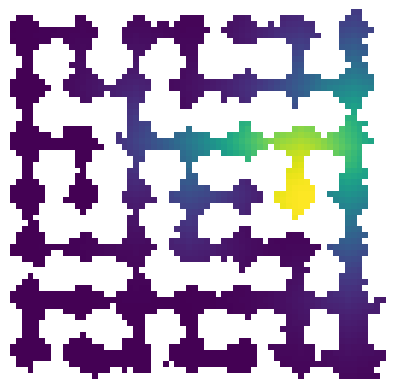

In [22]:
# geodesic ratemaps
# here we generate a networkx graph and
# for each 'place cell' we consider its 
from GridModels.code.maze import representations as mr
import networkx as nx
from scipy.sparse.csgraph import shortest_path
from scipy.spatial.distance import cdist
import pandas as pd

distance_metric = 'geodesic'
sigma = 4.0

method = 'gaussian' #gaussian or diff_of_gaussians
dog_ratio = 3/2 #diff_of_gaussians ratio

pos = pd.read_csv('./GridModels/data/trajectories/mEC_2.maze_1.train.htsv', sep='\t')
np.random.seed(42)
pixel_maze, bin_mask = mr.get_pixel_maze(pos)
#binx, biny = bin_mask.shape
print(bin_mask.shape)
#nx gives us a nested dictionary with 
distances = nx.all_pairs_shortest_path_length(pixel_maze)
n_pos = bin_mask.shape[0]*bin_mask.shape[1]
#simplest is a place cell for every position. 
# later add sampling of locations within the boundary and compute distances via nearest node.
#for i, (source, distance_dict) in enumerate(distances):
#    P[:,i] = [x for x in distance_dict.values()]
G = pixel_maze
nodes = [x for x in pixel_maze.nodes()]
A = nx.to_scipy_sparse_array(G, nodelist=nodes, weight="weight", format="csr")
if distance_metric == 'geodesic':
    D = shortest_path(A, directed=G.is_directed(), unweighted=False)*10  # D[i, j] is distanceplt.imshow(D)
elif distance_metric == 'euclidean':
    centers = np.array([x for x in nx.get_node_attributes(pixel_maze,'position').values()])
    D = cdist(centers,centers)
      
def gaussian(distance, sigma = sigma):
    return np.exp(-(distance**2)/(2*sigma**2))

def diff_of_gaussians(distance, sigma = sigma, dog_ratio = dog_ratio):
    small_gaussian = np.exp(-(distance**2)/(2*sigma**2))
    big_gaussian = (1/dog_ratio**2)*np.exp(-(distance**2)/(2*(dog_ratio*sigma)**2))
    normalising_constant = dog_ratio**2/(dog_ratio**2-1)
    return normalising_constant*(small_gaussian-big_gaussian)

if method == 'gaussian':
    P = gaussian(D)
elif method == 'diff_of_gaussians':
    P = diff_of_gaussians(D)
    
n_place_cells = 512
subset_idx = np.random.choice(np.arange(len(P)), n_place_cells)
P = P[:,subset_idx] #(n_pos, n_place_cells)
#ratemaps = P.T.reshape(n_place_cells, bin_mask.shape[0],bin_mask.shape[1]) #(n_place_cells, n_xbins,_ybins)

# plot an example ratemap
ratemap = bin_mask.copy().astype(dtype=np.float32)
ratemap[bin_mask==0] = np.nan
ratemap[bin_mask ==1] = P[:,1]
plt.imshow(ratemap.T, origin = 'lower')
plt.axis('off')

### Successor representation place coding

(-0.5, 63.5, -0.5, 62.5)

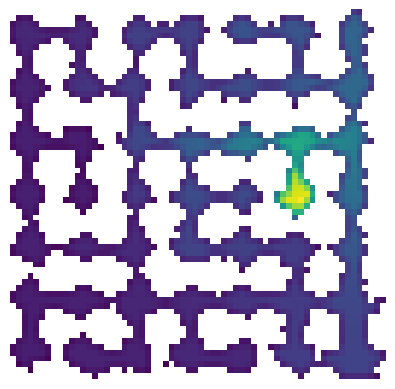

In [28]:
## Successor representation place coding

from GridModels.code.models import successor_representation as sr
sr_matrix, pixel_maze = sr.get_SR_from_bin_mask(bin_mask, discount_factor = 0.9999)

#plot example ratemap
ratemap = bin_mask.copy().astype(dtype=np.float32)
ratemap[bin_mask==0] = np.nan
ratemap[bin_mask ==1] = sr_matrix[1415,:]
plt.imshow(ratemap.T, origin = 'lower')
plt.axis('off')


In [ ]:
#test plot grid cells
SR_PCA_DF, varExp = sr.get_SR_PCA_df(pd.DataFrame(sr_matrix), 100)



In [67]:
SR_PCA_DF.to_numpy()

array([[ 2.78806490e+01,  6.53919479e+01,  6.31852782e+01, ...,
        -3.79047163e-04,  3.53124533e-03, -2.67089830e-02],
       [ 2.78665138e+01,  6.53556466e+01,  6.31162166e+01, ...,
        -3.71013151e-03,  5.58518728e-03, -4.30080005e-02],
       [ 2.71189578e+01,  6.34475777e+01,  5.96088052e+01, ...,
        -2.46650427e-04, -7.07615338e-02,  8.95869661e-03],
       ...,
       [-2.74543468e+01,  2.44222511e+01, -3.70548207e+01, ...,
         1.95728706e-01, -4.02442350e-01,  2.88240477e-01],
       [-2.74538985e+01,  2.44103630e+01, -3.70421660e+01, ...,
         2.10241038e-01, -4.44027756e-01,  3.17862363e-01],
       [-2.77460119e+01,  2.20104873e+01, -3.45006409e+01, ...,
         6.75512921e-02, -3.33696800e-01,  2.79758006e-01]])

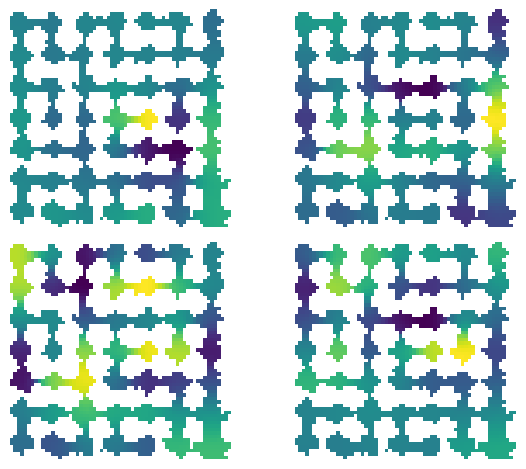

In [78]:
grid_cells = SR_PCA_DF.to_numpy()
fig, ax = plt.subplots(2,2)
for i, axis in enumerate(ax.flatten()):
    ratemap = bin_mask.copy().astype(dtype=np.float32)
    ratemap[bin_mask==0] = np.nan
    ratemap[bin_mask ==1] = grid_cells[:,i+12]
    axis.imshow(ratemap.T, origin = 'lower')
    axis.axis('off')
fig.tight_layout()

## Position Encoding Lagrangean 

Here we look at grid cells under the lens of pattern formation theory for the position encoding problem. Here we follow Sorscher et al. 2019.

$$\mathcal{E}(G,W) = \mid \mid P- \hat{P} \mid\mid^2_F, \qquad \hat{P}=GW $$

- $P\in \mathbb{R}^{n_x\times n_P}$ denotes place cell activations for different positions, such that $P_{x,i}$ is the activity of place cell $i$ at location $x$. 
- $G\in \mathbb{R}^{n_x\times n_G}$ denotes grid cell activations, such that $G_{x,j}$ is the activity of grid cell $j$ at location $x$.
- $W \in \mathbb{R}^n_G\times n_P$ represents readout weights, such that $W_{j,i}$ is the contribution of grid cell $j$ to place cell $i$ activity predictions.
- $\hat{P}\in \mathbb{R}^{n_x\times n_P}$ denotes predicted place cell activations.


Since we care mostly about $G$, we assume that $W$ is optimal for a fixed $G$:
$$ W := \text{argmin}_W \mathcal{E}(G,W) \approx (G^T G)^{-1}G^T P$$
noting that with some matrix algebra this implies
$$ W \approx G^{-1}(G^{T})^{-1} G^T P =  G^{-1} P \implies GW=\hat{P}$$

Now there's some more matrix hacks: the objective $\mathcal{E}$ is the same under linear transformations, so we can simplify it by a transformation $Z$ so that $G$ has orthonormal columns:

$$G\to GZ, W\to Z^{-1}W$$

which can be enforced via Lagrange multipliers:
$$ \mathcal{L}=\text{Tr} [G^T \sum G - \lambda(G^TG-I)], \qquad \sum=PP^T$$


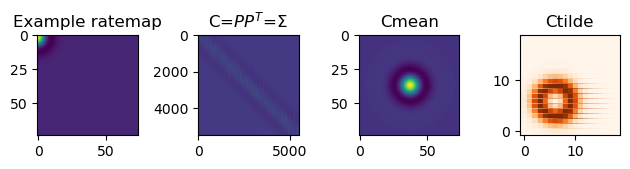

In [3]:
## Sorscher et al. 2023 replication ##
import matplotlib.pyplot as plt
import numpy as np
from GridModels.code.models import pattern_formation as pf

# we can get a view of covariance matrices also in fourier space
C, Cmean, Ctilde = pf.get_covariance_matrices(P, verbose=True)

#let's collect grid scores along the way:

gridscore_dict = {}

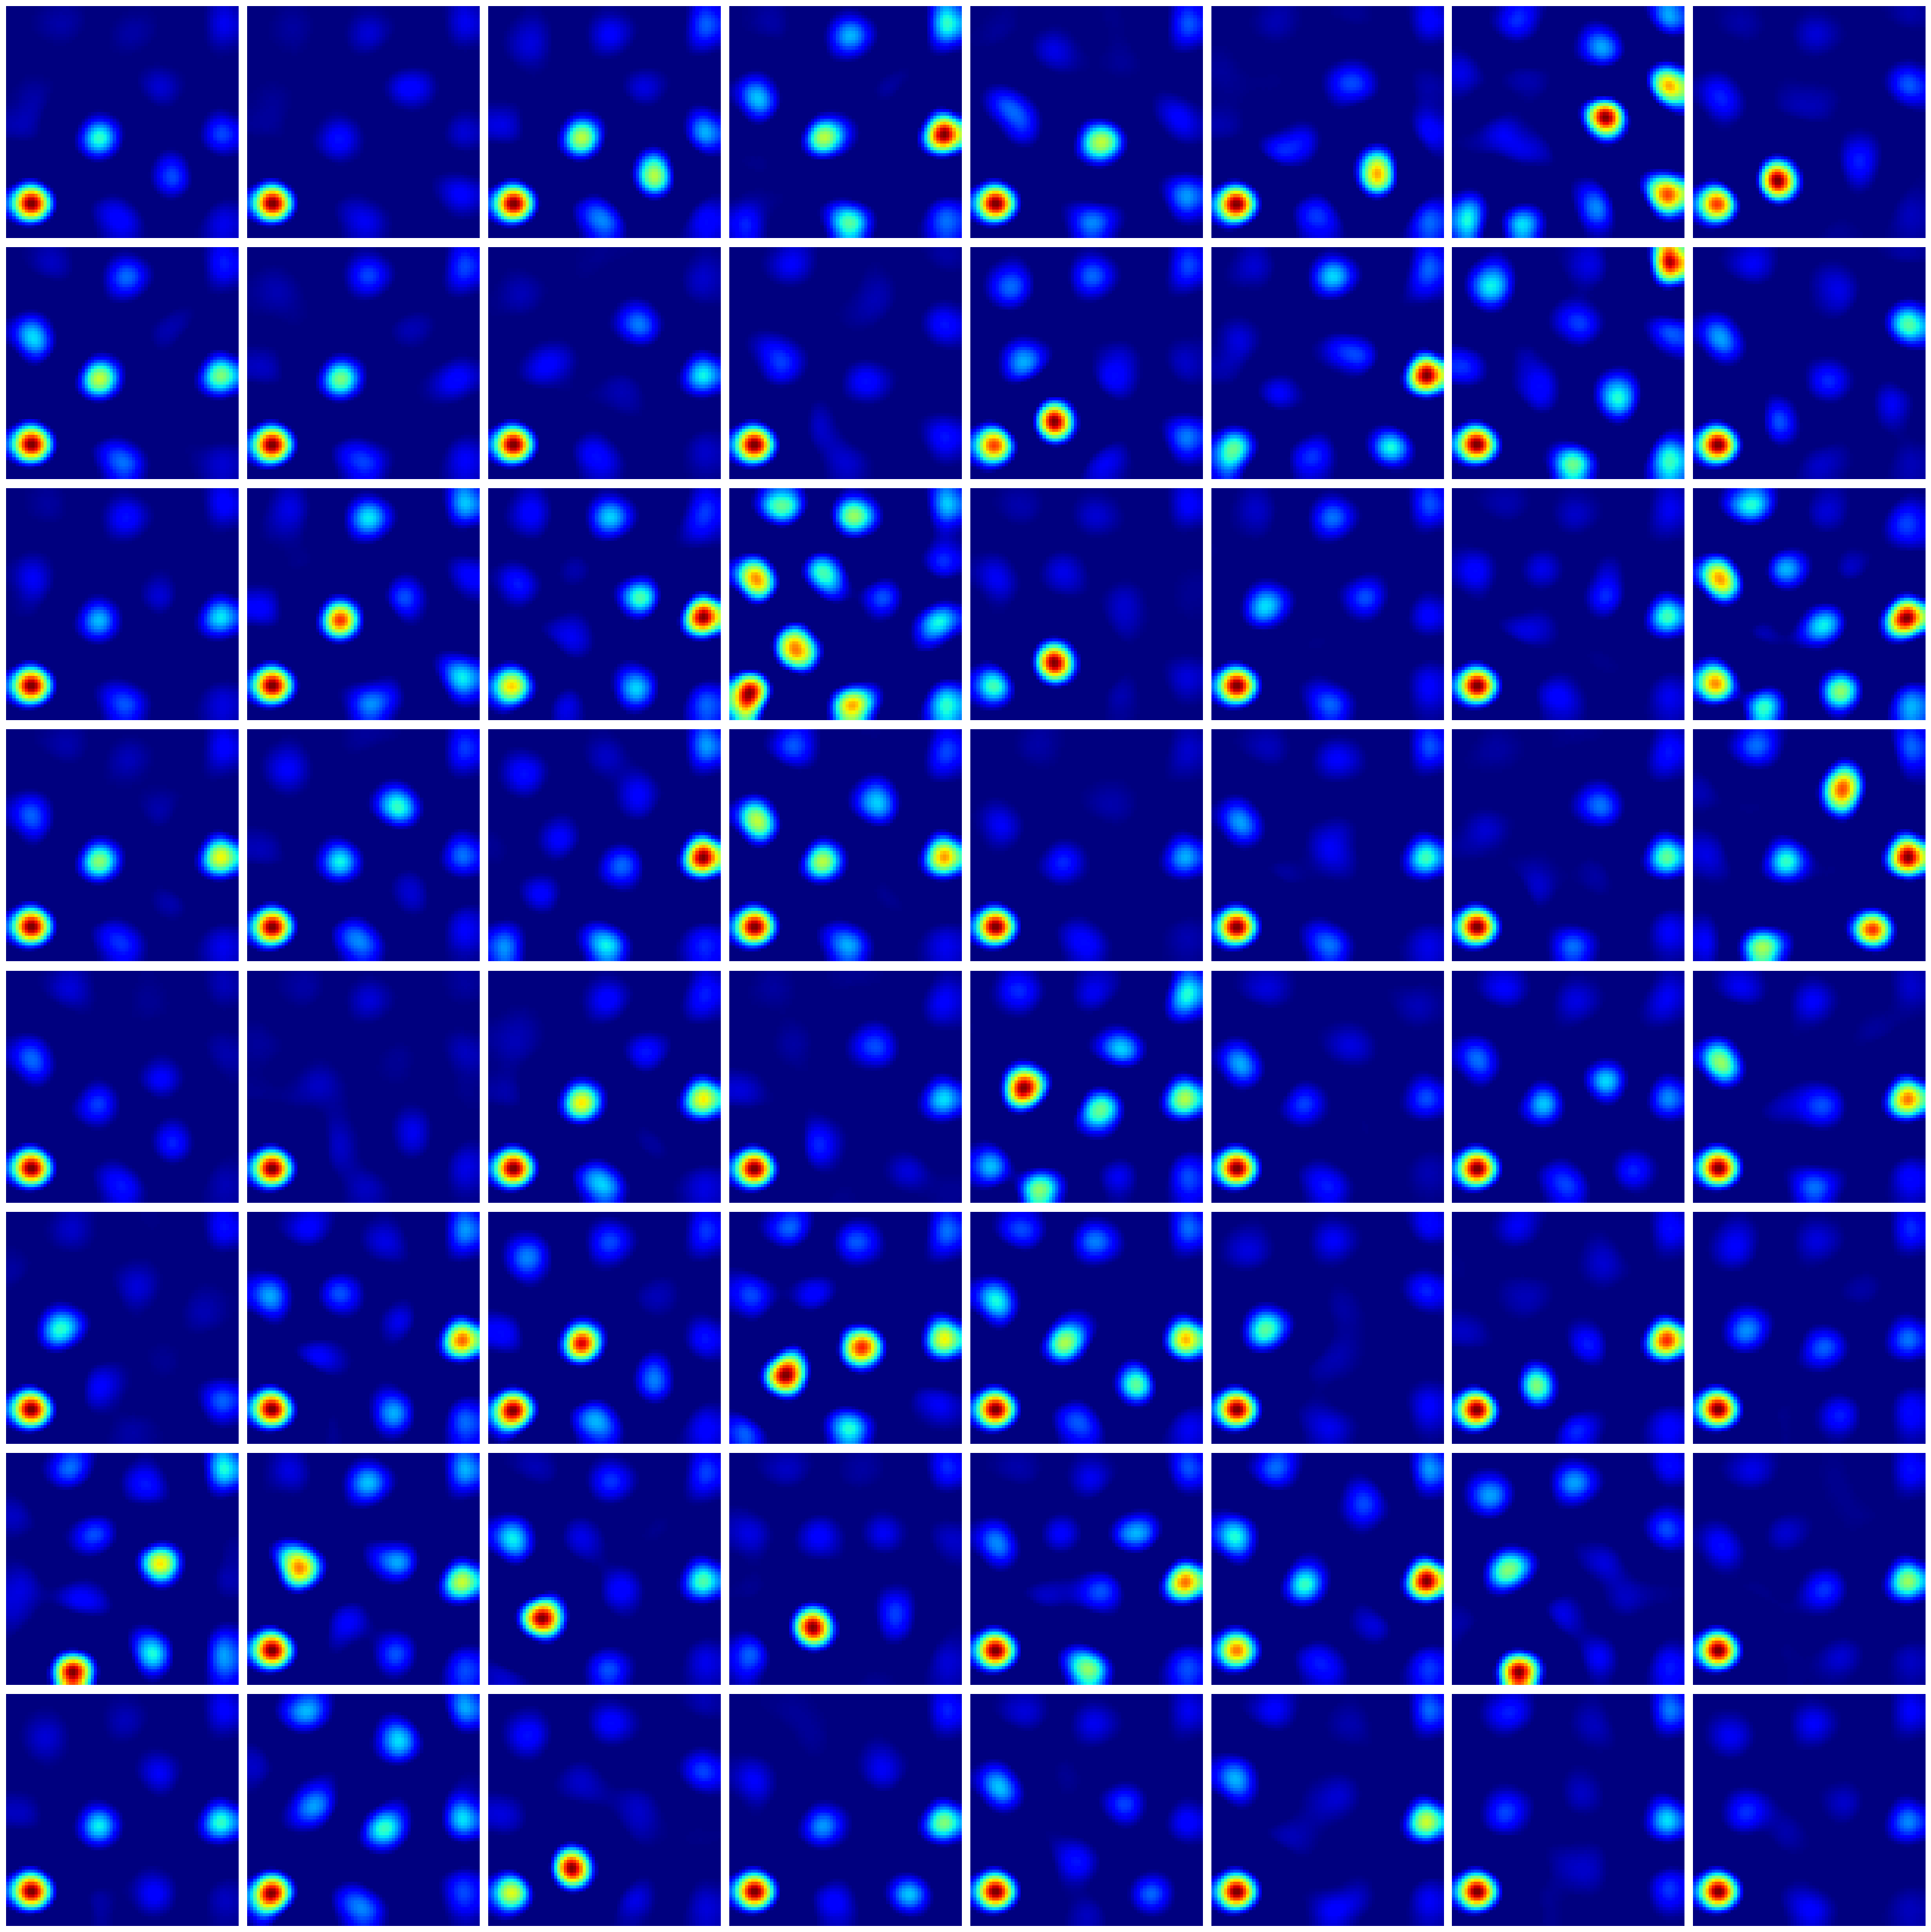

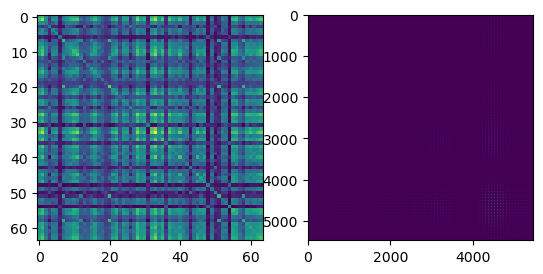

100%|██████████| 64/64 [00:03<00:00, 17.61it/s]


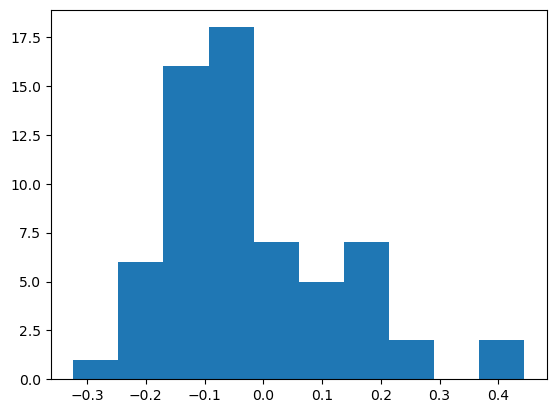

In [4]:
# Direct Lagrangian solution, gradient ascent
# here we do not make assumptions about relations between positions in fourier space.

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import svd

## SET THE NUMBER OF GRID CELLS ## 
Ng = 64

res = ratemaps.shape[1]
n_plot_rows = int(np.sqrt(Ng))
shifted_P = (P - P.mean(axis=1).reshape(-1,1))
normalised_P = (P/P.max(axis=1).reshape(-1,1))
positionsXplace_cells = P #shifted_P

results_dict = pf.optimize_lagrangean(positionsXplace_cells,Ng, 
                                  learning_rate = 3e-2,
                                  n_iterations = 1000,
                                  verbose = False)

G = results_dict['G']
fig, ax = plt.subplots(n_plot_rows,Ng//n_plot_rows, 
                            figsize = (4*Ng//n_plot_rows,4*n_plot_rows))
for i, axis in enumerate(ax.flatten()):
    axis.imshow(G[:,i].reshape(res,res), cmap = 'jet')
    axis.axis('off')
fig.tight_layout()
plt.show()#


#Lack of diversity in constraint is due to lacking orthogonality.
# somehow not really reaching the GTG = I constraint
fig, ax = plt.subplots(1,2)
G_normalised = G/G.mean(axis=0).reshape(1,-1)
ax[0].imshow(G_normalised.T@G_normalised) #this should be I
ax[1].imshow(G_normalised@G_normalised.T) #this should span multiple places, not just a single one.
plt.show()

## Grid scoring ## 
G_as_ratemaps = G.T.reshape(Ng,res,res)
G_as_ratemaps = G_as_ratemaps/G_as_ratemaps.mean(axis=(1,2)).reshape(G_as_ratemaps.shape[0],1,1)

grid_scores = gscoring.get_grid_scores(G_as_ratemaps, binx, biny)
gridscore_dict['lagrangian'] = grid_scores
plt.hist(grid_scores)
plt.show()

C_norm min: 0.0, max: 1.0


/nfs/nhome/live/cburns/.conda/envs/GridMaze/lib/python3.10/site-packages/sklearn/decomposition/_nmf.py:1742: ConvergenceWarning: Maximum number of iterations 1000 reached. Increase it to improve convergence.
  warnings.warn(


W shape: (5476, 64), G shape: (64, 5476)


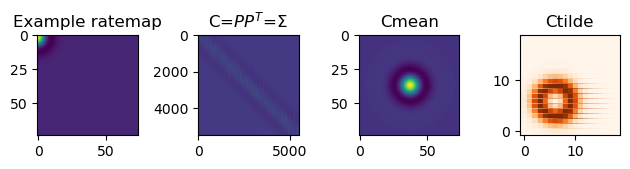

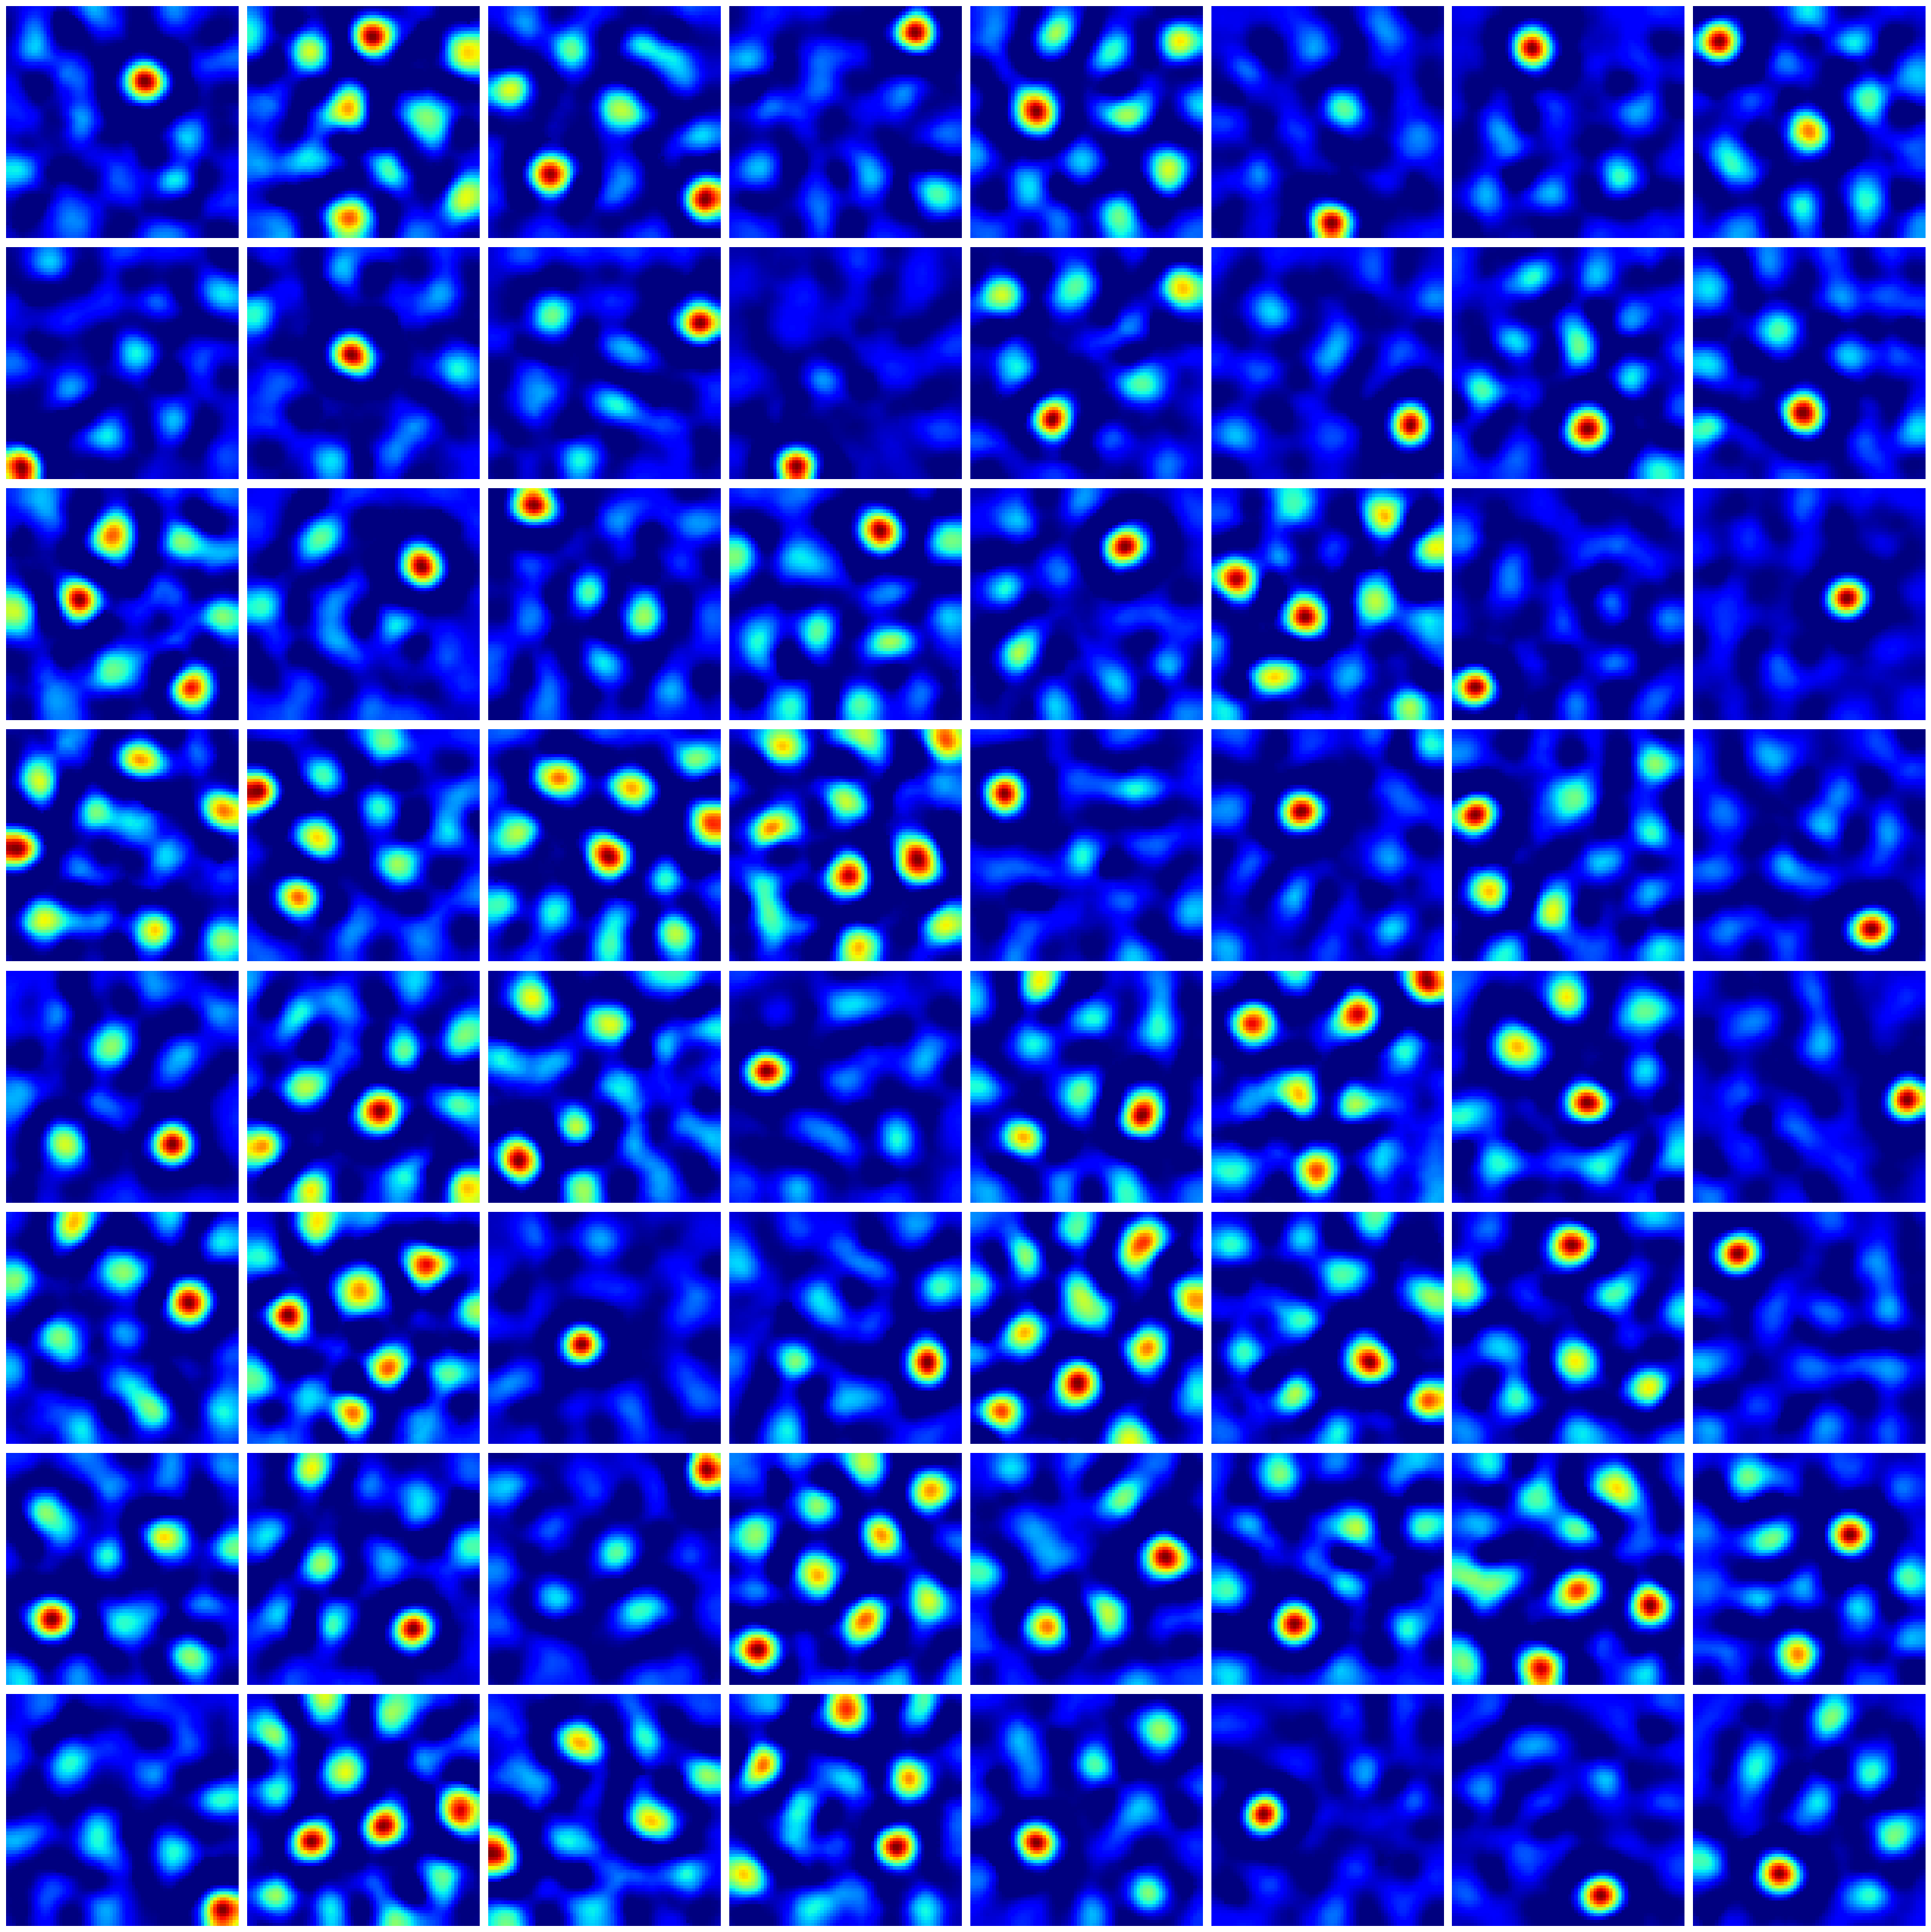

100%|██████████| 64/64 [00:03<00:00, 18.06it/s]


NameError: name 'gridscormMAMAmae_dict' is not defined

In [ ]:
# Standard NMF implementations
from sklearn.decomposition import NMF

C, Cmean, Ctilde = pf.get_covariance_matrices(P, verbose=True)

Ng = 64  # choose the number of components you want
n_plot_rows = int(np.sqrt(Ng))

#to help the nnmf, we normalise the C matrix:
C_min = C.min()
C_max = C.max()
C_norm = (C - C_min) / (C_max - C_min)
print(f"C_norm min: {C_norm.min()}, max: {C_norm.max()}")

# Perform non-negative matrix factorisation on C_norm
nmf = NMF(n_components=Ng, 
          init='random', 
          beta_loss = 'kullback-leibler', solver = 'mu',
          random_state=0, 
          max_iter=1000)
W = nmf.fit_transform(C_norm)
G = nmf.components_
print(f"W shape: {W.shape}, G shape: {G.shape}")

fig, ax = plt.subplots(n_plot_rows,Ng//n_plot_rows, 
                            figsize = (4*Ng//n_plot_rows,4*n_plot_rows))
for i, axis in enumerate(ax.flatten()):
    axis.imshow(G[i].reshape(res,res), cmap = 'jet')
    axis.axis('off')
fig.tight_layout()
plt.show()

## Grid scoring ## 

G_as_ratemaps = G.reshape(Ng,res,res)
grid_scores = gscoring.get_grid_scores(G_as_ratemaps, binx, biny)
gridscore_dict['NMF'] = grid_scores
plt.hist(grid_scores)


Using device: cpu
Starting grid search over 2 combinations...

Combination 1/2: λ_ortho=10.0000, λ_sparse=0.0010, λ_activity=1.0000, lr=0.0100
🌟 New best! Error: 3779.799818

Combination 2/2: λ_ortho=10.0000, λ_sparse=0.0010, λ_activity=1.0000, lr=0.1000
🌟 New best! Error: 2902.477907

Grid search completed!
Best recon error: 2902.477907
Best hyperparameters: {'lambda_ortho': 10, 'lambda_sparse': 0.001, 'lr': 0.1}

=== BEST RESULT SUMMARY ===
Reconstruction error: 2902.477907
Hyperparameters: lambda_ortho=10, lambda_sparse=0.001, lr=0.1


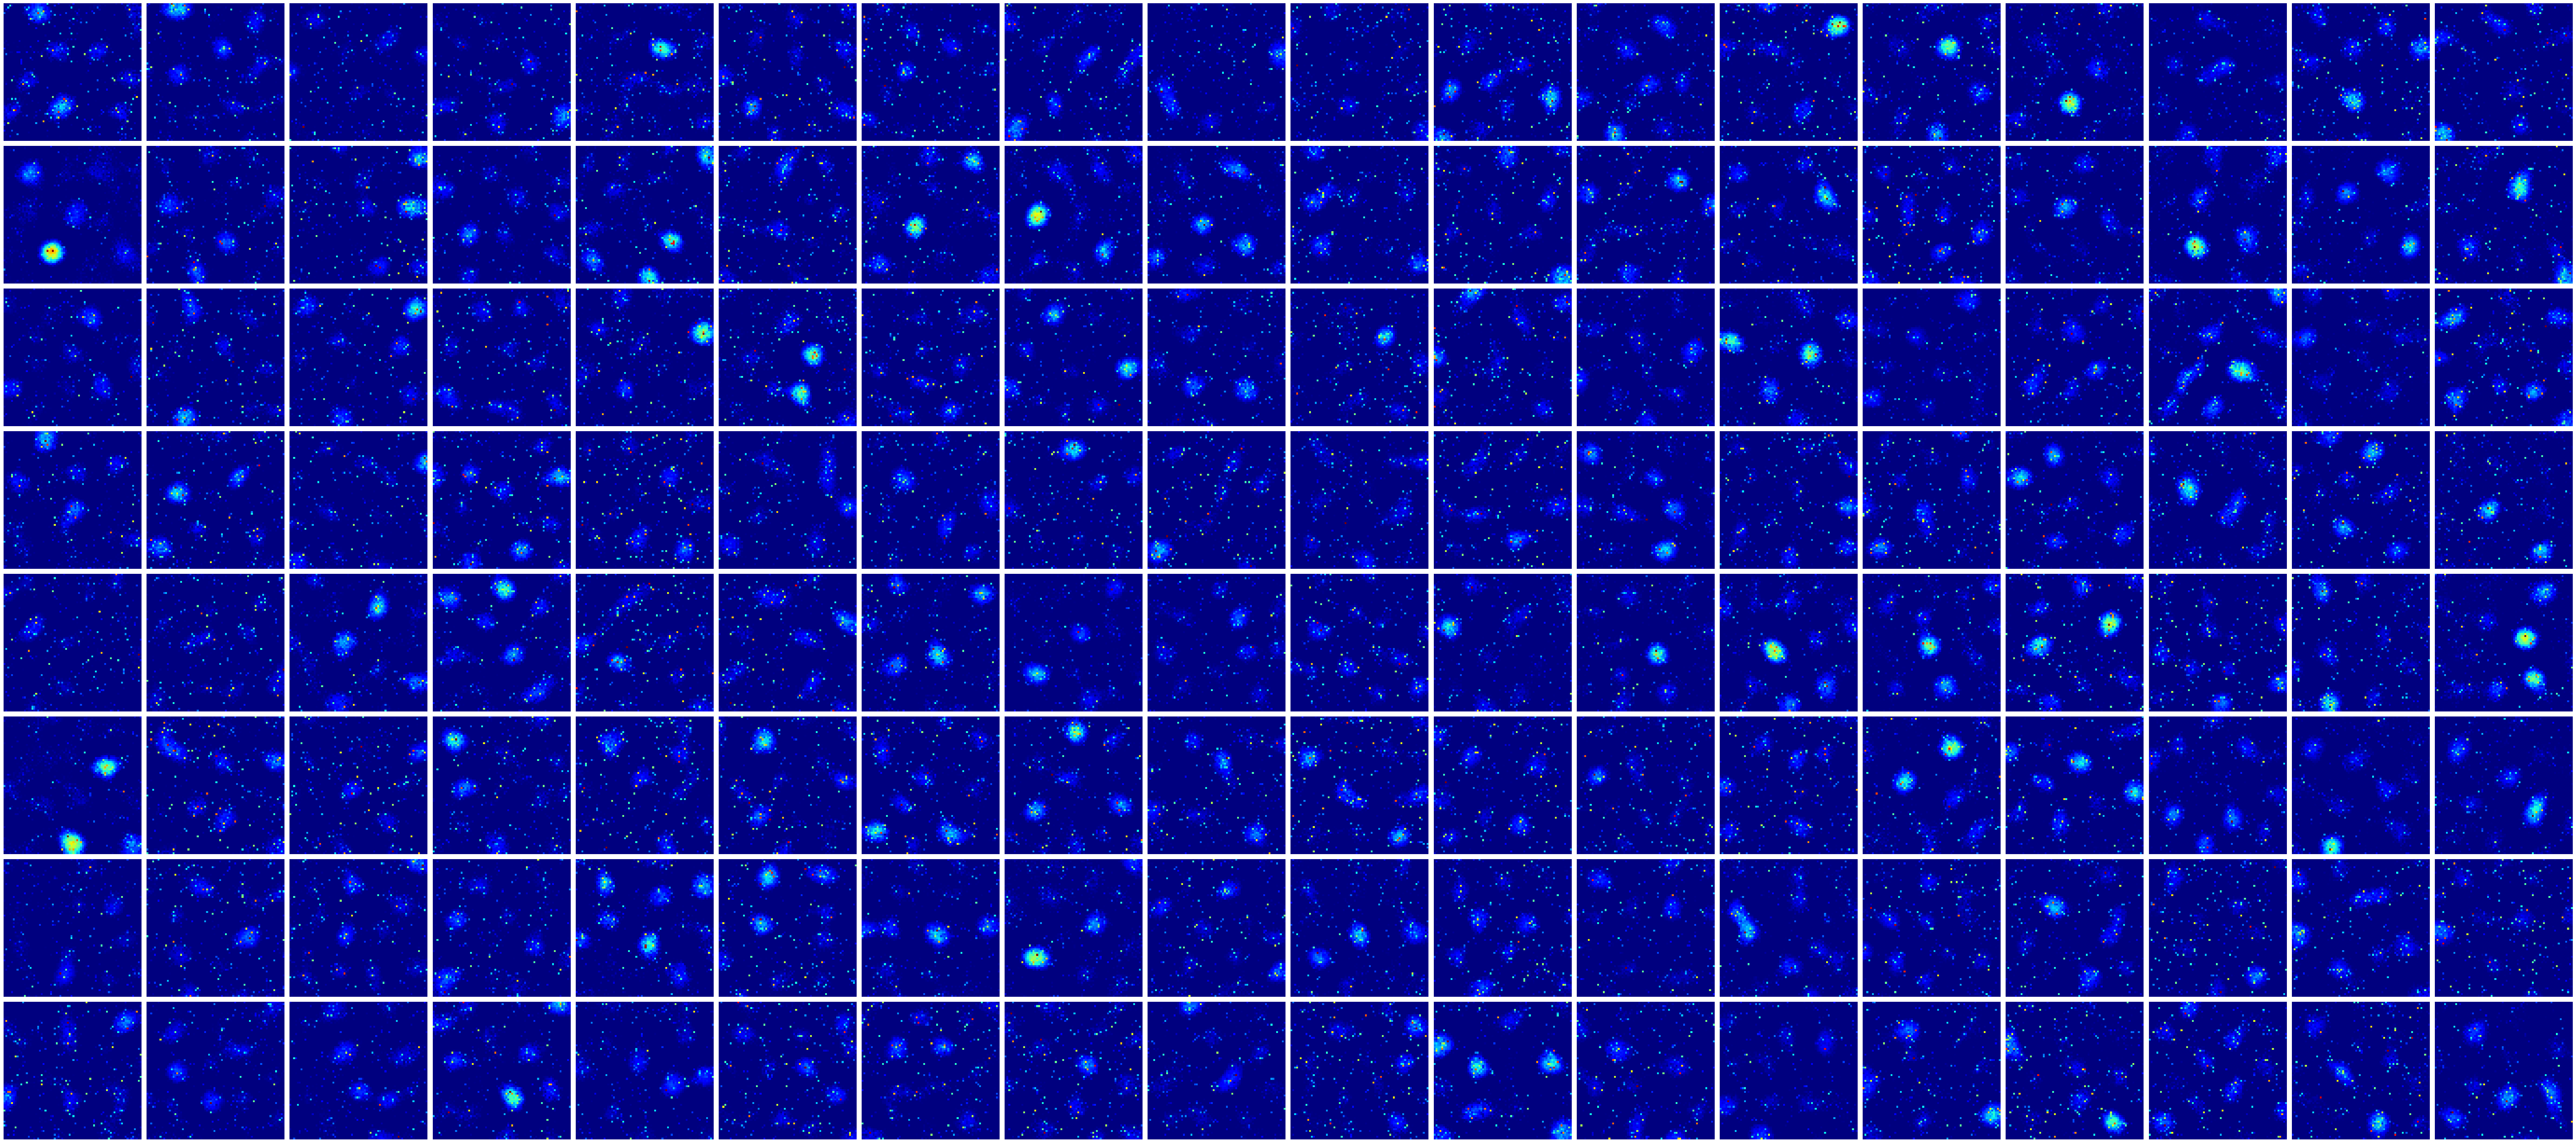

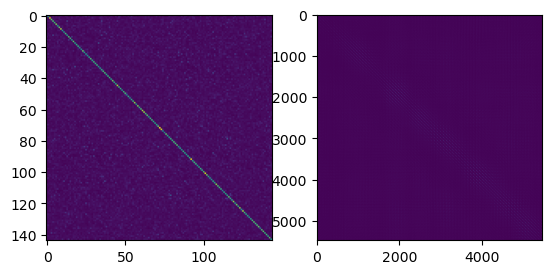

100%|██████████| 144/144 [00:07<00:00, 18.78it/s]


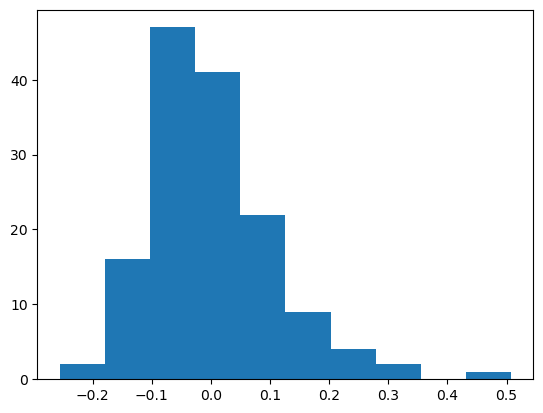

In [9]:
# pytorch autograd attempt #
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from itertools import product

def optimize_position_encoding(P, Ng, ortho=False, sparse=False, nonneg=False,
                               activity_constrained = False, 
                               lambda_ortho=1.0, lambda_sparse=0.1, lambda_activity = 0.01,
                               lr=0.01, epochs=1000, device='cpu', verbose=True):
    """
    Optimize grid cell activations (G) and readout weights (W) for position encoding.
    
    Returns:
        G, W, final_recon_error
    """
    n_x, n_P = P.shape
    P = P.to(device)
    
    # Initialize parameters
    G = nn.Parameter(torch.randn(n_x, Ng, device=device))
    W = nn.Parameter(torch.randn(Ng, n_P, device=device))
    I = torch.eye(Ng, device=device)
    optimizer = optim.AdamW([G, W], weight_decay = 0,amsgrad=True, lr=lr)
    
    for epoch in range(epochs):
        optimizer.zero_grad()
        
        # Apply constraints
        if nonneg:
            G.data = torch.relu(G.data)
            
        # Forward pass
        P_hat = G @ W
        reconstruction_loss = torch.norm(P - P_hat, p='fro')**2
        loss = reconstruction_loss
        
        # Add regularization terms
        if ortho:
            ortho_loss = torch.norm(G.T @ G - I, p='fro')**2
            loss += lambda_ortho * ortho_loss
            
        if sparse:
            sparse_loss =torch.norm(G, p='fro')  #G.var(axis=0).sum() 
            loss += lambda_sparse * sparse_loss

        if activity_constrained:
            activity_loss = (G**2).mean(axis=0).sum()
            loss += lambda_activity*activity_loss
            
        # Backpropagation
        try:
            loss.backward(retain_graph=False)
        except RuntimeError as e:
            print(f"Error at epoch {epoch}: {e}")
            print(f"loss.grad_fn at error: {loss.grad_fn}")
            break
            
        optimizer.step()
        
        # Projection for orthonormal constraint
        if ortho and not nonneg:
            with torch.no_grad():
                U, _, V = torch.svd(G.data)
                G.data = U @ V.T
        
        # Progress reporting
        if verbose and (epoch % 100 == 0 or epoch == epochs-1):
            recon_error = torch.norm(P - P_hat).item()
            msg = f'Epoch {epoch:4d} | Loss: {loss.item():.6f} | Recon: {recon_error:.6f}'
            if ortho:
                ortho_err = torch.norm(G.T @ G - I).item()
                msg += f' | Ortho: {ortho_err:.6f}'
            if verbose and epoch % 100 == 0:
                print(msg)
    
    # Final processing and error calculation
    with torch.no_grad():
        G_final = torch.relu(G) if nonneg else G
        if ortho and not nonneg:
            U, _, V = torch.svd(G_final)
            G_final = U @ V.T
            
        P_hat_final = G_final @ W
        final_error = torch.norm(P - P_hat_final).item()
    
    return G_final.detach(), W.detach(), final_error

def grid_search_hyperparams(P, Ng, ortho=False, sparse=False, nonneg=False,
                            activity_constrained=False,
                           lambda_ortho_list=[0.1, 1.0, 10.0],
                           lambda_sparse_list=[0.01, 0.1, 1.0],
                           lambda_activity_list= [1e-4],
                           lr_list=[0.001, 0.01, 0.1],
                           epochs=1000, device='cpu'):
    """
    Perform grid search over hyperparameters for position encoding optimization.
    
    Returns:
        results: List of dictionaries with all results
        best_params: Dictionary of best hyperparameters
        best_G, best_W: Best model parameters
    """
    results = []
    best_error = float('inf')
    best_params = None
    best_G, best_W = None, None
    
    # Create all hyperparameter combinations
    hyperparams = product(lambda_ortho_list, lambda_sparse_list, lambda_activity_list, lr_list)
    total_combinations = len(lambda_ortho_list) * len(lambda_sparse_list) * len(lambda_activity_list)*len(lr_list)
    
    print(f"Starting grid search over {total_combinations} combinations...")
    
    for i, (lo, ls, la, lr) in enumerate(hyperparams):
        print(f"\nCombination {i+1}/{total_combinations}: "
              f"λ_ortho={lo:.4f}, λ_sparse={ls:.4f}, λ_activity={la:.4f}, lr={lr:.4f}")
        
        # Run optimization with current hyperparameters
        G, W, error = optimize_position_encoding(
            P, Ng, ortho, sparse, nonneg, activity_constrained,
            lambda_ortho=lo, lambda_sparse=ls, lambda_activity=la, lr=lr, 
            epochs=epochs, device=device, verbose=False
        )
        
        # Record results
        result = {
            'lambda_ortho': lo,
            'lambda_sparse': ls,
            'lambda_activity':la,
            'lr': lr,
            'recon_error': error,
            'G': G,
            'W': W
        }
        results.append(result)
        
        # Update best results
        if error < best_error:
            best_error = error
            best_params = {'lambda_ortho': lo, 'lambda_sparse': ls, 'lr': lr}
            best_G, best_W = G, W
            print(f"🌟 New best! Error: {error:.6f}")
        else:
            print(f"Error: {error:.6f} (Best: {best_error:.6f})")
    
    print("\nGrid search completed!")
    print(f"Best recon error: {best_error:.6f}")
    print(f"Best hyperparameters: {best_params}")
    
    return results, best_params, best_G, best_W

if __name__ == "__main__":
    # Configuration
    Ng = 144  # Example dimensions
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print(f"Using device: {device}")
    
    # Generate synthetic place cell activations
    torch.manual_seed(42)
    P_torch = torch.tensor(shifted_P).to(device)
    
    # Grid search configuration
    lambda_ortho_list = [10]  # Orthonormality regularization strengths
    lambda_sparse_list = [1e-3]#[1e-2,1e-3]       # Sparsity regularization strengths
    lambda_activity_list = [1]#[1e-2, 1e-3]    #activity regularisation strengths
    lr_list = [1e-2, 0.1]                 # Learning rates
    epochs = 1000                              # Epochs per run
    
    # Run grid search (with all constraints enabled)
    results, best_params, best_G, best_W = grid_search_hyperparams(
        P_torch, Ng,
        ortho=True,    # Enforce orthonormal G
        sparse=False,   # Enforce sparse G
        nonneg=True,   # Enforce non-negative G
        activity_constrained=True,
        lambda_ortho_list=lambda_ortho_list,
        lambda_sparse_list=lambda_sparse_list,
        lambda_activity_list = lambda_activity_list,
        lr_list=lr_list,
        epochs=epochs,
        device=device
    )
    
    # Print best results summary
    print("\n=== BEST RESULT SUMMARY ===")
    print(f"Reconstruction error: {min(r['recon_error'] for r in results):.6f}")
    print(f"Hyperparameters: lambda_ortho={best_params['lambda_ortho']}, "
          f"lambda_sparse={best_params['lambda_sparse']}, lr={best_params['lr']}")
    
    # You can access all results through the 'results' list
    # Each entry contains: hyperparams, recon_error, and model parameters
    
G = np.maximum(best_G.cpu().numpy(),0)
fig, ax = plt.subplots(n_plot_rows,Ng//n_plot_rows, 
                            figsize = (4*Ng//n_plot_rows,4*n_plot_rows))
for i, axis in enumerate(ax.flatten()):
    axis.imshow(G[:,i].reshape(res,res), cmap = 'jet')
    axis.axis('off')
fig.tight_layout()
plt.show()#

#Lack of diversity in constraint is due to lacking orthogonality.
# somehow not really reaching the GTG = I constraint
fig, ax = plt.subplots(1,2)
G_normalised = G/G.mean(axis=0).reshape(1,-1)
ax[0].imshow(G_normalised.T@G_normalised) #this should be I
ax[1].imshow(G_normalised@G_normalised.T) #this should span multiple places, not just a single one.
plt.show()

## Grid scoring ## 

G_as_ratemaps = G.T.reshape(Ng,res,res)
G_as_ratemaps = G_as_ratemaps/G_as_ratemaps.mean(axis=(1,2)).reshape(G_as_ratemaps.shape[0],1,1)
grid_scores = gscoring.get_grid_scores(G_as_ratemaps, binx, biny)

plt.hist(grid_scores)
plt.show()

Optimizing...
                                            f: -1.170128e-01   |grad|: 1.341468e-01
acc TR+   k:     1     num_inner:     0     f: -2.898508e-01   |grad|: 2.258316e-01   negative curvature
acc TR+   k:     2     num_inner:     0     f: -7.864264e-01   |grad|: 3.342266e-01   negative curvature
acc       k:     3     num_inner:     0     f: -1.889867e+00   |grad|: 4.305020e-01   negative curvature
acc       k:     4     num_inner:     0     f: -2.641549e+00   |grad|: 4.603861e-01   negative curvature
acc TR-   k:     5     num_inner:     0     f: -2.944006e+00   |grad|: 5.103871e-01   exceeded trust region
acc       k:     6     num_inner:     0     f: -3.274992e+00   |grad|: 3.646186e-01   exceeded trust region
acc       k:     7     num_inner:     0     f: -3.473054e+00   |grad|: 3.310479e-01   exceeded trust region
acc       k:     8     num_inner:     0     f: -3.592187e+00   |grad|: 3.152617e-01   exceeded trust region
acc       k:     9     num_inner:     0     f: -3.

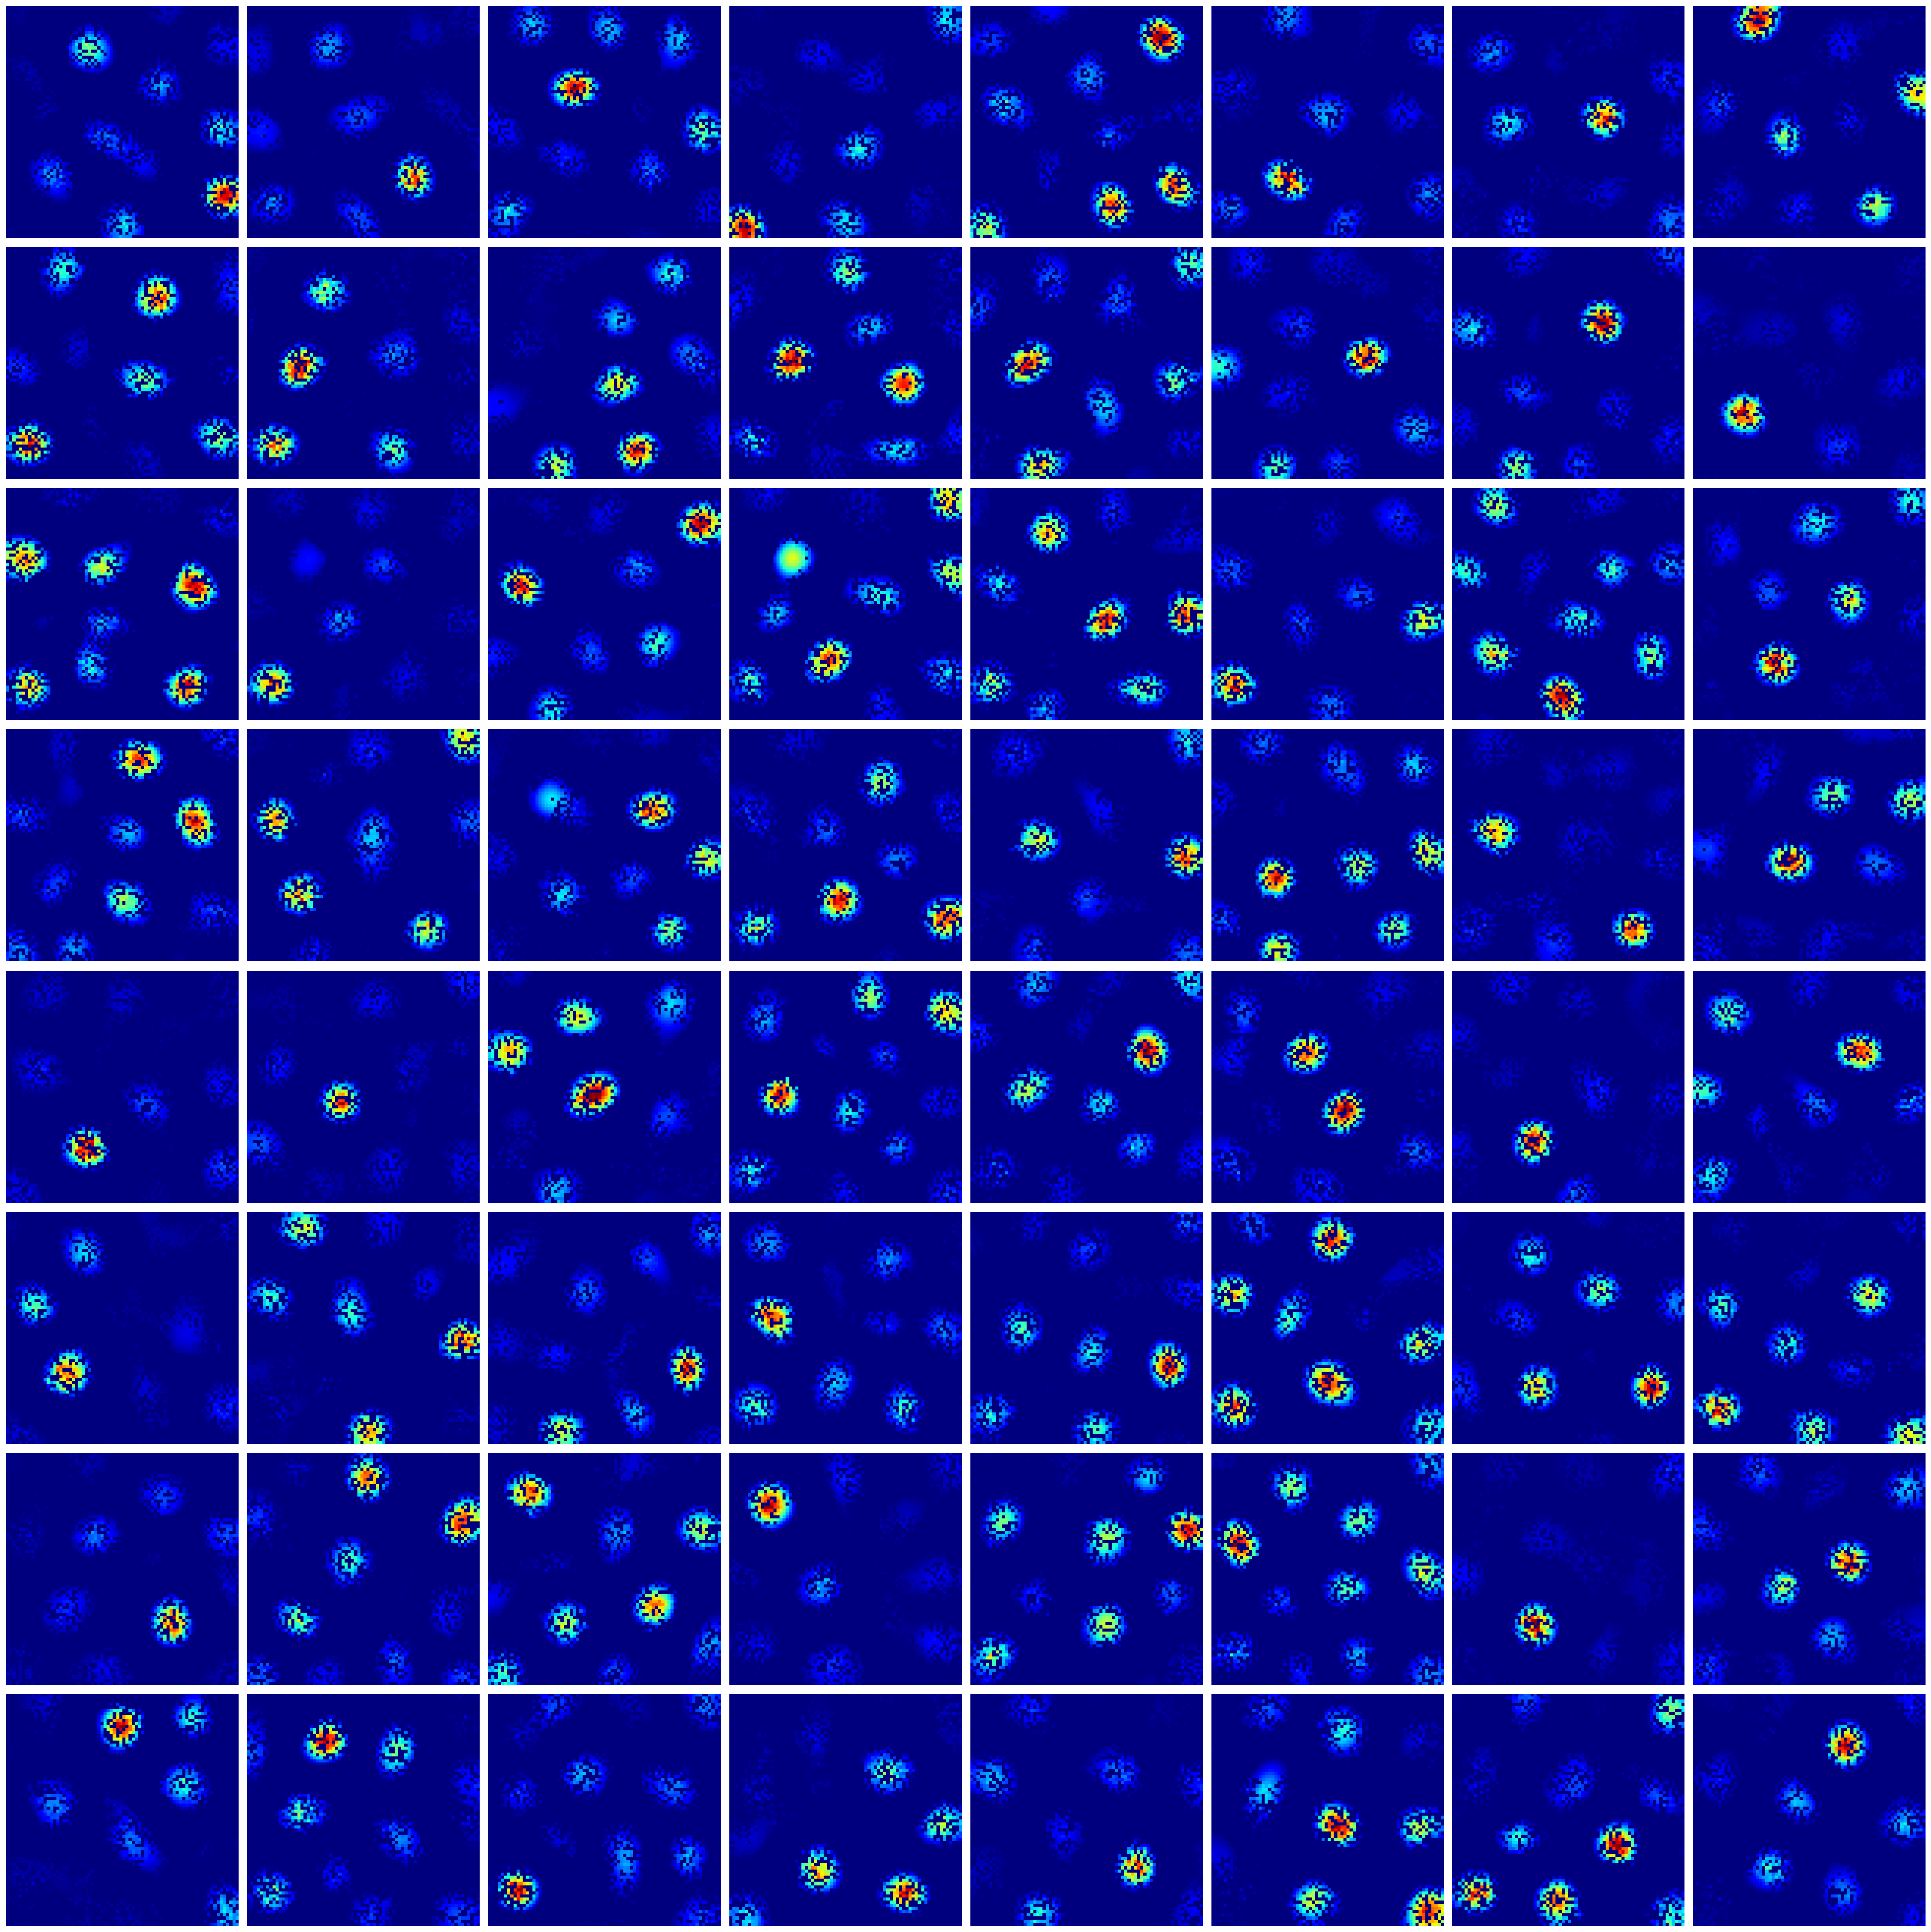

100%|██████████| 64/64 [00:03<00:00, 18.44it/s]


(array([ 3.,  1.,  1.,  6., 11., 10.,  9., 14.,  4.,  5.]),
 array([-0.04269062, -0.03687024, -0.03104986, -0.02522948, -0.01940911,
        -0.01358873, -0.00776835, -0.00194797,  0.0038724 ,  0.00969278,
         0.01551316]),
 <BarContainer object of 10 artists>)

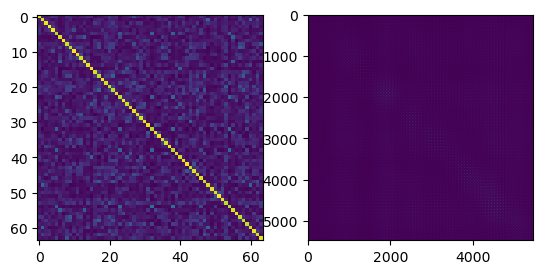

In [10]:
## AutoGrad attempt with pymanopt ##
import torch
#constrain the problem so that G.T@G = I always


def constrained_optimisation(P, n_grid_cells, max_iterations=5000):
    """
    Ultra-compact single function version.
    """
    import pymanopt
    from pymanopt.manifolds import Stiefel
    from pymanopt.optimizers import TrustRegions
    
    P_torch = torch.tensor(P, dtype=torch.float64)
    Sigma_torch = P_torch @ P_torch.T
    Sigma_torch = Sigma_torch/torch.linalg.norm(Sigma_torch)
    manifold = Stiefel(P.shape[0], n_grid_cells)
    
    @pymanopt.function.pytorch(manifold)
    def cost(G):
        G = torch.nn.functional.relu(G)
        return -torch.trace(G.T @ Sigma_torch @ G)
    
    problem = pymanopt.Problem(manifold, cost)
    optimizer = TrustRegions(max_iterations=max_iterations)
    
    G_init, _ = np.linalg.qr(np.random.randn(P.shape[0], n_grid_cells))
    result = optimizer.run(problem, initial_point=G_init)
    
    return result.point, result.point.T @ P  # Return G, W



Ng = 64
n_plot_rows = int(np.sqrt(Ng))

G, _ = constrained_optimisation(positionsXplace_cells, Ng, max_iterations = 100)
G = np.maximum(G,0)
fig, ax = plt.subplots(n_plot_rows,Ng//n_plot_rows, 
                            figsize = (4*Ng//n_plot_rows,4*n_plot_rows))
for i, axis in enumerate(ax.flatten()):
    axis.imshow(G[:,i].reshape(res,res), cmap = 'jet')
    axis.axis('off')
fig.tight_layout()
plt.show()

#plotting covariance
fig, ax = plt.subplots(1,2)
ax[0].imshow(G.T@G) #will be I
ax[1].imshow(G@G.T) #should be periodic over space


## Grid scoring ## 

G_as_ratemaps = G.reshape(Ng,res,res)
grid_scores = gscoring.get_grid_scores(G_as_ratemaps, binx, biny)
gridscore_dict['constrained'] = grid_scores
plt.hist(grid_scores)

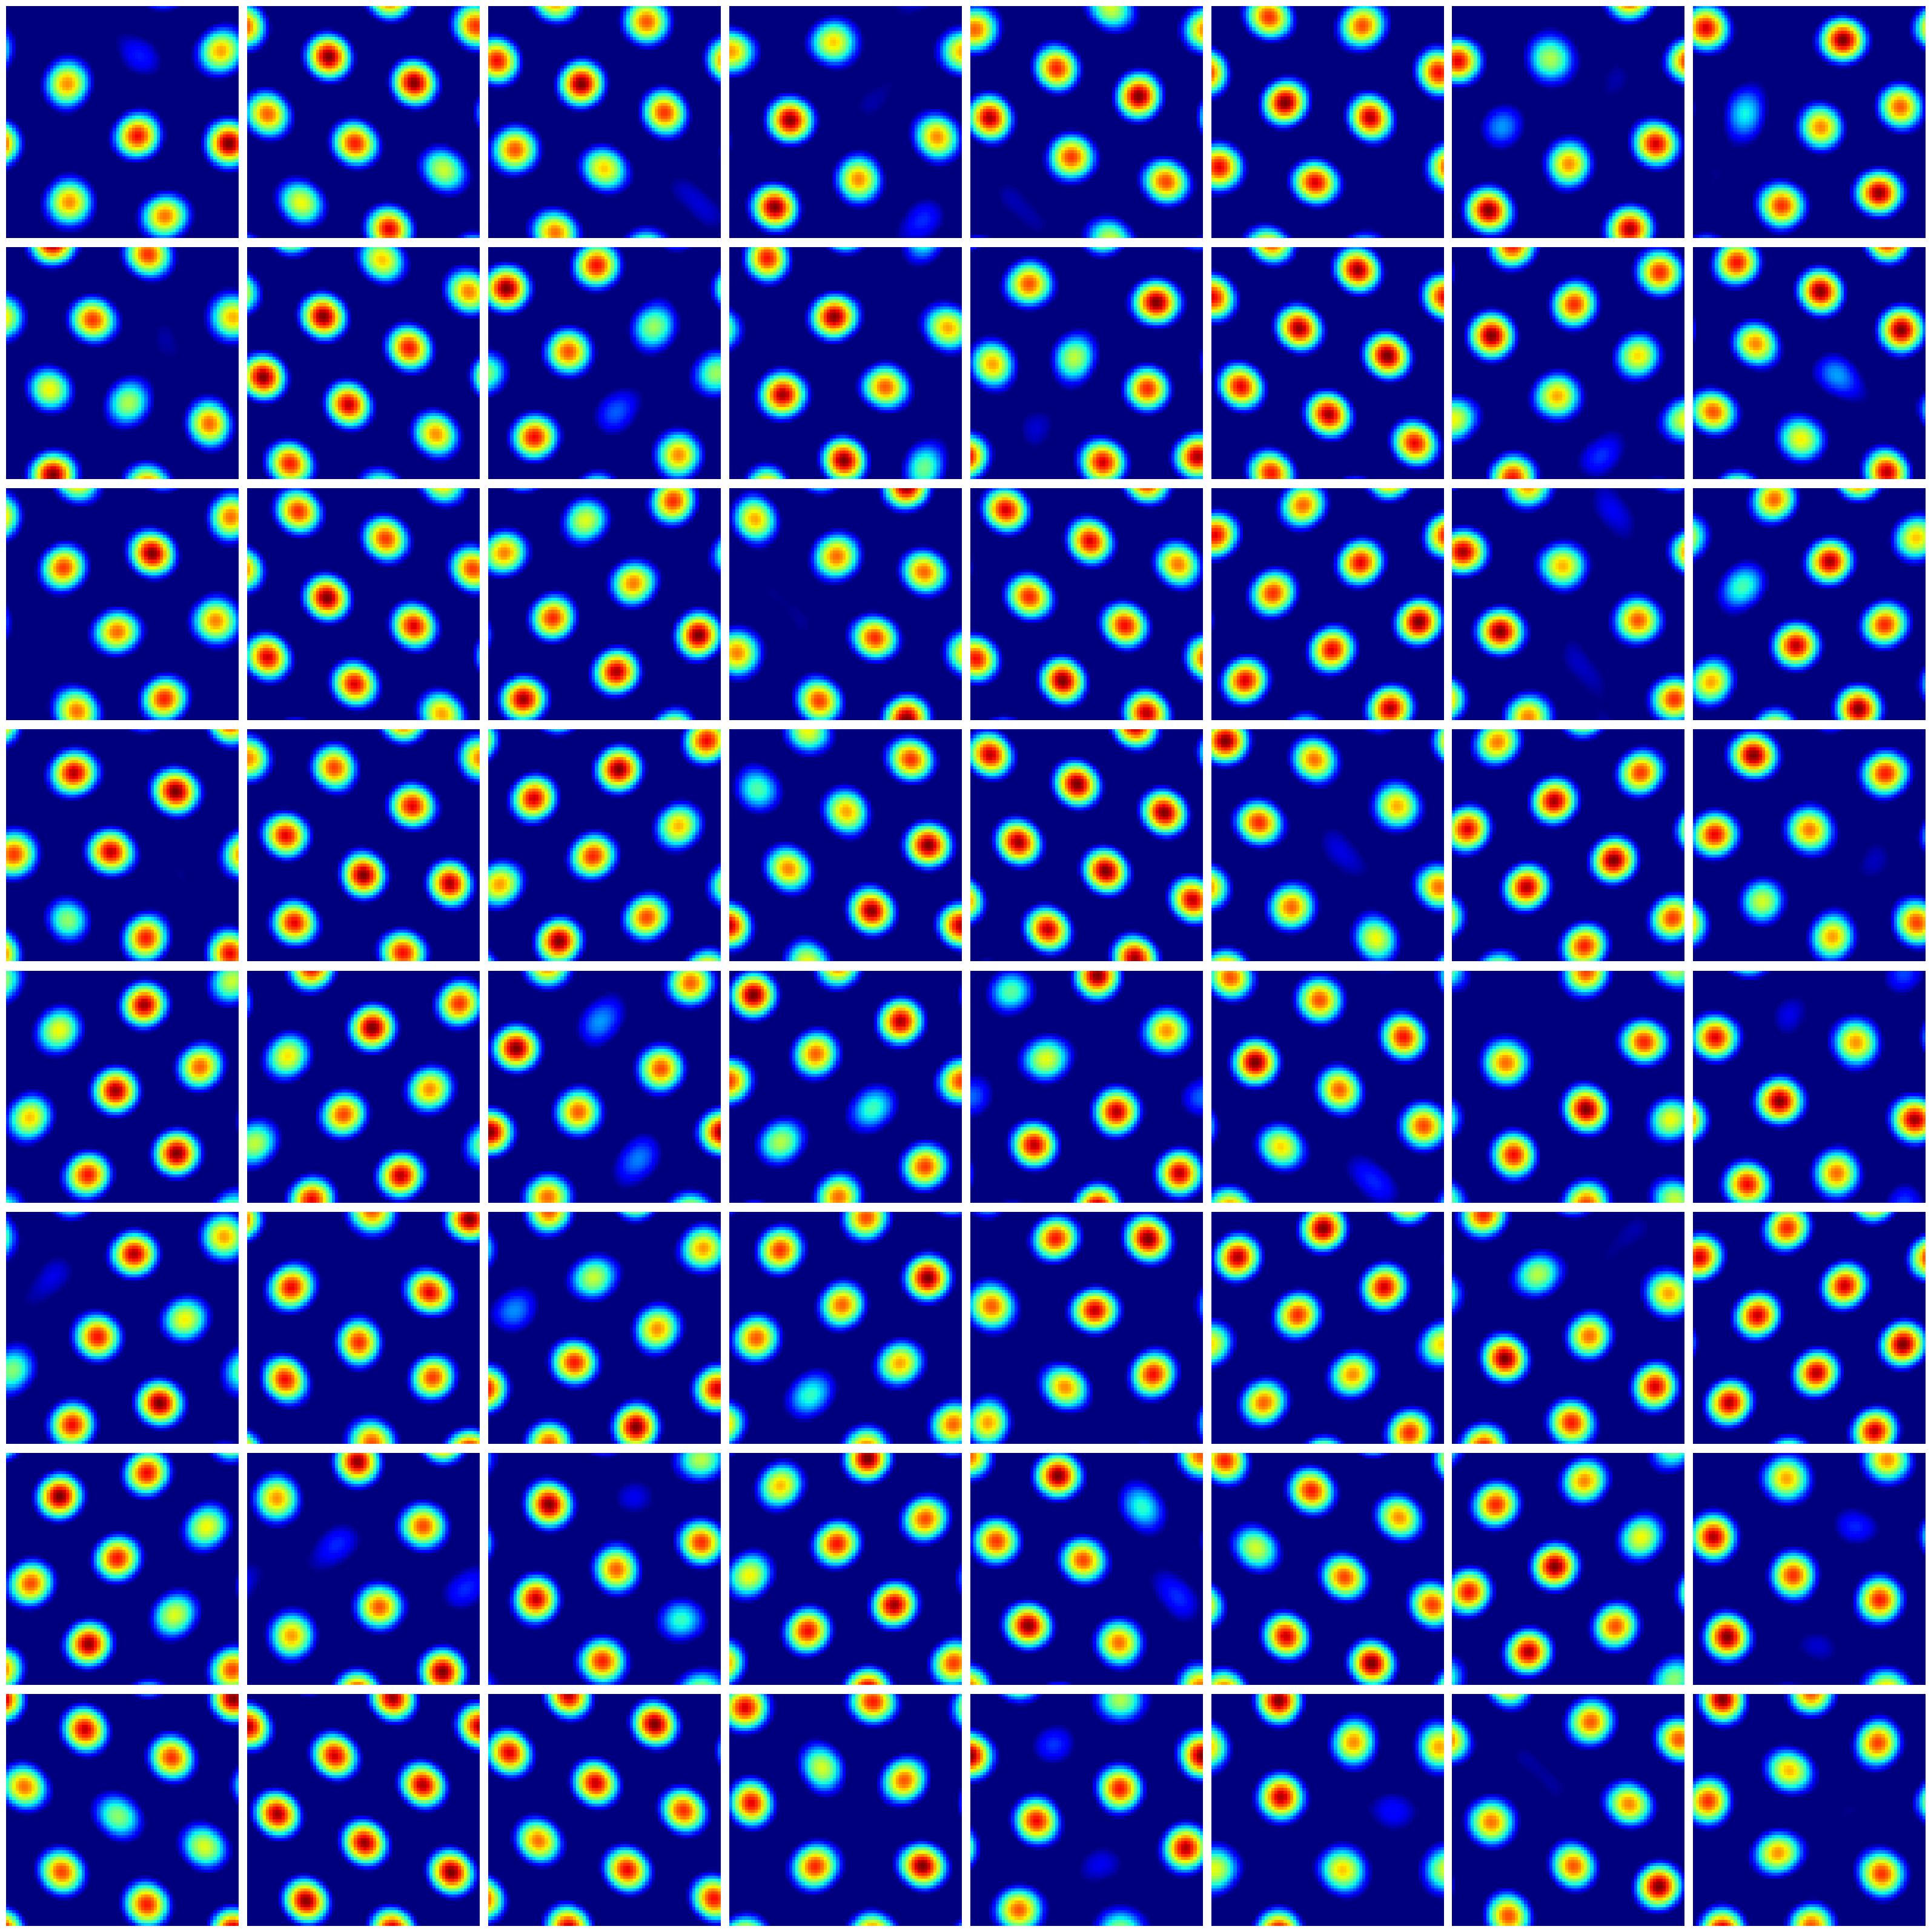

100%|██████████| 64/64 [00:03<00:00, 17.18it/s]


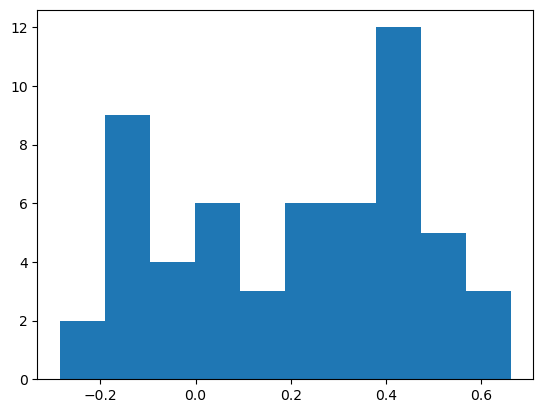

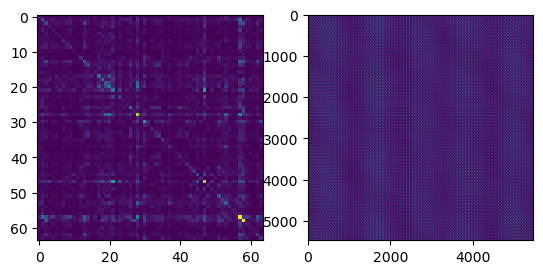

In [16]:
# Fast FFT solver:
# Symmetry-breaking nonlinearity (relu)

def convolve_with_C(g, Ctilde):
    '''
    Convolves the input g with the kernel C
    '''
    gtilde = np.fft.fft2(g, [res, res])
    gconv = np.real(np.fft.ifft2(gtilde*Ctilde))
    gconv = np.roll(np.roll(gconv, res//2+1, axis=1), res//2+1, axis=2)
    
    return gconv

def relu(x):
    return np.maximum(x,0)

Ng = 8**2
n_plot_rows = int(np.sqrt(Ng))
T = 1000
lr = 5e-5

#NOTE THAT THE VARIABILITY IN ORIENTATION / PHASE DEPENDS ON INITIAL RANDOM SEED
G = np.random.randn(Ng,res,res) * 1e-8
#repeated_init = np.random.randn(res,res)*1e-8
#G = np.stack([ repeated_init for _ in range(Ng)])

for i in range(T):
    G +=lr*(-G + convolve_with_C(G, Ctilde))
    G = relu(G)
    if i%100==99:
        fig, ax = plt.subplots(n_plot_rows,Ng//n_plot_rows, 
                               figsize = (4*Ng//n_plot_rows,4*n_plot_rows))
        for i, axis in enumerate(ax.flatten()):
            axis.imshow(G[i], cmap = 'jet')
            axis.axis('off')
        fig.tight_layout()
        plt.show()
        break
    if np.all(np.isnan(G[0])):
        print(f'all NaN at iteration {i}')
        break
            
            
## Grid scoring ## 
G_as_ratemaps =G.reshape(Ng,res,res)
grid_scores = gscoring.get_grid_scores(G_as_ratemaps, binx, biny)
gridscore_dict['fourier'] = grid_scores
plt.hist(grid_scores)
plt.show()

#plotting covariance 

fig, ax = plt.subplots(1,2)
reshaped_G = G.reshape(Ng,res*res) #(Ng,Nx)
ax[0].imshow(reshaped_G@reshaped_G.T) #should be I
ax[1].imshow(reshaped_G.T@reshaped_G) #should span coordinate space with periodicity

In [17]:
for x in gridscore_dict.values():
    print(len(x))

64
64
64
64


<Axes: ylabel='Count'>

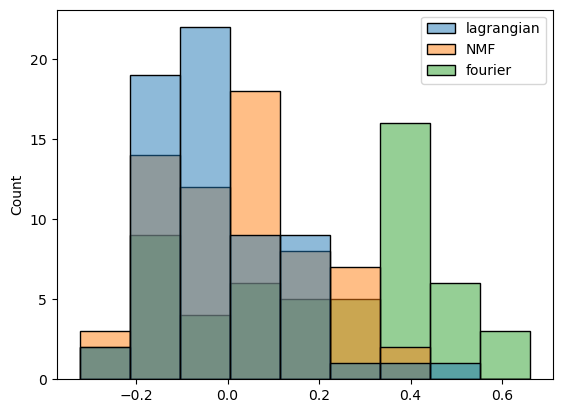

In [20]:
#let's compare gridscores!

import seaborn as sns
gridscore_df = pd.DataFrame(gridscore_dict)

sns.histplot(gridscore_df)

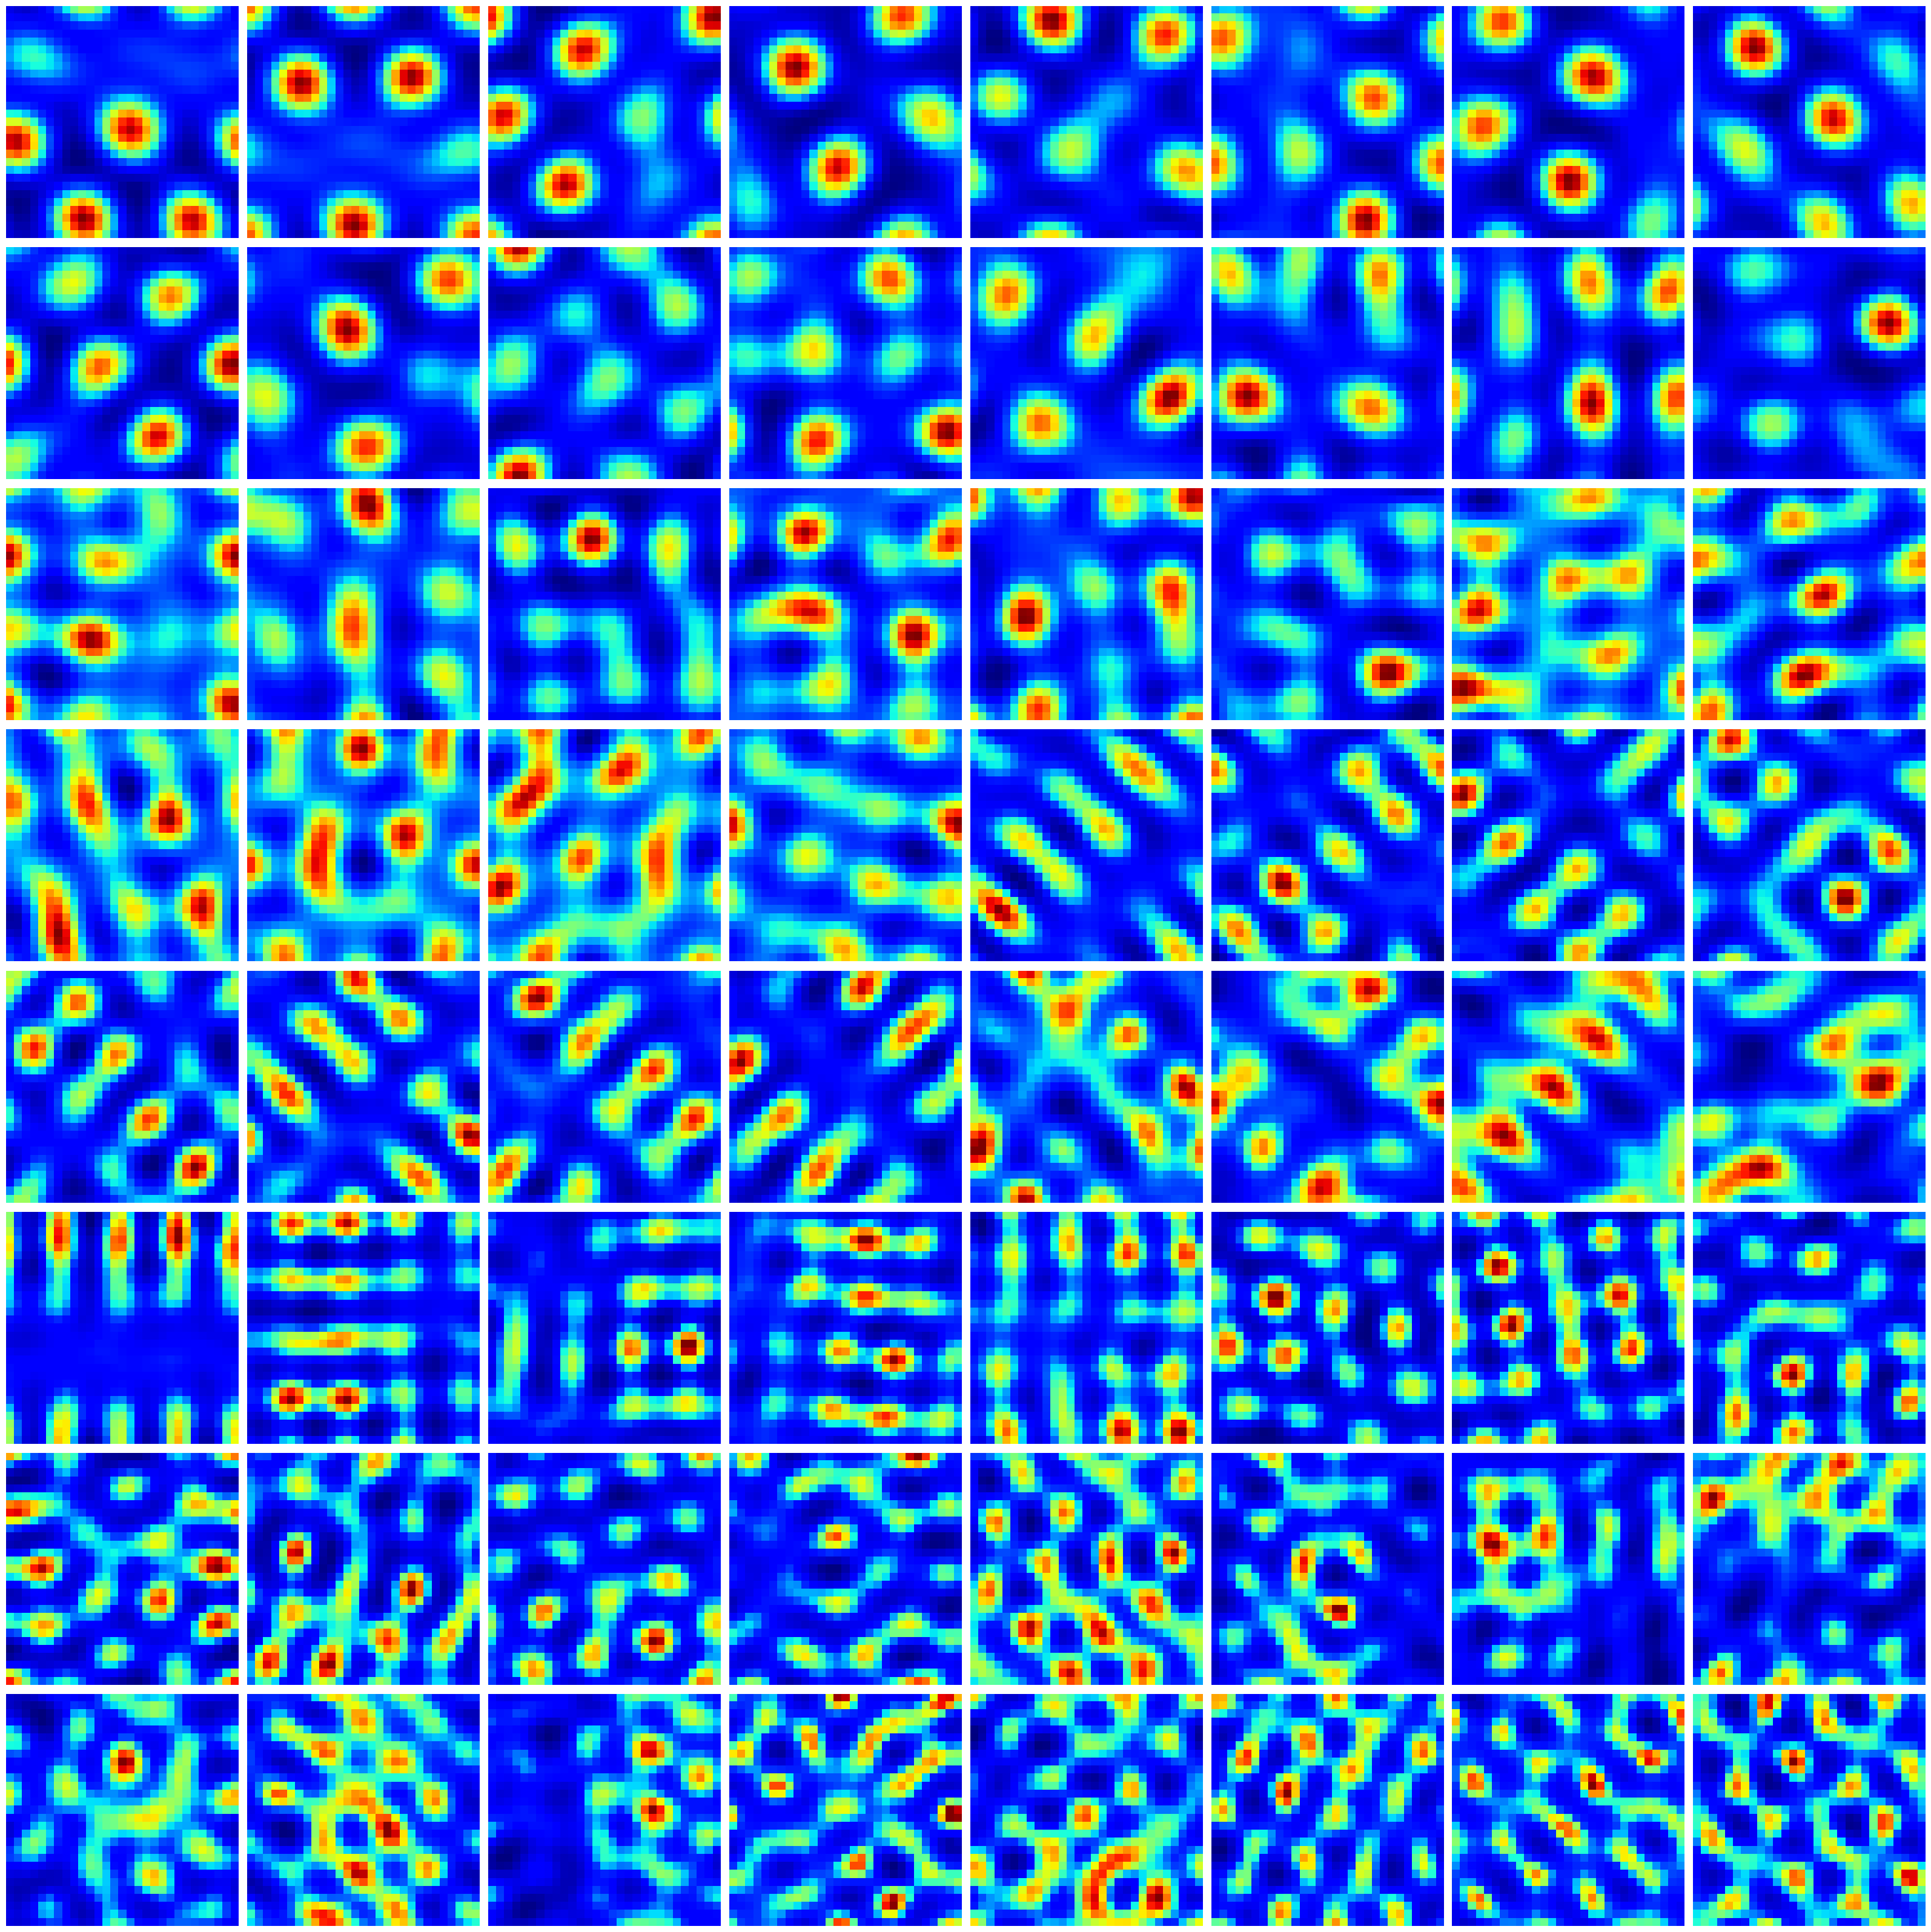

100%|██████████| 64/64 [00:01<00:00, 62.17it/s]


(array([10., 23., 15.,  6.,  6.,  1.,  1.,  0.,  0.,  2.]),
 array([-0.32431963, -0.21516903, -0.10601843,  0.00313217,  0.11228277,
         0.22143336,  0.33058396,  0.43973456,  0.54888516,  0.65803576,
         0.76718636]),
 <BarContainer object of 10 artists>)

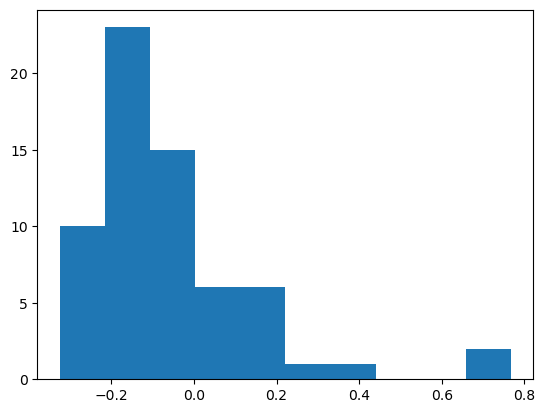

In [ ]:
## FFT and orthogonalised (multi-grid) ##
def phi(x,r):
    return np.maximum(r*x,0)

Ng = 8**2
n_plot_rows = int(np.sqrt(Ng))
r = 30
T = 5000
lr = 1.3e-6
G = np.random.randn(Ng,res,res) * 1e-8
#repeated_init = np.random.randn(res,res)*1e-8
#G = np.stack([ repeated_init for _ in range(Ng)])

for i in range(T):
    H = convolve_with_C(G, Ctilde)
    #H = phi(H,r) #this is not in the original code, but could be helpful to integrate non-negativity in the orthogonalisation penalty?
    Hr = H.reshape([Ng, -1])
    Gr = G.reshape([Ng, -1])
    oja = Gr.T.dot(np.tril(Gr.dot(Hr.T))).T.reshape([Ng,res,res])
    G_relu = phi(G,r)
    #we should balance constraints
    balance_scalar = np.abs(H-oja).max()/np.abs(G_relu).max() # 1 #np.min([H.max(),oja.max()])/G_relu.max() #(np.abs(H-oja).max()/np.abs(G_relu).max())
    G += lr * (H - oja + balance_scalar*G_relu) 
    
    if i%200==199:
        fig, ax = plt.subplots(n_plot_rows,Ng//n_plot_rows, 
                               figsize = (4*Ng//n_plot_rows,4*n_plot_rows))
        for i, axis in enumerate(ax.flatten()):
            axis.imshow(np.flip(G)[i], cmap = 'jet')
            axis.axis('off')
        fig.tight_layout()
        plt.show()
        break
    if np.all(np.isnan(G[0])):
        print(f'all NaN at iteration {i}')
        break
    
    
## Grid scoring ## 

grid_scores, sacs = gscoring.get_grid_scores(G)

plt.hist(grid_scores)
plt.show()

# inspecting covariance across grid cells and across positions #
fig, ax = plt.subplots(1,2)
reshaped_G = G.reshape(Ng,res*res) #(Ng,Nx)
ax[0].imshow(reshaped_G@reshaped_G.T) #should be I
ax[1].imshow(reshaped_G.T@reshaped_G) #should span coordinate space with periodicity


## Grid parameter estimation

Here we try to estimate scale, orientation, and phase of each cell (relative to idealised perfect hexagonal representation).

Using device: cuda


/ceph/behrens/peter_doohan/goalNav_mEC/experiment/code/GridModels/code/functions/hexagonal_gridcells.py:190: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:254.)
  offsets = torch.tensor(offsets).to(dtype=torch.float32, device = device)


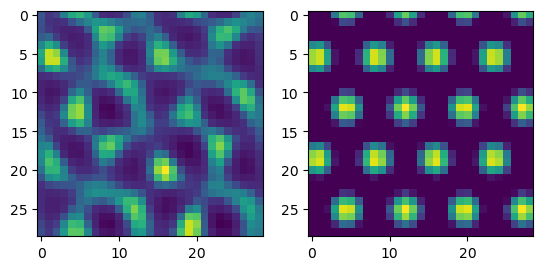

In [ ]:
from GridModels.code.functions import hexagonal_gridcells as hex
from GridMaze.analysis.metrics import get_grid_params as gparams
#normalised
G = G/G.max(axis=(1,2)).reshape(G.shape[0],1,1)
test_ratemap = G[0]
b2m = v2p.options.environment_scale/test_ratemap.shape[0]
fit_dict = gparams.fit_hexagonal_model2ratemap(test_ratemap, bins2metres = b2m )
best_ratemap = fit_dict['fitted_ratemap']

fig, ax = plt.subplots(1,2)
ax[0].imshow(test_ratemap)
ax[1].imshow(best_ratemap)

In [ ]:
params_dict = fit_dict
 #The transformation we do here is a linear map via basis vectors.
    #these vectors correspond
l1 = l2 = params_dict['scale'] #size of basis_1 = basis_2
theta= np.pi/3 #angle between vectors fixed for hexagonal model.
phi=np.rad2deg(params_dict['orientation']) #global orientation of grid pattern
#construct the basis vectors with some linear algebra
basis_1 = np.array([[l1*np.cos(phi)],
                    [-l1*np.sin(phi)]])
basis_2 = np.array([[l2*np.cos(theta-phi)],
                    [l2*np.sin(theta-phi)]])

#Now one lengthscale in the new basis coordinates 
# we simply want to project the orientations onto the torus


# Project points onto the torus
## we're getting closer thanks to https://math.stackexchange.com/questions/851136/are-there-2d-analogues-for-integer-division-and-modular-arithmetic
scales = np.array([np.linalg.norm(basis_1), np.linalg.norm(basis_2)])
centered_positions = np.array([0,0])# params_dict['offset']
shifted_positions = centered_positions + np.array([basis_1.max()/2,basis_2.max()/2]) #+ np.transpose(basis_1+basis_2)/2 #np.array([(20,0), (40,0), (10,17)])
shifted_positions = np.transpose(shifted_positions) # (2,n_pos)
basis_matrix = np.stack([basis_1,basis_2],axis=1).squeeze()
x = np.matmul(np.linalg.inv(basis_matrix),shifted_positions)
basis_multiples = np.floor(x)#+[np.linalg.norm(basis_1)/2,np.linalg.norm(basis_2)/2]
remainder = shifted_positions - (np.matmul(basis_matrix,basis_multiples))
# Now perform modulus operations, wrapping remainder coordinates back to each other
toroidal_coords = remainder.copy()
#toroidal_coords = np.matmul(np.linalg.inv(basis_matrix),toroidal_coords)
#toroidal_coords = toroidal_coords - np.array([[basis_1.max()/2],[basis_2.max()/2]])
toroidal_coords[0] = (remainder[0] % basis_1.max())/basis_1.max()*2*np.pi
toroidal_coords[1] = (remainder[1] % basis_2.max())//basis_2.max()*2*np.pi

print(toroidal_coords)

[1.59134249 0.        ]


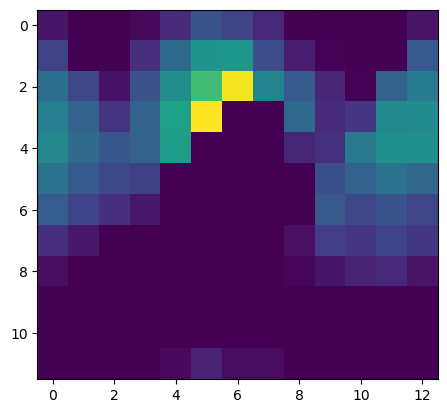

In [ ]:
# prompt: Smooth r from above by taking binned averages weighted by distance to centre in the original ratemap and with values equal to firingrate[1]

import numpy as np
import matplotlib.pyplot as plt

def toroidal_ratemap(firingrate, pos, basis_1, basis_2):
    """
    Smooths a ratemap by taking binned averages weighted by distance to the center.

    Args:
        firingrate: The firing rate at each position.
        pos: The positions corresponding to the firing rates.
        basis_1: First basis vector.
        basis_2: Second basis vector.
        n_bins: The number of bins to use for smoothing.

    Returns:
        A smoothed ratemap.
    """

    # Project points onto the torus
    periods = np.array([basis_1.max(), basis_2.max()]) #np.array([np.linalg.norm(basis_1), np.linalg.norm(basis_2)])
    centered_pos = pos - [pos[:,0].max()/2, pos[:,1].max()/2]
    n = centered_pos + periods / 2 #shifted position
    Q = np.stack([basis_1, basis_2], axis=0).squeeze()
    x = np.matmul(n, np.linalg.inv(Q))
    d = np.floor(x)
    r = n - np.matmul(d, Q)
    r[:, 0] = r[:, 0] % periods[0]
    r[:, 1] = r[:, 1] % periods[1]

    #scale_matrix = np.array([[1/basis_1.max(),0],[0,1/basis_2.max()]])
    #r = np.transpose(np.matmul(scale_matrix, np.transpose(r)))
    x_min, x_max = np.min(r[:, 0]), np.max(r[:, 0])
    y_min, y_max = np.min(r[:, 1]), np.max(r[:, 1])
    # Calculate the number of bins based on the data range and the desired bin size
    nxbins = int(x_max - x_min)
    nybins = int(y_max - y_min)
    #weight by distance to centre in original autocorrelogram
    distances = np.linalg.norm(centered_pos,axis=1)
    distances = distances/np.max(distances)+1
    dist_weight = 1/distances
    # Create a 2D histogram of the number of spikes (weighted histogram)
    ratemap, binx, biny = np.histogram2d(
        r[:,0], r[:,1], bins=[nxbins, nybins], weights=firingrate*dist_weight, #
        range=[[x_min, x_max], [y_min, y_max]]
    )

    occupancy, _, _ = np.histogram2d(r[:,0], r[:,1], bins=[nxbins, nybins], range=[[x_min, x_max], [y_min, y_max]])

    # Compute the firing rate (spikes per second) for each bin
    # Avoid division by zero by only dividing where occupancy > 0
    h = np.zeros_like(ratemap)
    valid_bins = occupancy > 0
    h[valid_bins] = ratemap[valid_bins] / occupancy[valid_bins]

    return h.T


def params2basis_vectors(params):
    '''Returns basis vectors from a parameters dictionary with 1, l2, theta, and phi'''
    #hard-coded trigonometry
    l1 = params['l1']
    l2=params['l2']
    theta=params['theta']
    phi=params['phi']
    basis_1 = np.array([[l1*np.cos(phi)],
                       [-l1*np.sin(phi)]])
    basis_2 = np.array([[l2*np.cos(theta-phi)],
                       [l2*np.sin(theta-phi)]])
    return basis_1, basis_2


basis_1,basis_2 = params2basis_vectors({'l1':params_dict['scale']/b2m,
                                        'l2':params_dict['scale']/b2m,
                                        'theta':np.pi/3,
                                        'phi':params_dict['orientation']})


def get_flattened_coords(N):
    """Generates flattened coordinates for a square meshgrid."""
    x = np.arange(N)
    y = np.arange(N)
    xv, yv = np.meshgrid(x, y)
    return np.stack((xv.flatten(), yv.flatten()), axis=1)
grid_positions = get_flattened_coords(test_ratemap.shape[0])

reshaped_ratemap = test_ratemap.reshape(test_ratemap.shape[0]*test_ratemap.shape[1])
gt_ratemap, params = hex.get_fast_hexagonal_rates(grid_positions, 
                                          [params_dict['scale']/b2m],
                                          [np.rad2deg(params_dict['orientation'])],
                                          offsets = [params_dict['offset']/b2m])
gt_ratemap = gt_ratemap.squeeze().cpu().numpy()

plt.imshow(toroidal_ratemap(gt_ratemap,
                            grid_positions,
                            basis_1,
                            basis_2))




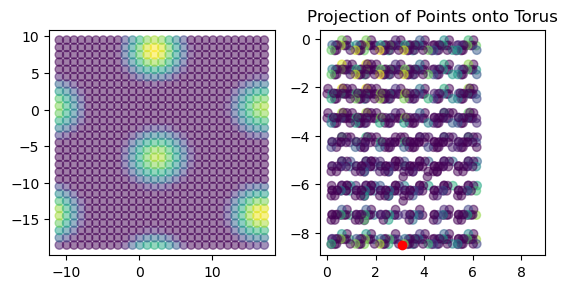

In [ ]:
# Example usage:
# Sample points

N = test_ratemap.shape[0]

points = np.random.rand(N**2, 2) * 100  # Example: 100 random points in a 10x10 square

# Define basis vectors (replace with your actual vectors)

basis_1,basis_2 = params2basis_vectors({'l1':params_dict['scale']/b2m,
                                        'l2':params_dict['scale']/b2m,
                                        'theta':np.pi/3,
                                        'phi':np.rad2deg(params_dict['orientation'])})


# Project points onto the torus
## we're getting closer thanks to https://math.stackexchange.com/questions/851136/are-there-2d-analogues-for-integer-division-and-modular-arithmetic
scales = np.array([np.linalg.norm(basis_1), np.linalg.norm(basis_2)])
centered_positions =  grid_positions -[grid_positions[:,0].max()/2,grid_positions[:,1].max()/2]
shifted_positions = centered_positions + np.array([basis_1.max()/2,basis_2.max()/2]) #+ np.transpose(basis_1+basis_2)/2 #np.array([(20,0), (40,0), (10,17)])
shifted_positions = np.transpose(shifted_positions) # (2,n_pos)
basis_matrix = np.stack([basis_1,basis_2],axis=1).squeeze()
x = np.matmul(np.linalg.inv(basis_matrix),shifted_positions)
basis_multiples = np.floor(x)#+[np.linalg.norm(basis_1)/2,np.linalg.norm(basis_2)/2]
remainder = shifted_positions - (np.matmul(basis_matrix,basis_multiples))
# Now perform modulus operations, wrapping remainder coordinates back to each other
toroidal_coords = remainder.copy()
#toroidal_coords = np.matmul(np.linalg.inv(basis_matrix),toroidal_coords)
#toroidal_coords = toroidal_coords - np.array([[basis_1.max()/2],[basis_2.max()/2]])
toroidal_coords[0,:] = remainder[0,:] % basis_1.max()
toroidal_coords[1,:] = remainder[1,:] % basis_2.max()

## mean per bin

#scale_matrix = np.array([[1/basis_1.max(),0],[0,1/basis_2.max()]])
#toroidal_coords = np.matmul(scale_matrix, toroidal_coords)


toroidal_offset =  toroidal_coords.min(axis=1) + toroidal_coords.max(axis=1)/2 ##((basis_1+basis_2)/2).squeeze()

# Plot the results
fig, ax = plt.subplots(1,2)
ax[0].scatter(shifted_positions[0,:], shifted_positions[1,:], c=reshaped_ratemap, label='Original Points', alpha=0.5)
ax[1].scatter(toroidal_coords[0,:],toroidal_coords[1,:], c=reshaped_ratemap, alpha=0.5)
ax[1].scatter(toroidal_offset[0],toroidal_offset[1], color='red')
ax[0].axis('square')
ax[1].axis('square')
ax[1].set_title("Projection of Points onto Torus")
#ax[1].grid(True)
plt.show()

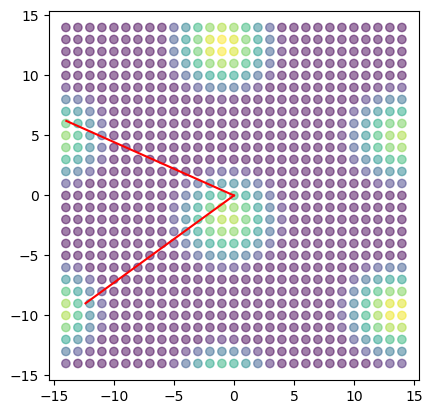

In [ ]:
#checking basis vectors
fig, ax = plt.subplots()
ax.scatter(centered_positions[:,0], 
           centered_positions[:,1], 
           c=reshaped_ratemap, 
           label='Original Points', 
           alpha=0.5)
ax.plot(np.array([0,basis_2[0,0]]),np.array([0,basis_2[1,0]]), color = 'red')
ax.plot(np.array([0,basis_1[0,0]]),np.array([0,basis_1[1,0]]), color = 'red')

ax.axis('square')
plt.show()

## SR representations



### Basic SR from a 2D grid-world (but fine-scale)

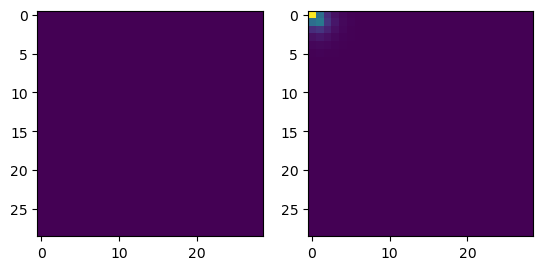

In [48]:
from GridModels.code.models import successor_representation as sr
from importlib import reload
import numpy as np
import matplotlib.pyplot as plt
reload(sr)
res = 29 #ratemap size
example_ratemap = np.ones((res,res))
bin_mask = ~np.isnan(example_ratemap)
sr_matrix, graph = sr.get_SR_from_bin_mask(bin_mask, 
                        discount_factor = 0.80)

fig, ax = plt.subplots(1,2)
ax[0].imshow(example_ratemap)
ax[1].imshow(sr_matrix[0].reshape(res,res))

0.0 % of bins unoccupied


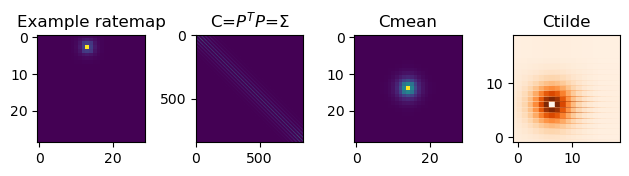

In [49]:
sr_ratemaps = np.stack([sr_matrix[i].reshape(res,res) for i in range(res*res)])

print(f'{round(np.mean(np.isnan(sr_ratemaps))*100,4)} % of bins unoccupied')
sr_ratemaps[np.isnan(sr_ratemaps)] = 1e-6 # set NaN to very small value. Seems to work? But probably wont for maze data
P = sr_ratemaps.reshape(sr_ratemaps.shape[0],sr_ratemaps.shape[1]*sr_ratemaps.shape[2])
## Before any of the C stuff, we need to rescale the ratemaps ##
n_ratemaps = sr_ratemaps.shape[0]
shifted_rm = (sr_ratemaps + np.abs(sr_ratemaps.min(axis = (1,2))).reshape(n_ratemaps,1,1))
sr_ratemaps = shifted_rm/shifted_rm.max(axis = (1,2)).reshape(n_ratemaps,1,1)
# ratemaps should have values between [0,1], so they should be shifted #
res = sr_ratemaps.shape[1]
C = P.T@P
Csquare = C.reshape(res,res,res,res)
Cmean = np.zeros([res,res])
n_additions = 0
for i in range(res):
    for j in range(res):
        Cmean += np.roll(np.roll(Csquare[i,j], -i, axis=0), -j, axis=1)
        n_additions +=1
Cmean = np.roll(np.roll(Cmean, res//2, axis=0), res//2, axis=1)/n_additions #fold the corners onto the center
# Fourier transform
Ctilde = np.fft.fft2(Cmean)
Ctilde[0,0] = 0

## plotting ##
fig, ax = plt.subplots(1,4)
ax[0].set(title = 'Example ratemap')
ax[0].imshow(sr_ratemaps[100])

ax[1].set(title = r'C=$P^TP$=$\Sigma$')
ax[1].imshow(C)

ax[2].set(title ='Cmean')
ax[2].imshow(Cmean)

ax[3].set(title = 'Ctilde')
width = 10
idxs = np.arange(-width+1, width)
x2, y2 = np.meshgrid(np.arange(2*width-1), np.arange(2*width-1))
ax[3].scatter(x2,y2,c=np.abs(Ctilde)[idxs][:,idxs], s=600, cmap='Oranges', marker='s')
ax[3].axis('square')
fig.tight_layout()

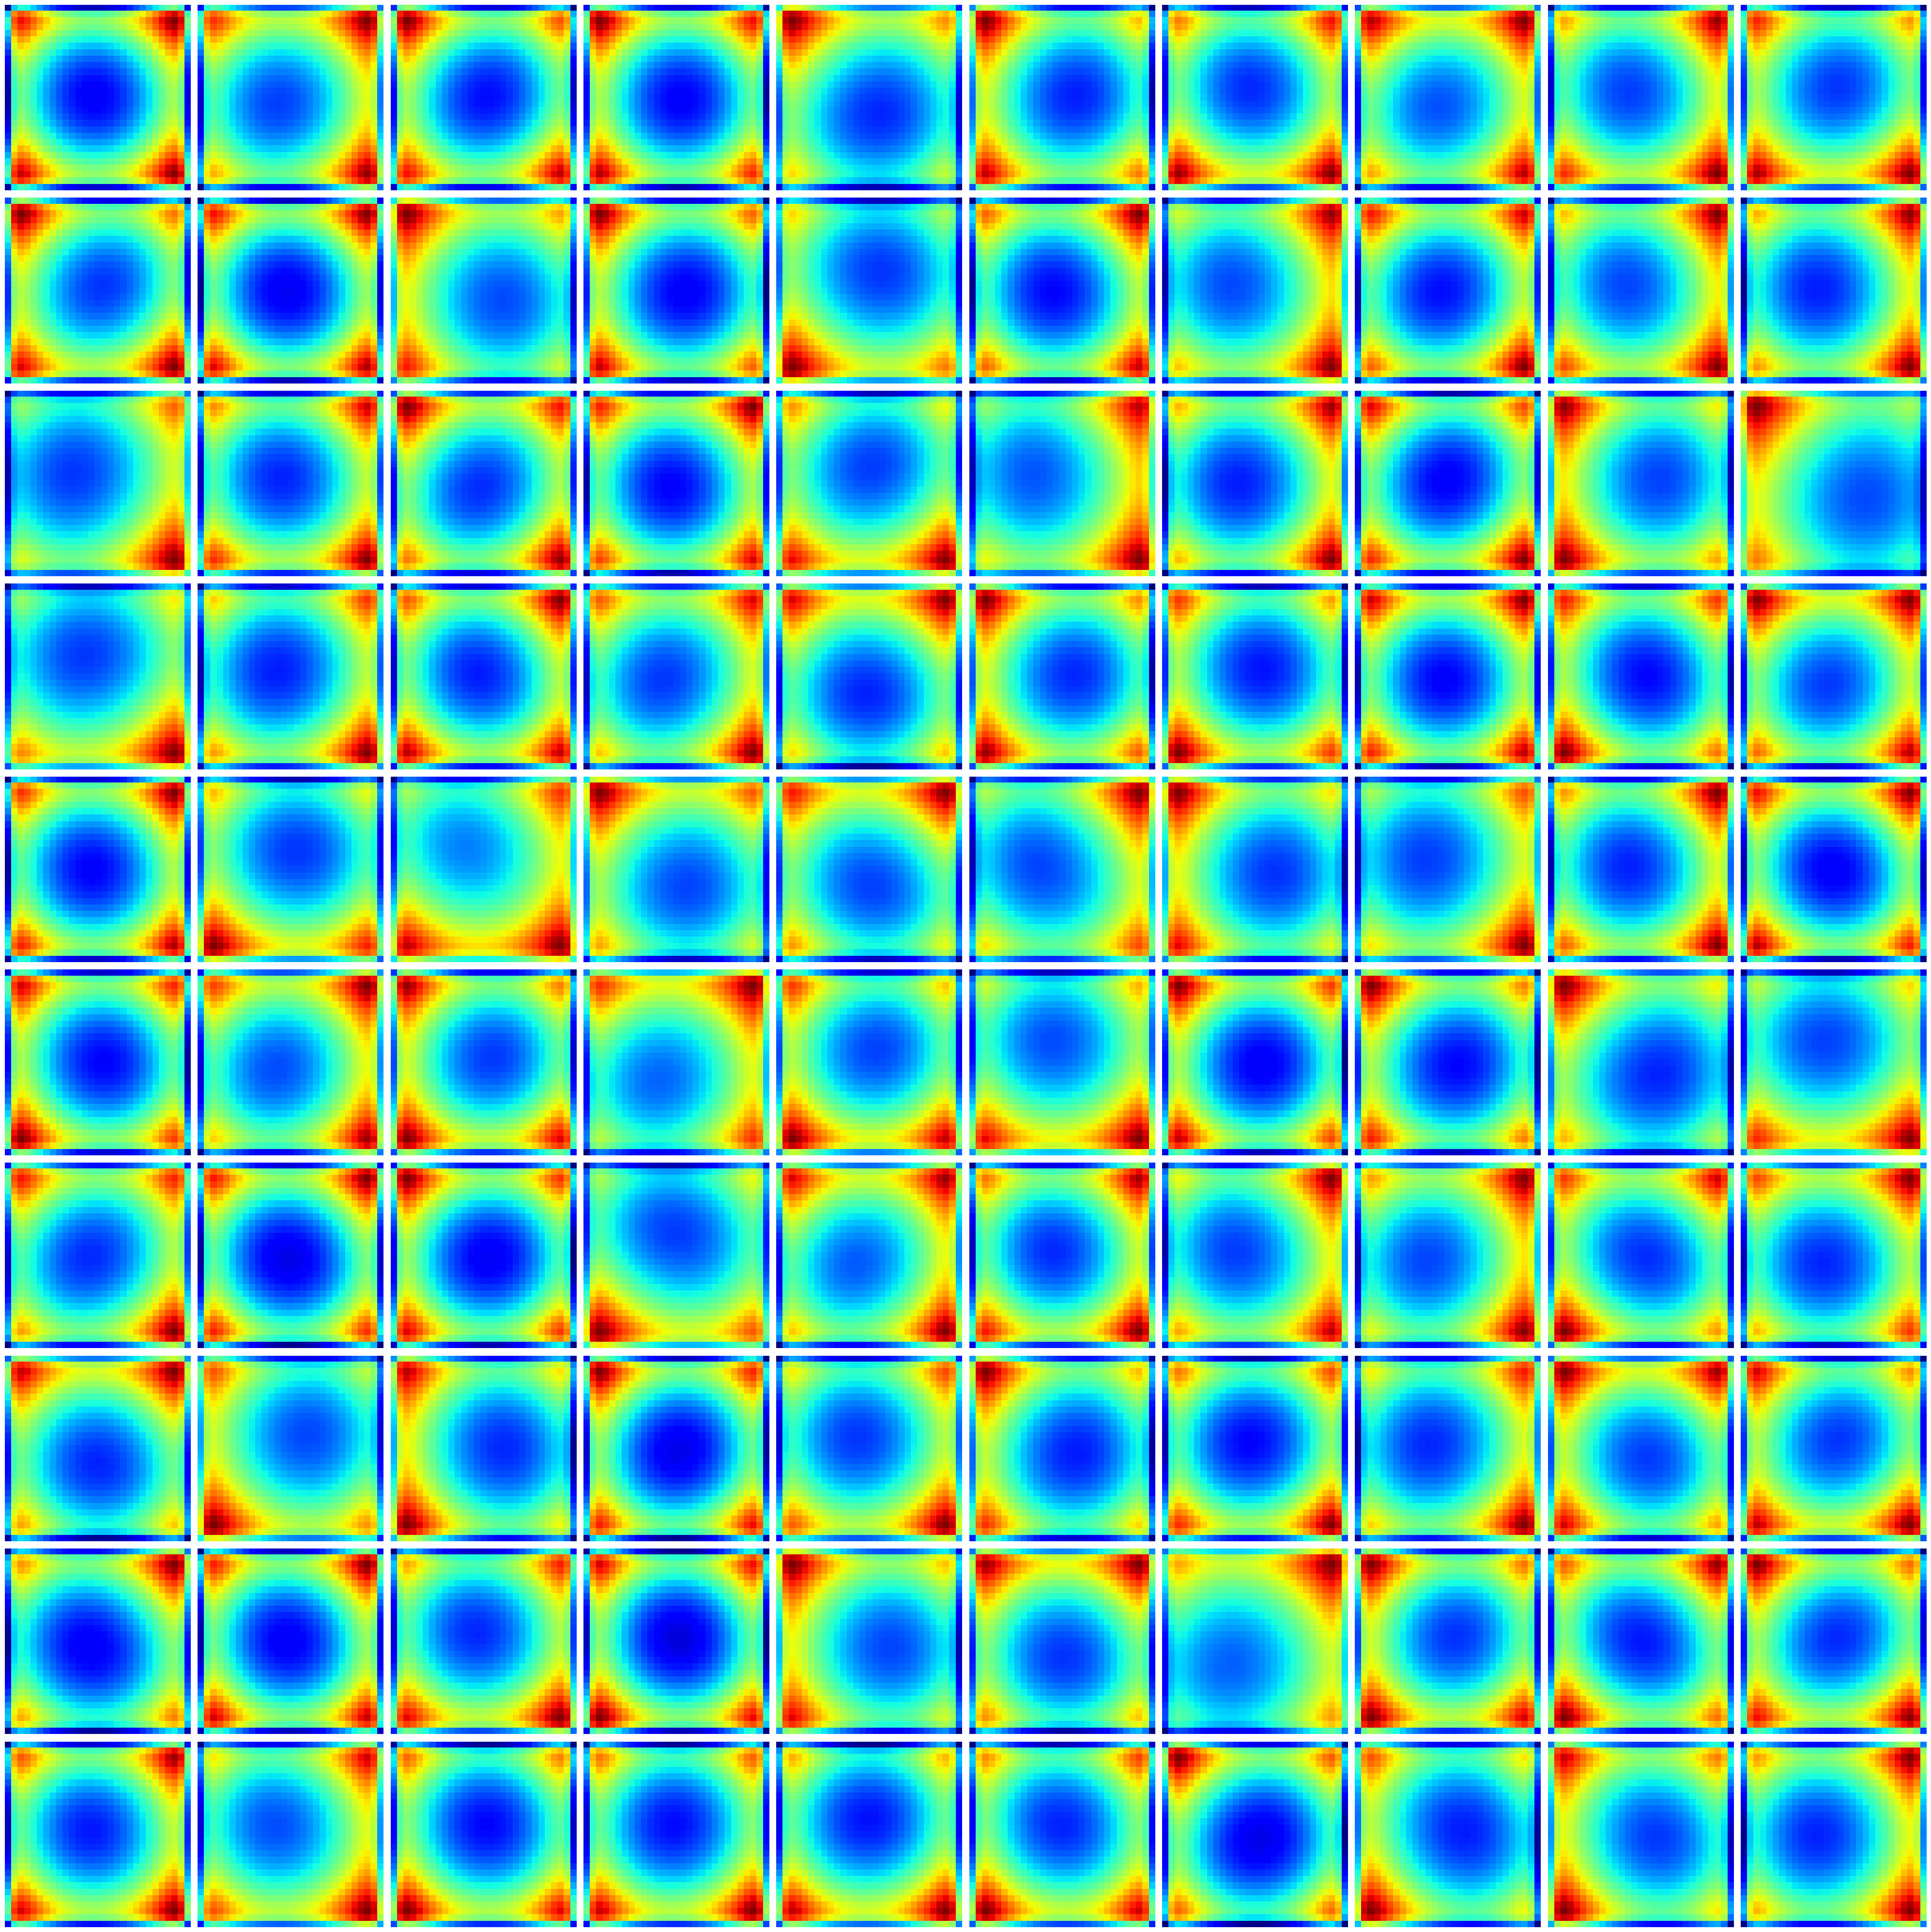

In [51]:
# lagrangean optimisation # 
from GridModels.code.models import pattern_formation as paf

Ng = 10**2

lagrange_dict = paf.optimize_lagrangean(P, 
                                        n_grid_cells = Ng,
                                        learning_rate=0.01,
                                        n_iterations=10000)
G = lagrange_dict['G']



n_plot_rows = int(np.sqrt(Ng))
fig, ax = plt.subplots(n_plot_rows,Ng//n_plot_rows, 
                            figsize = (4*Ng//n_plot_rows,4*n_plot_rows))
for i, axis in enumerate(ax.flatten()):
    axis.imshow(G[:,i].reshape(29,29), cmap = 'jet')
    axis.axis('off')
fig.tight_layout()
plt.show()


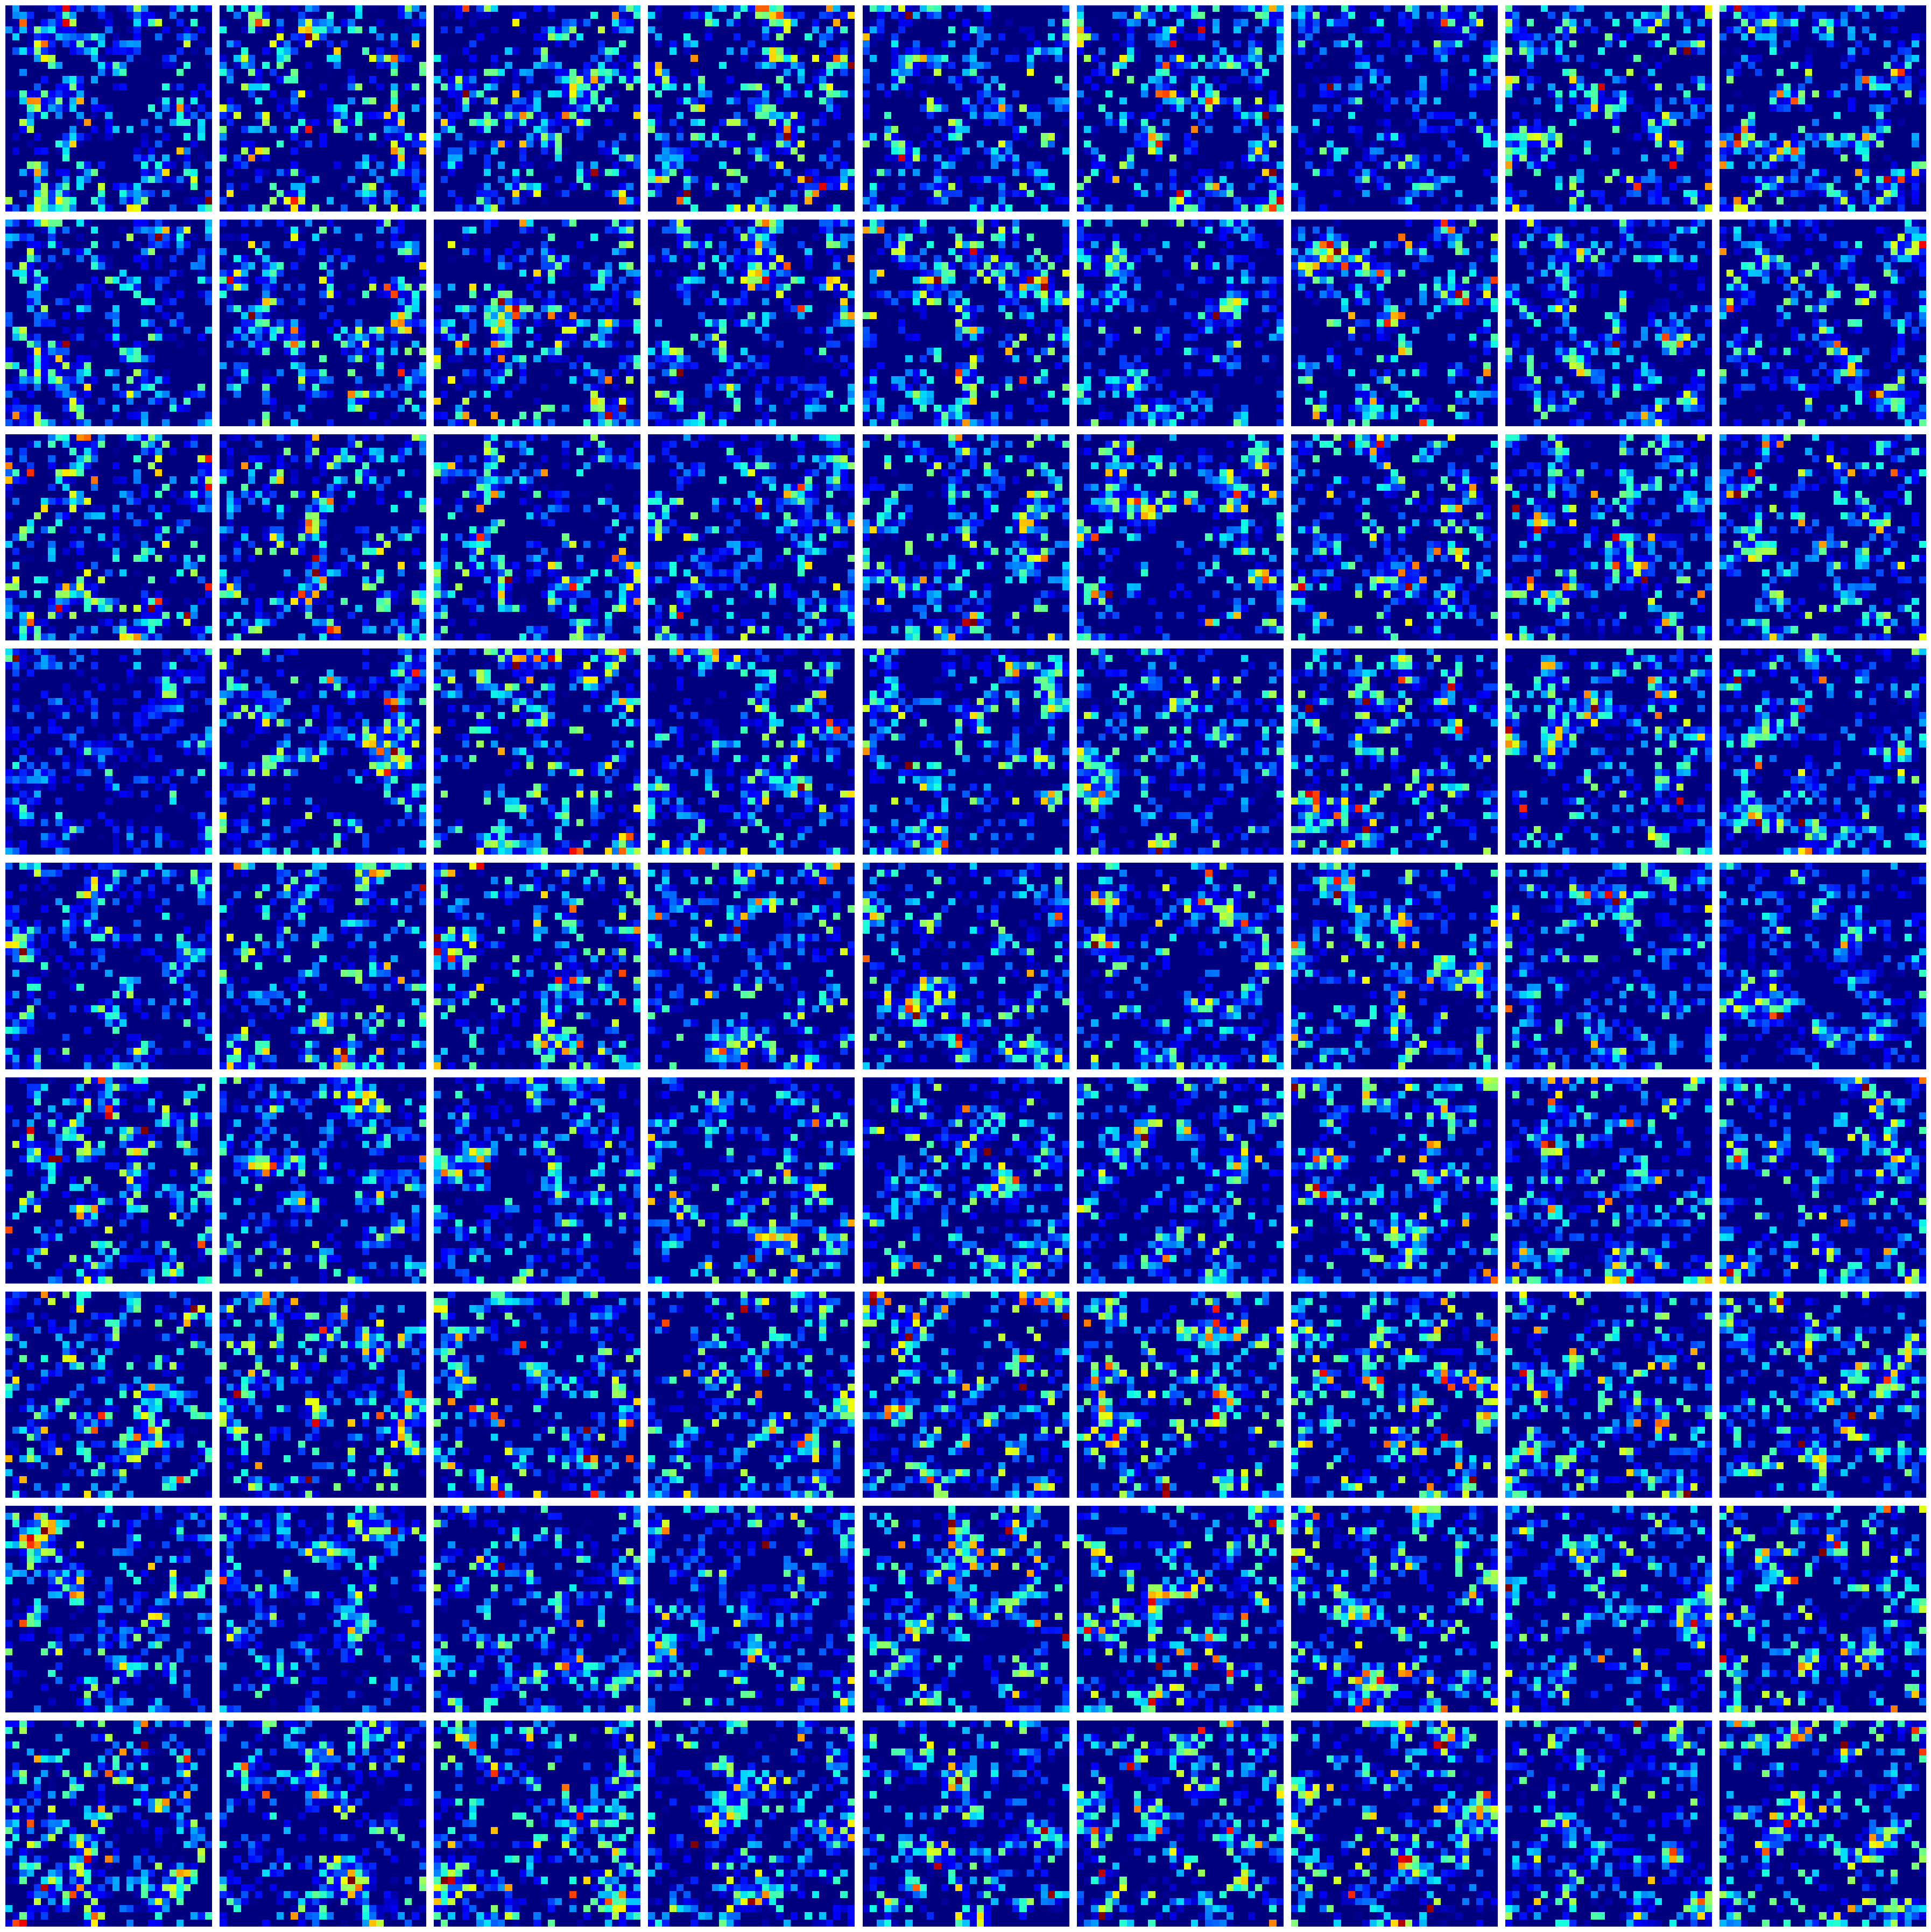

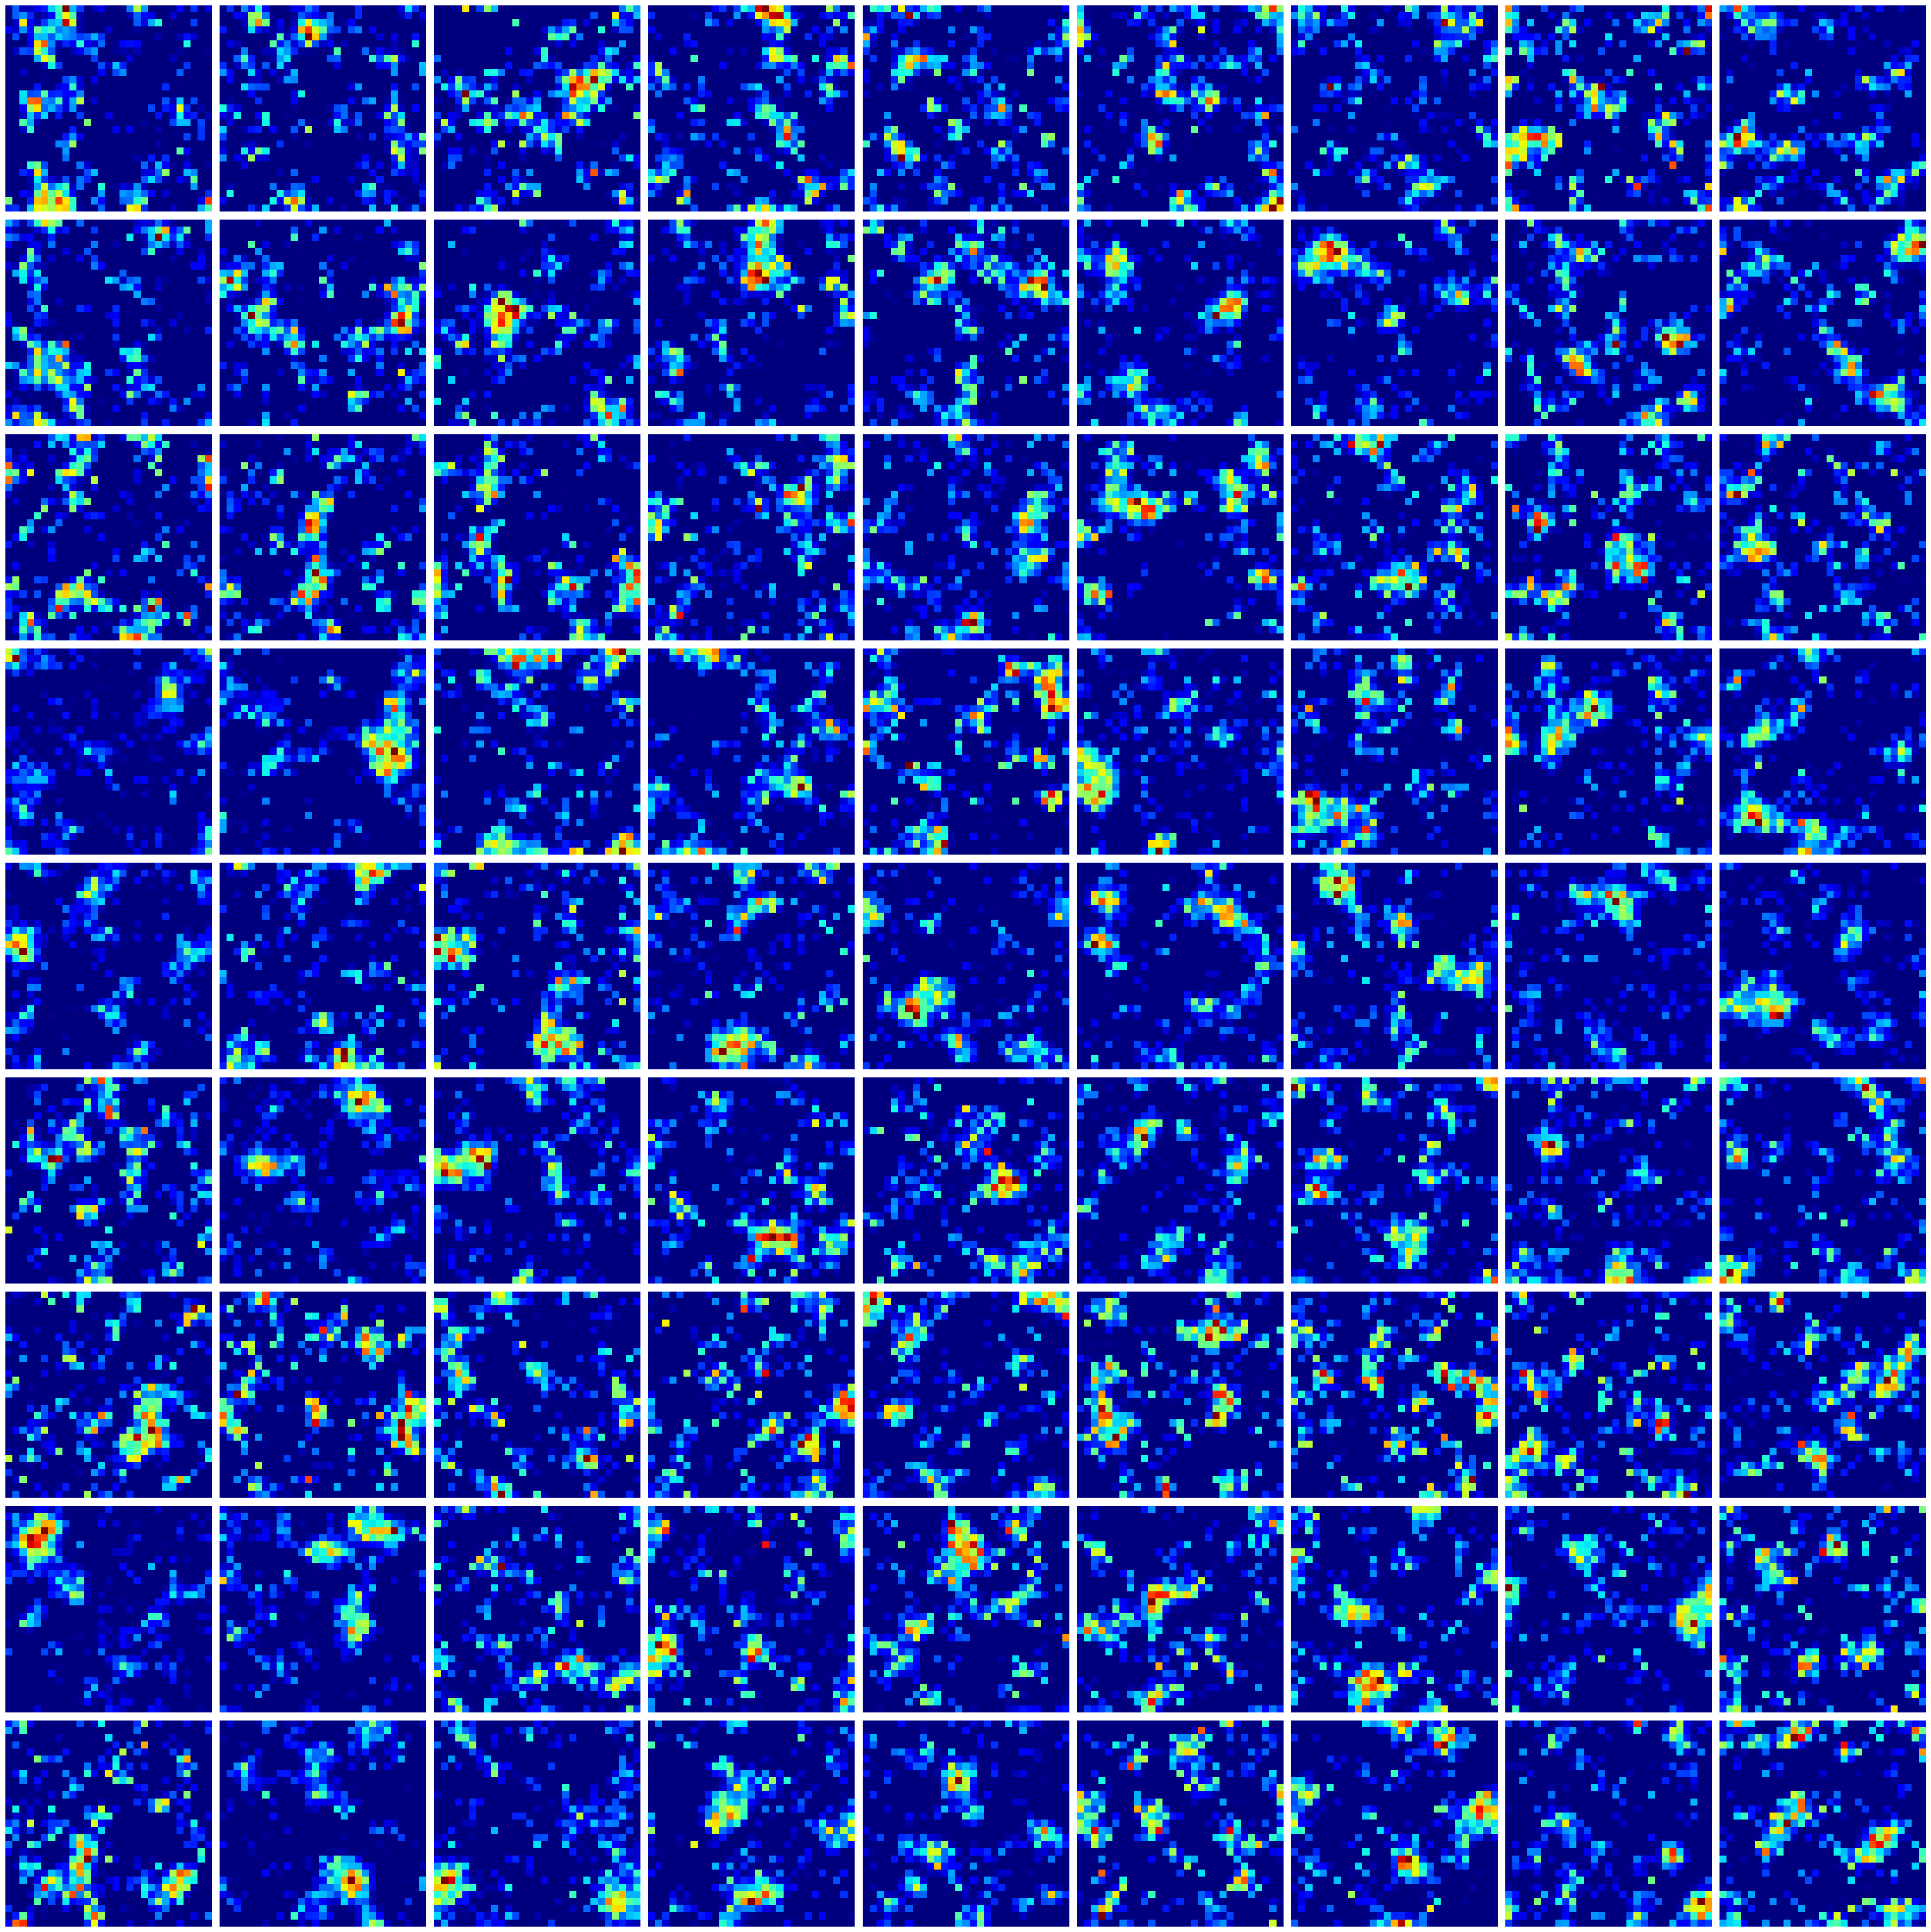

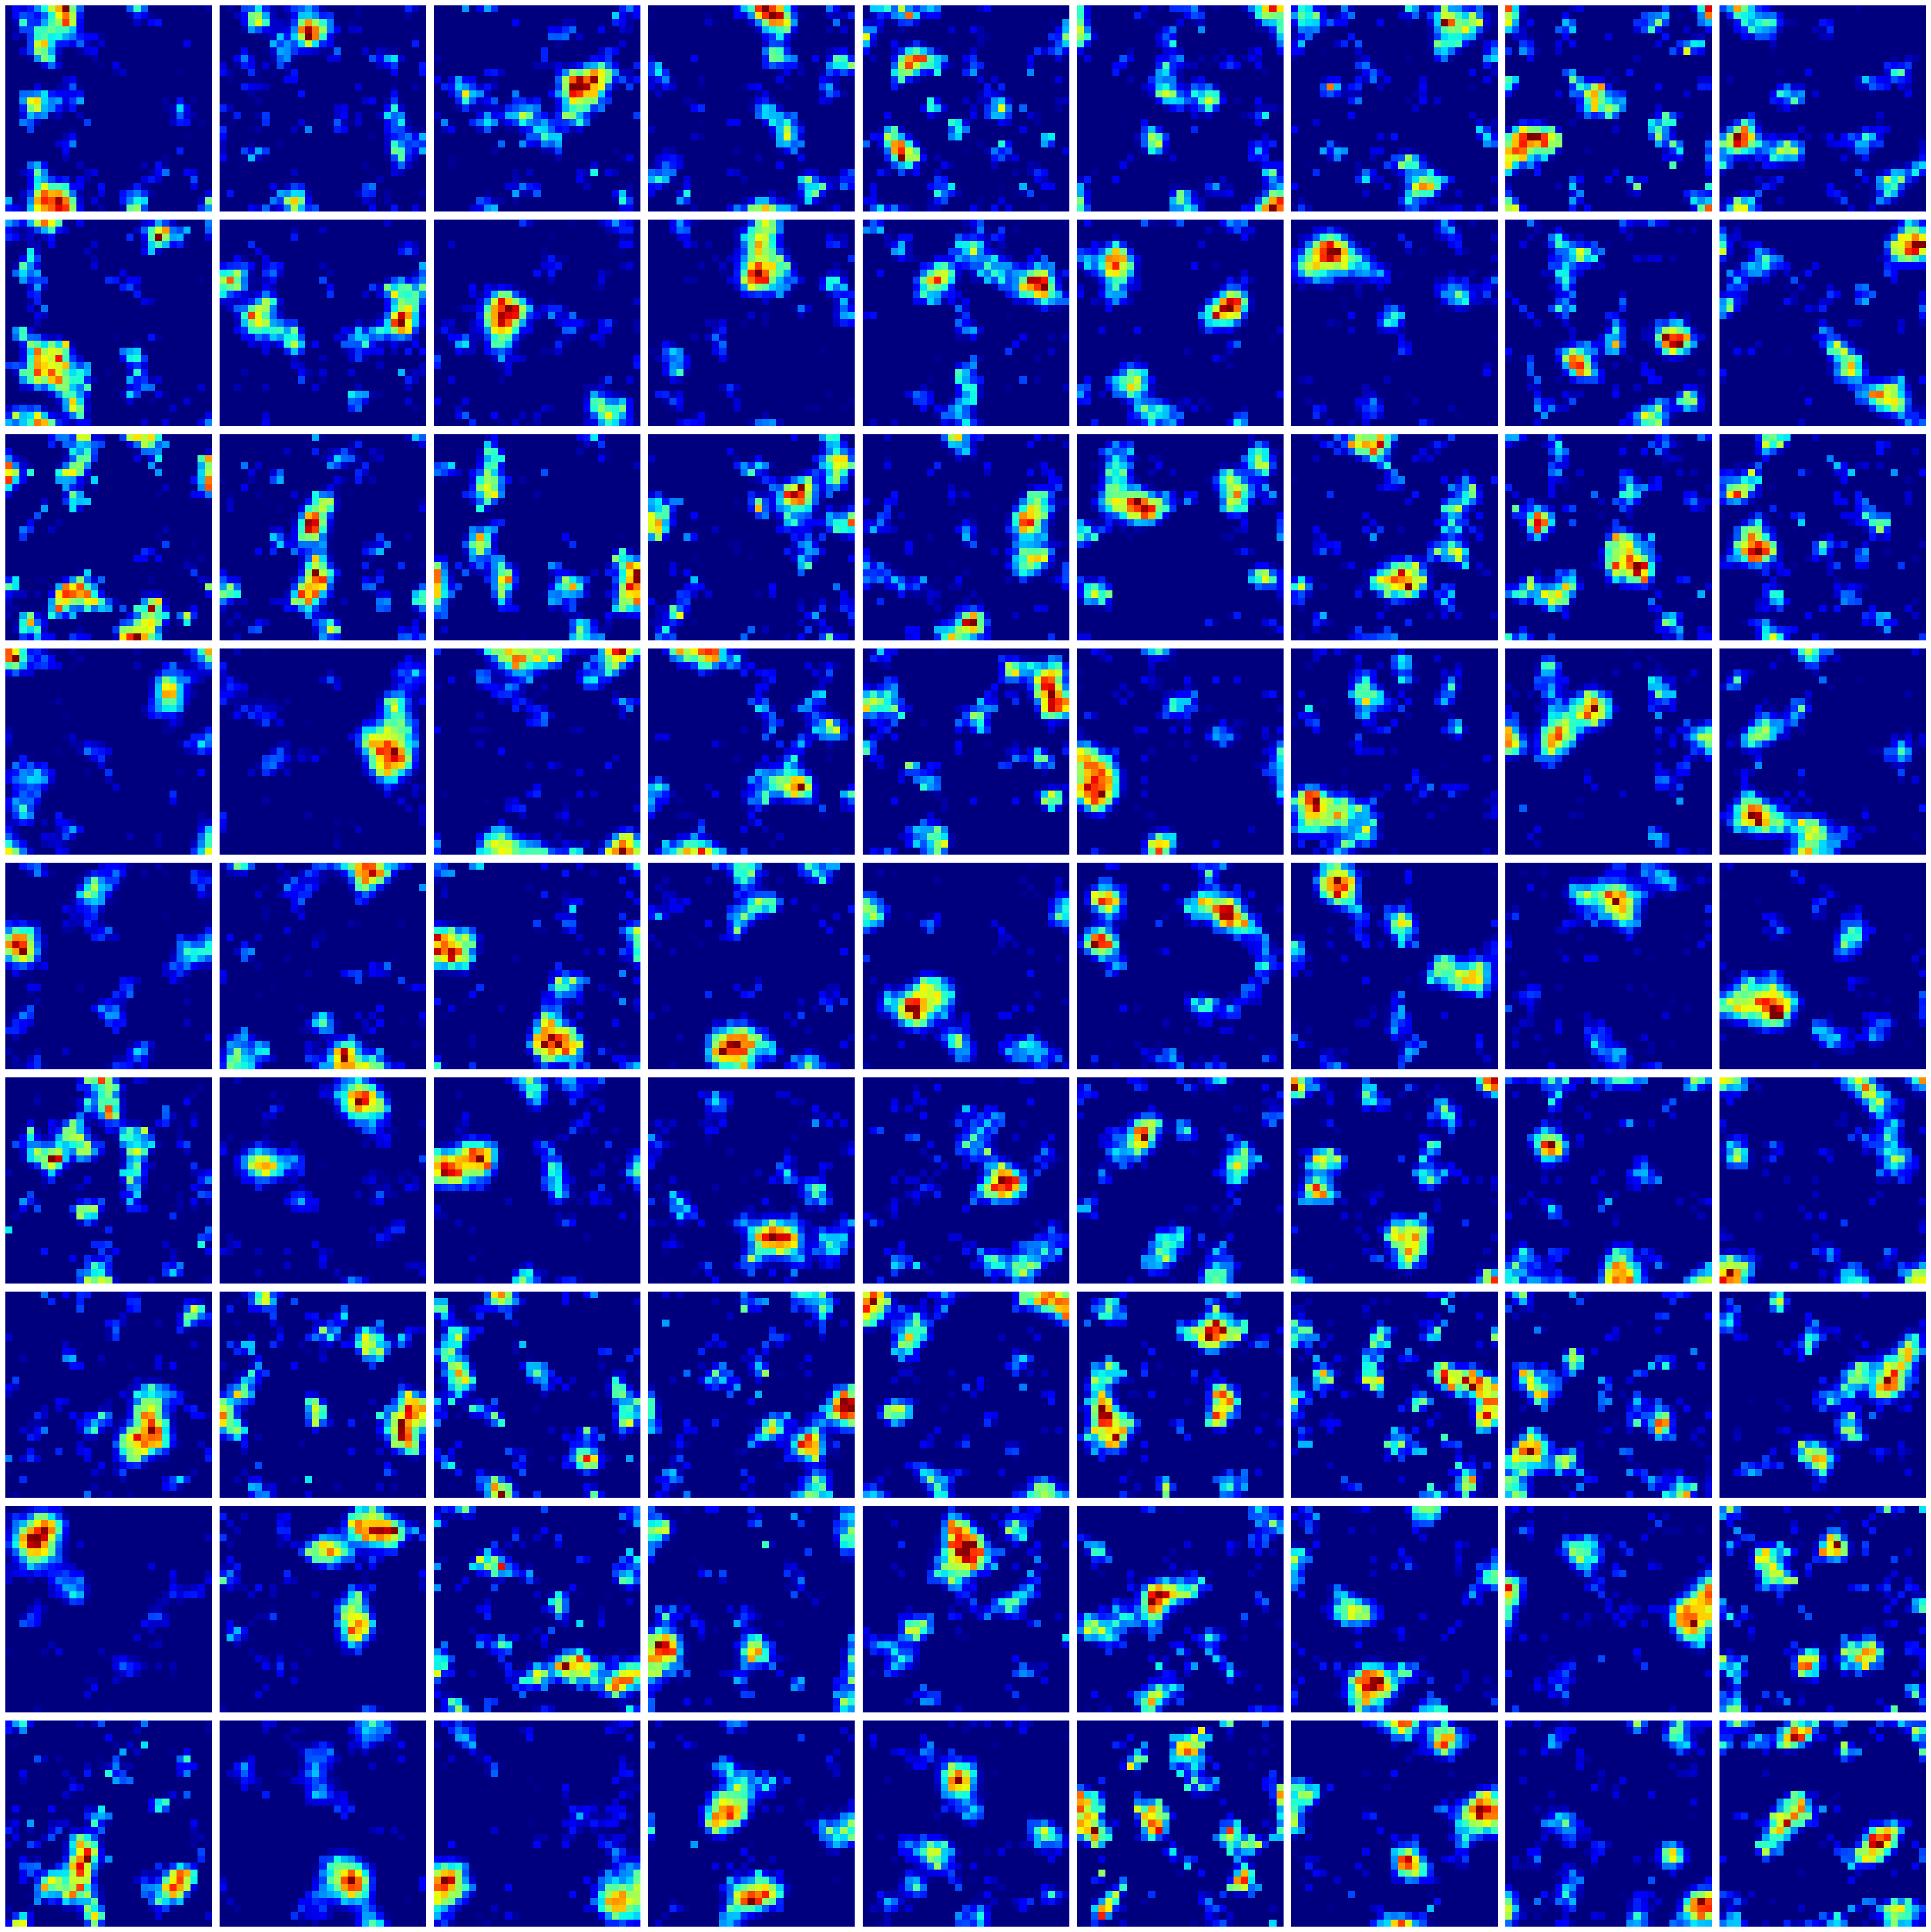

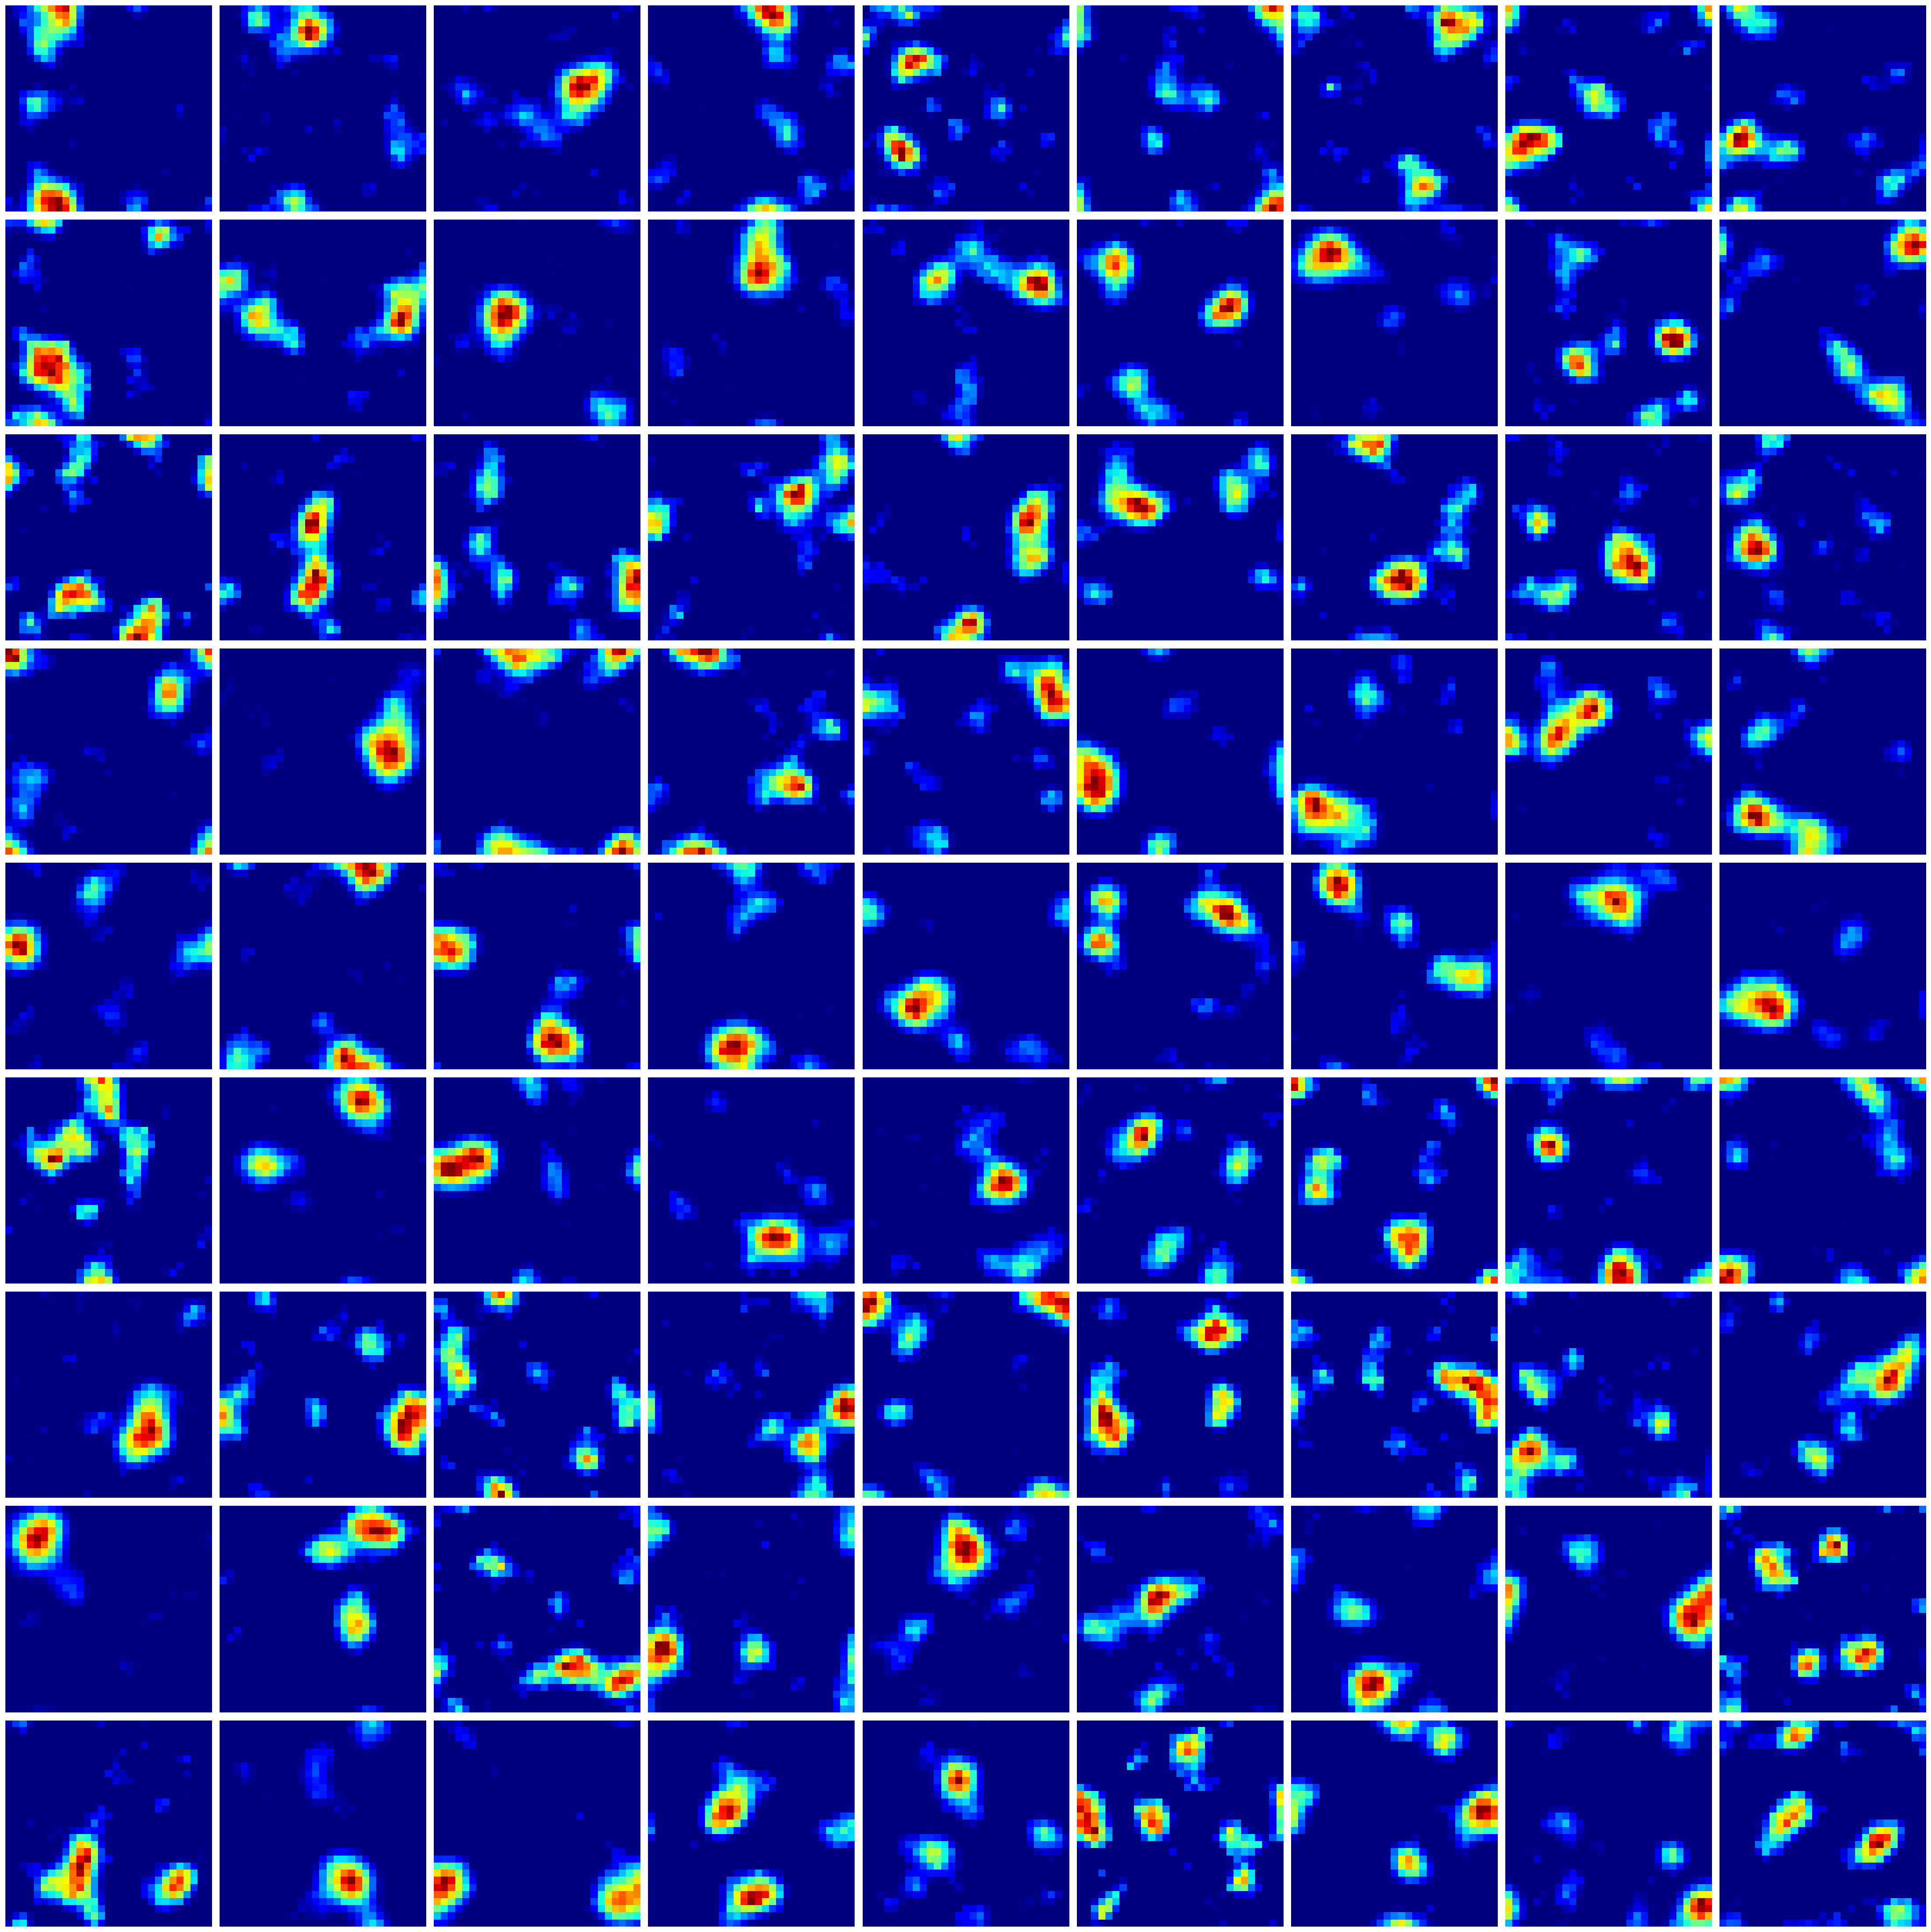

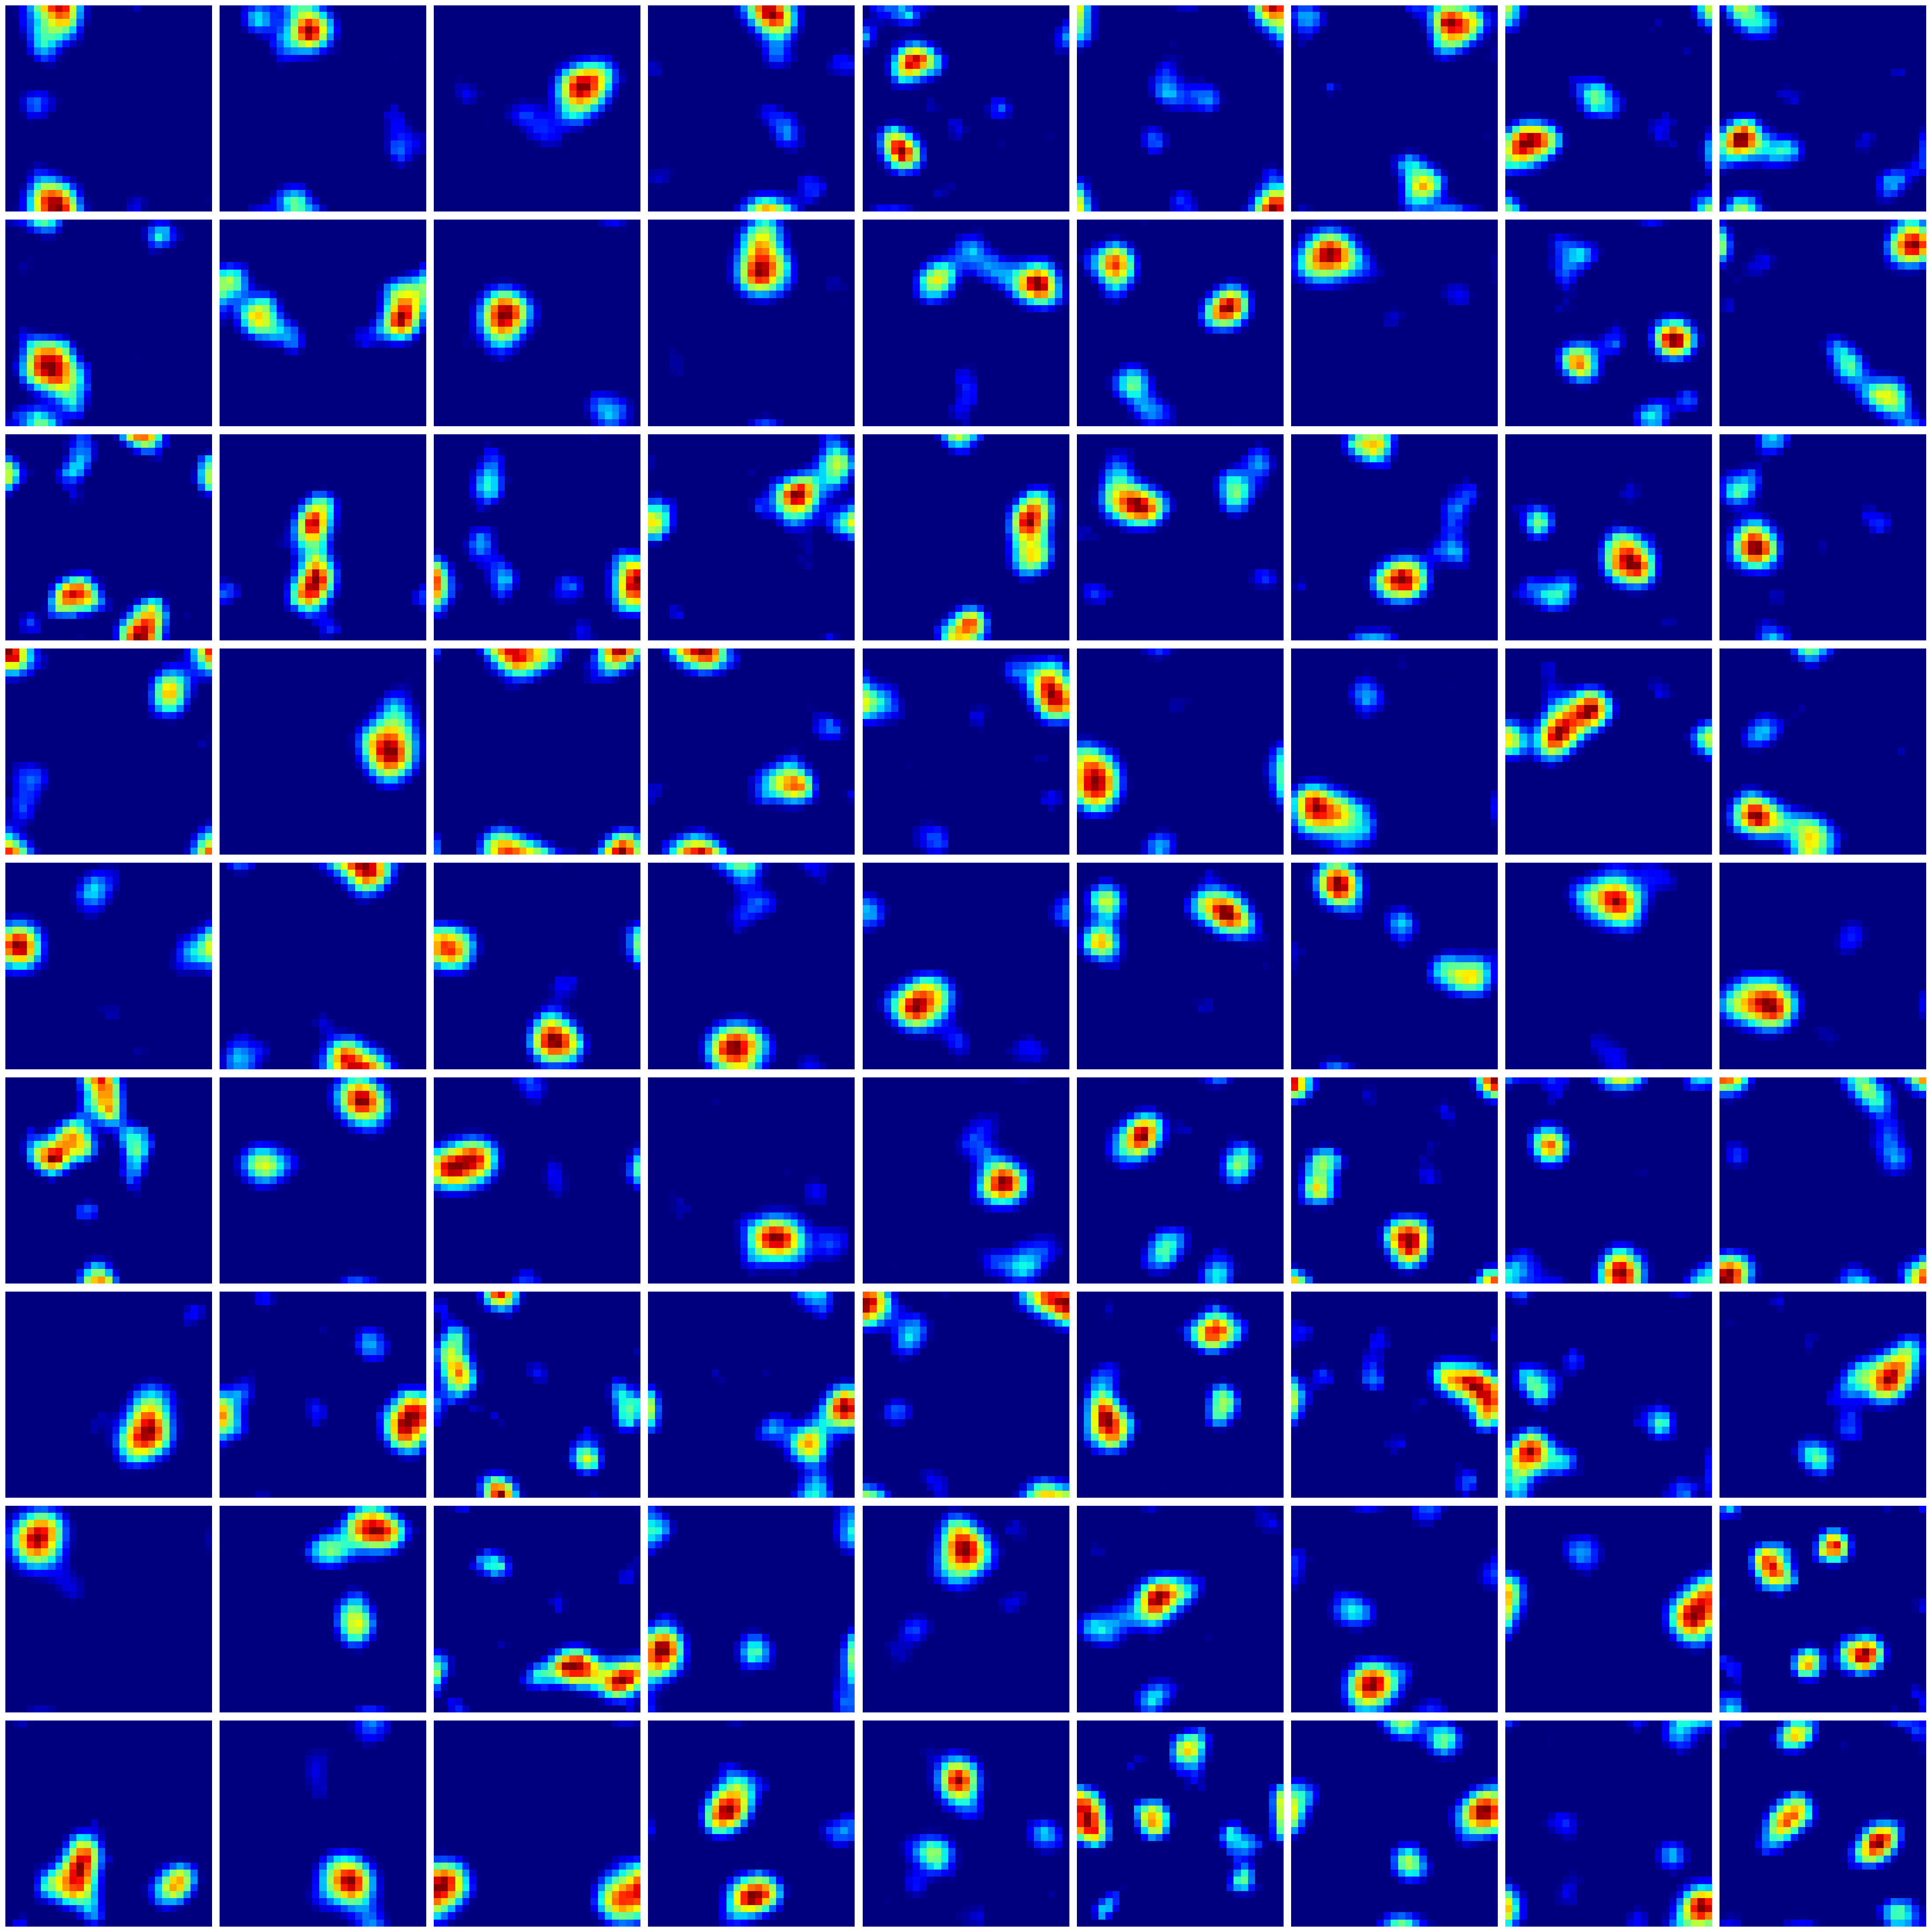

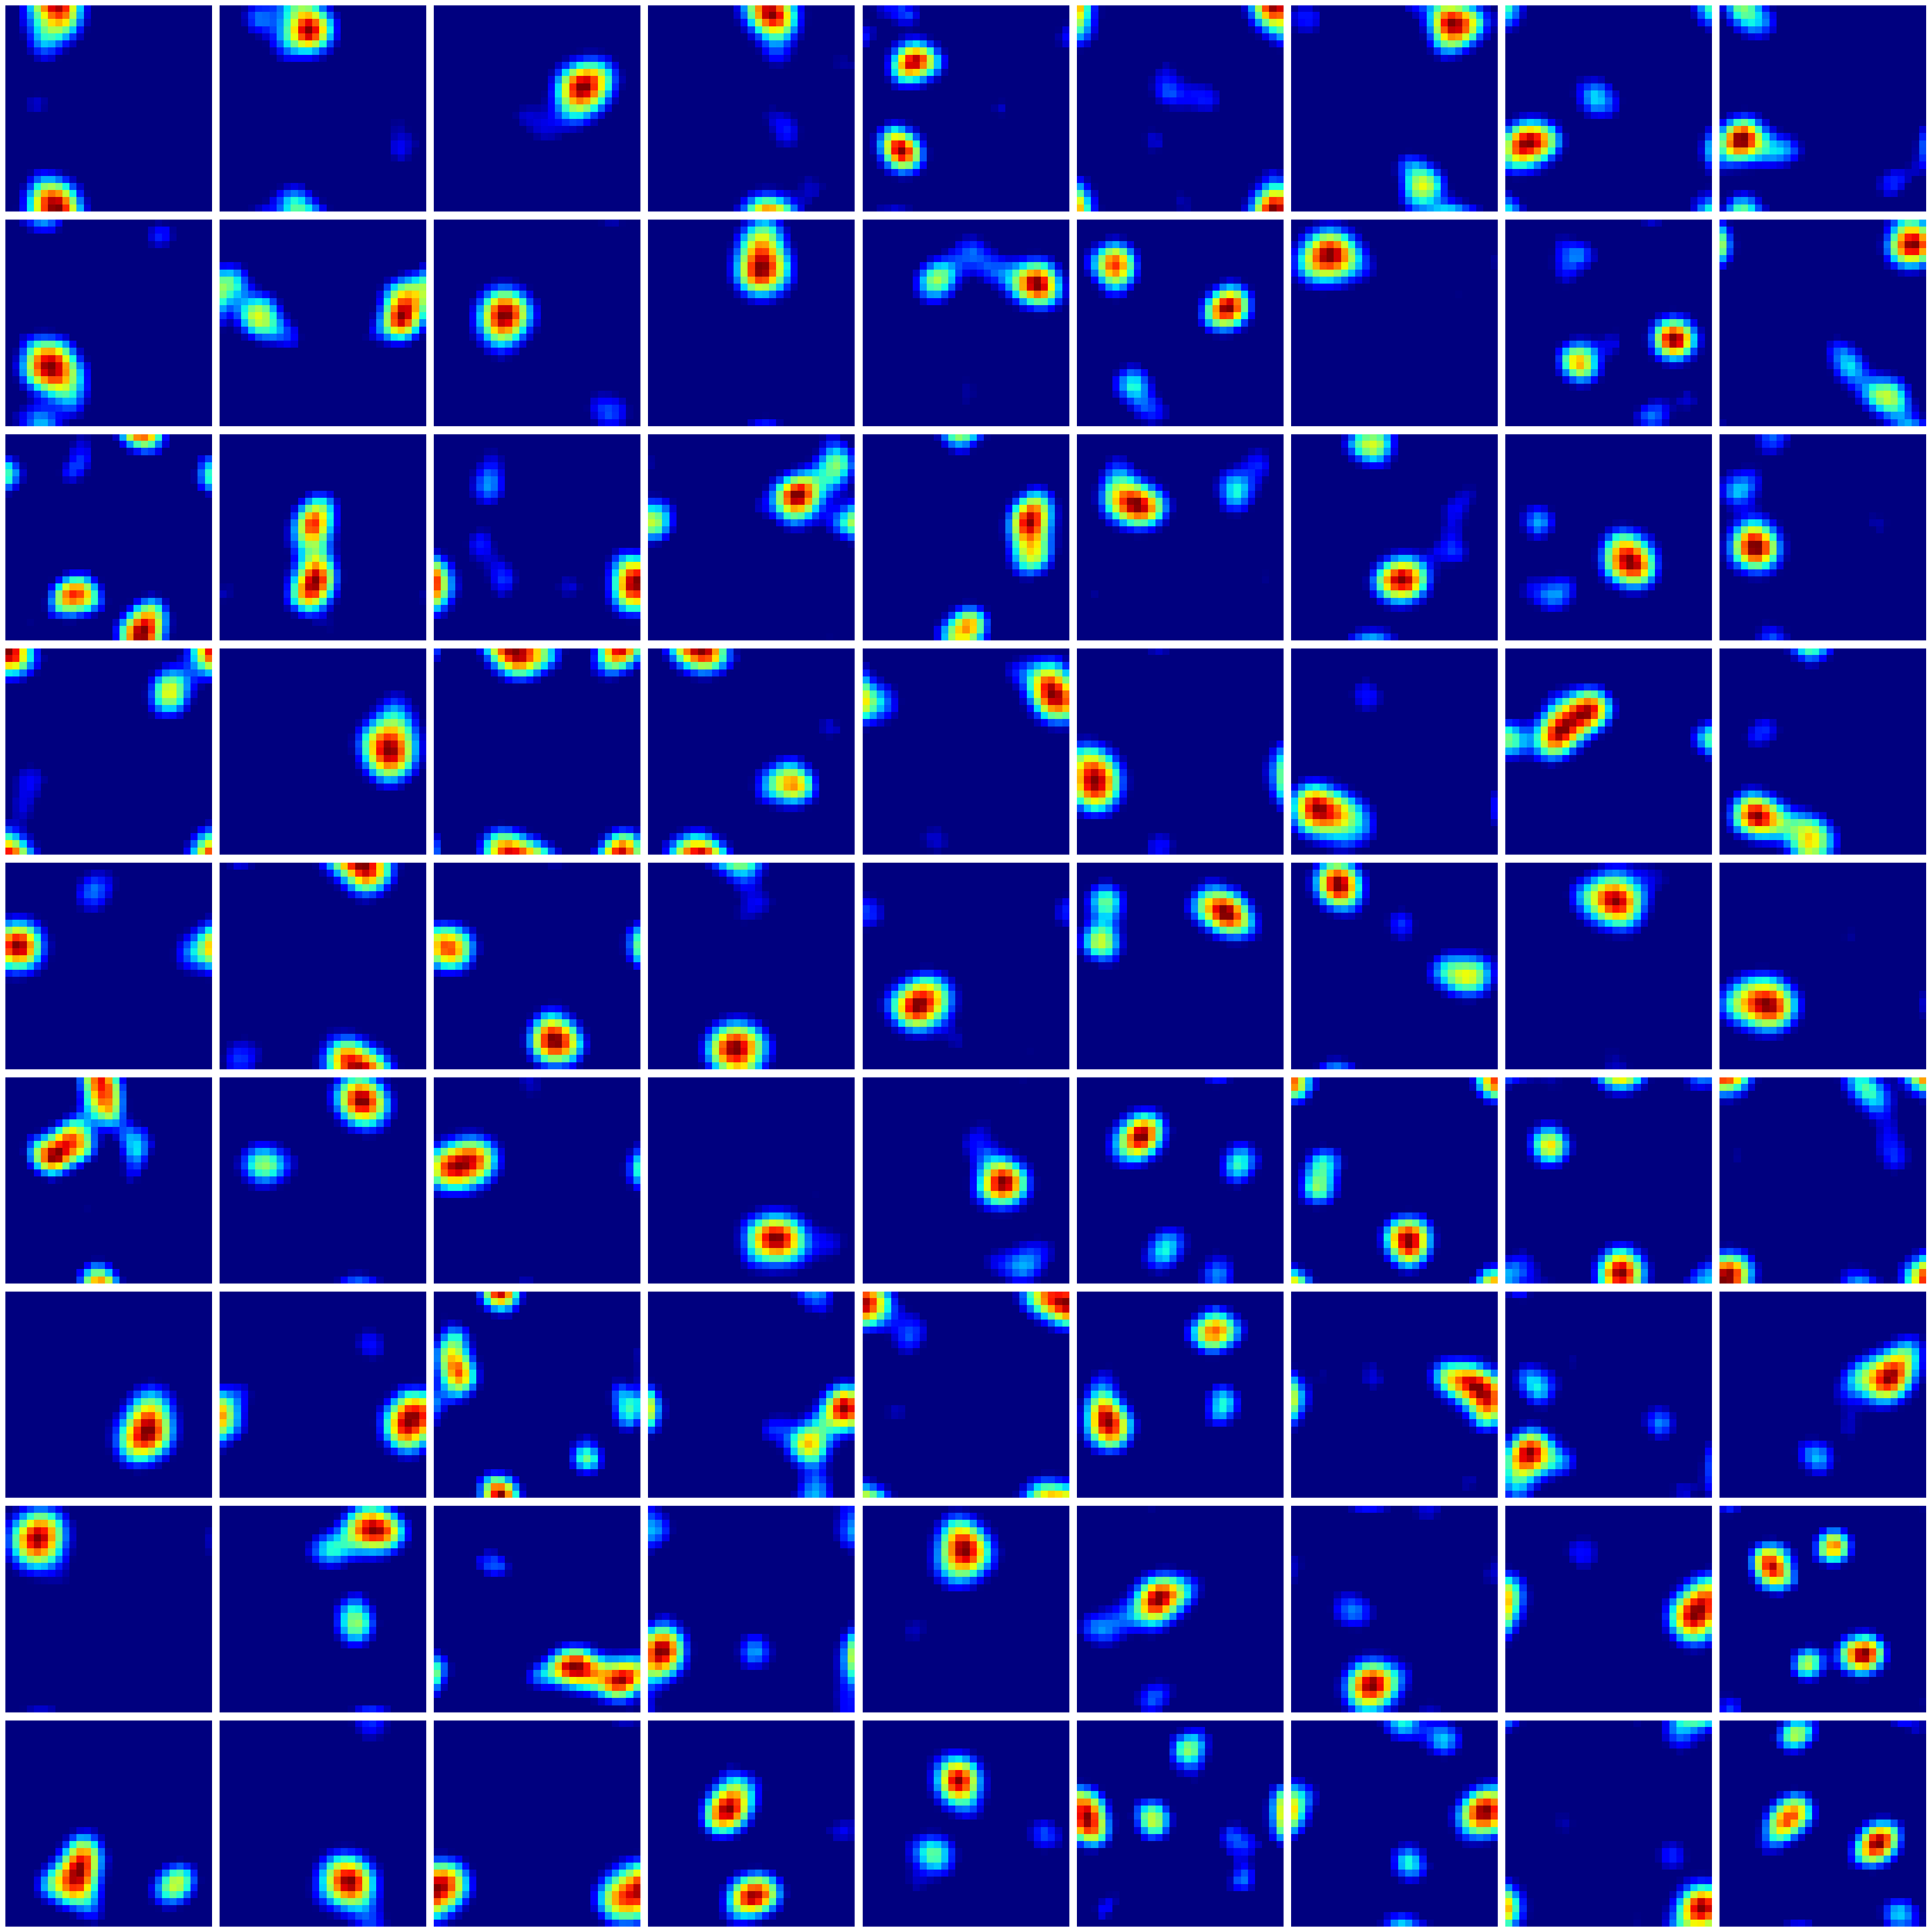

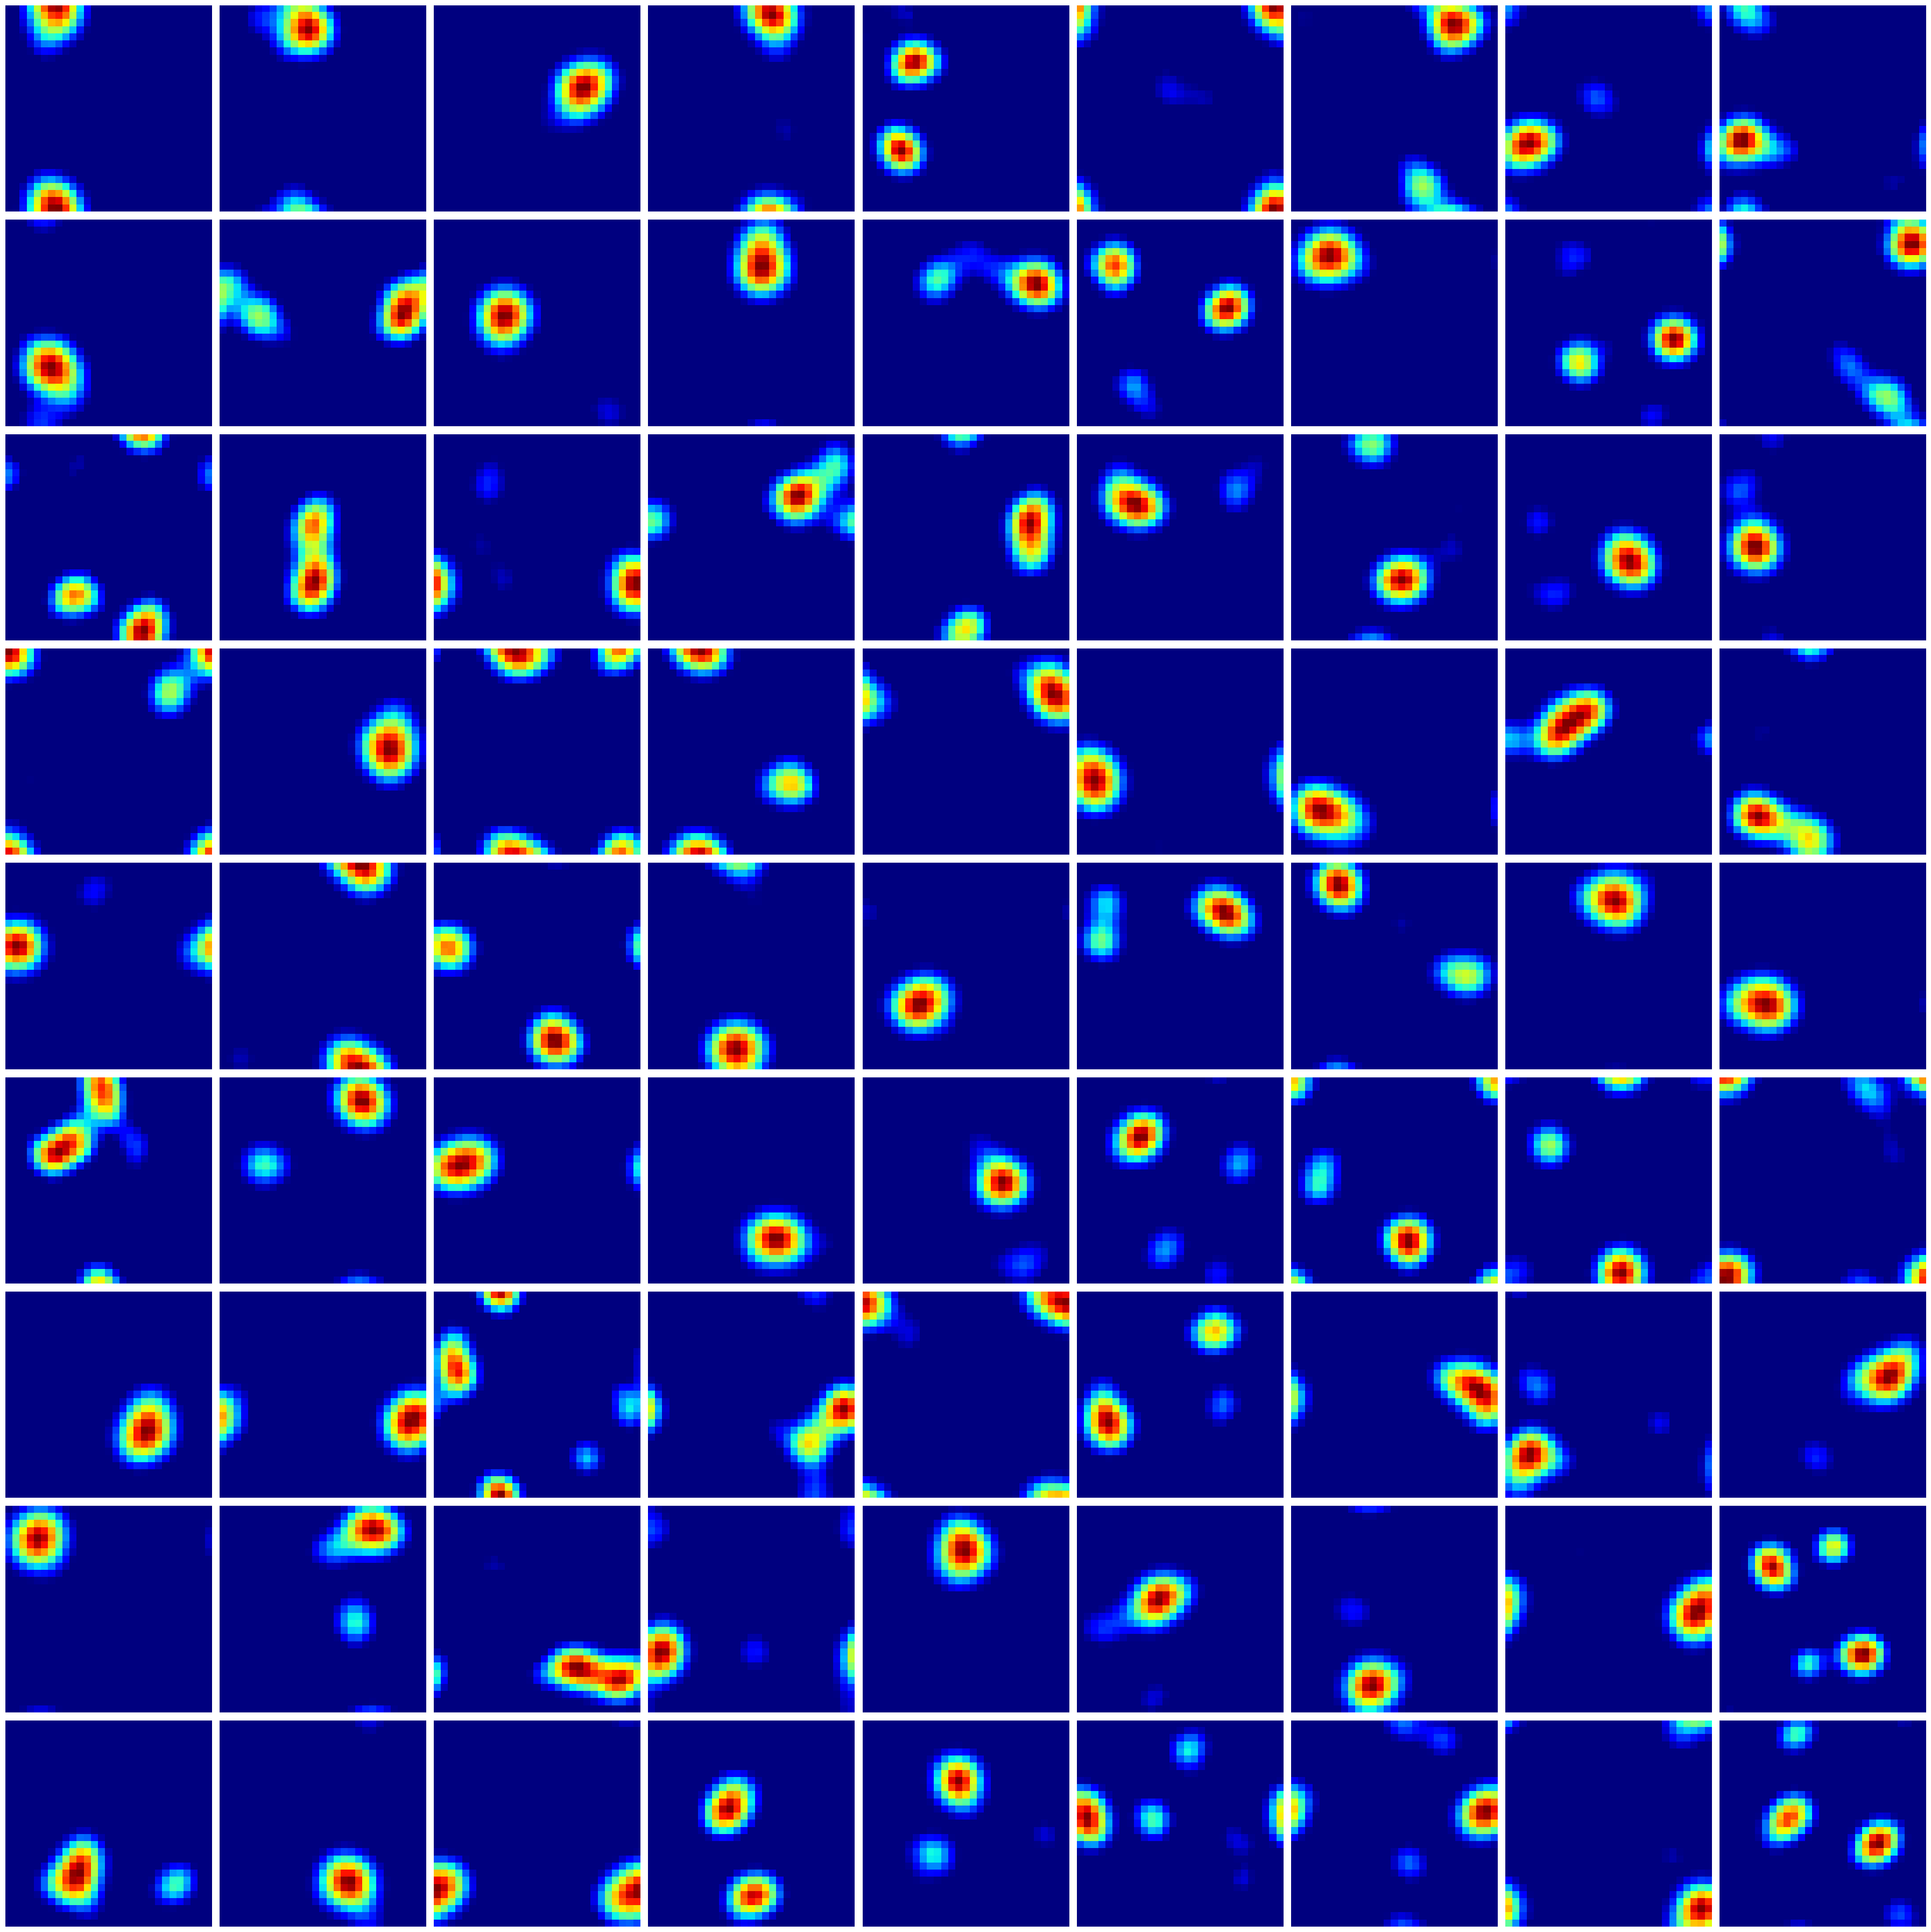

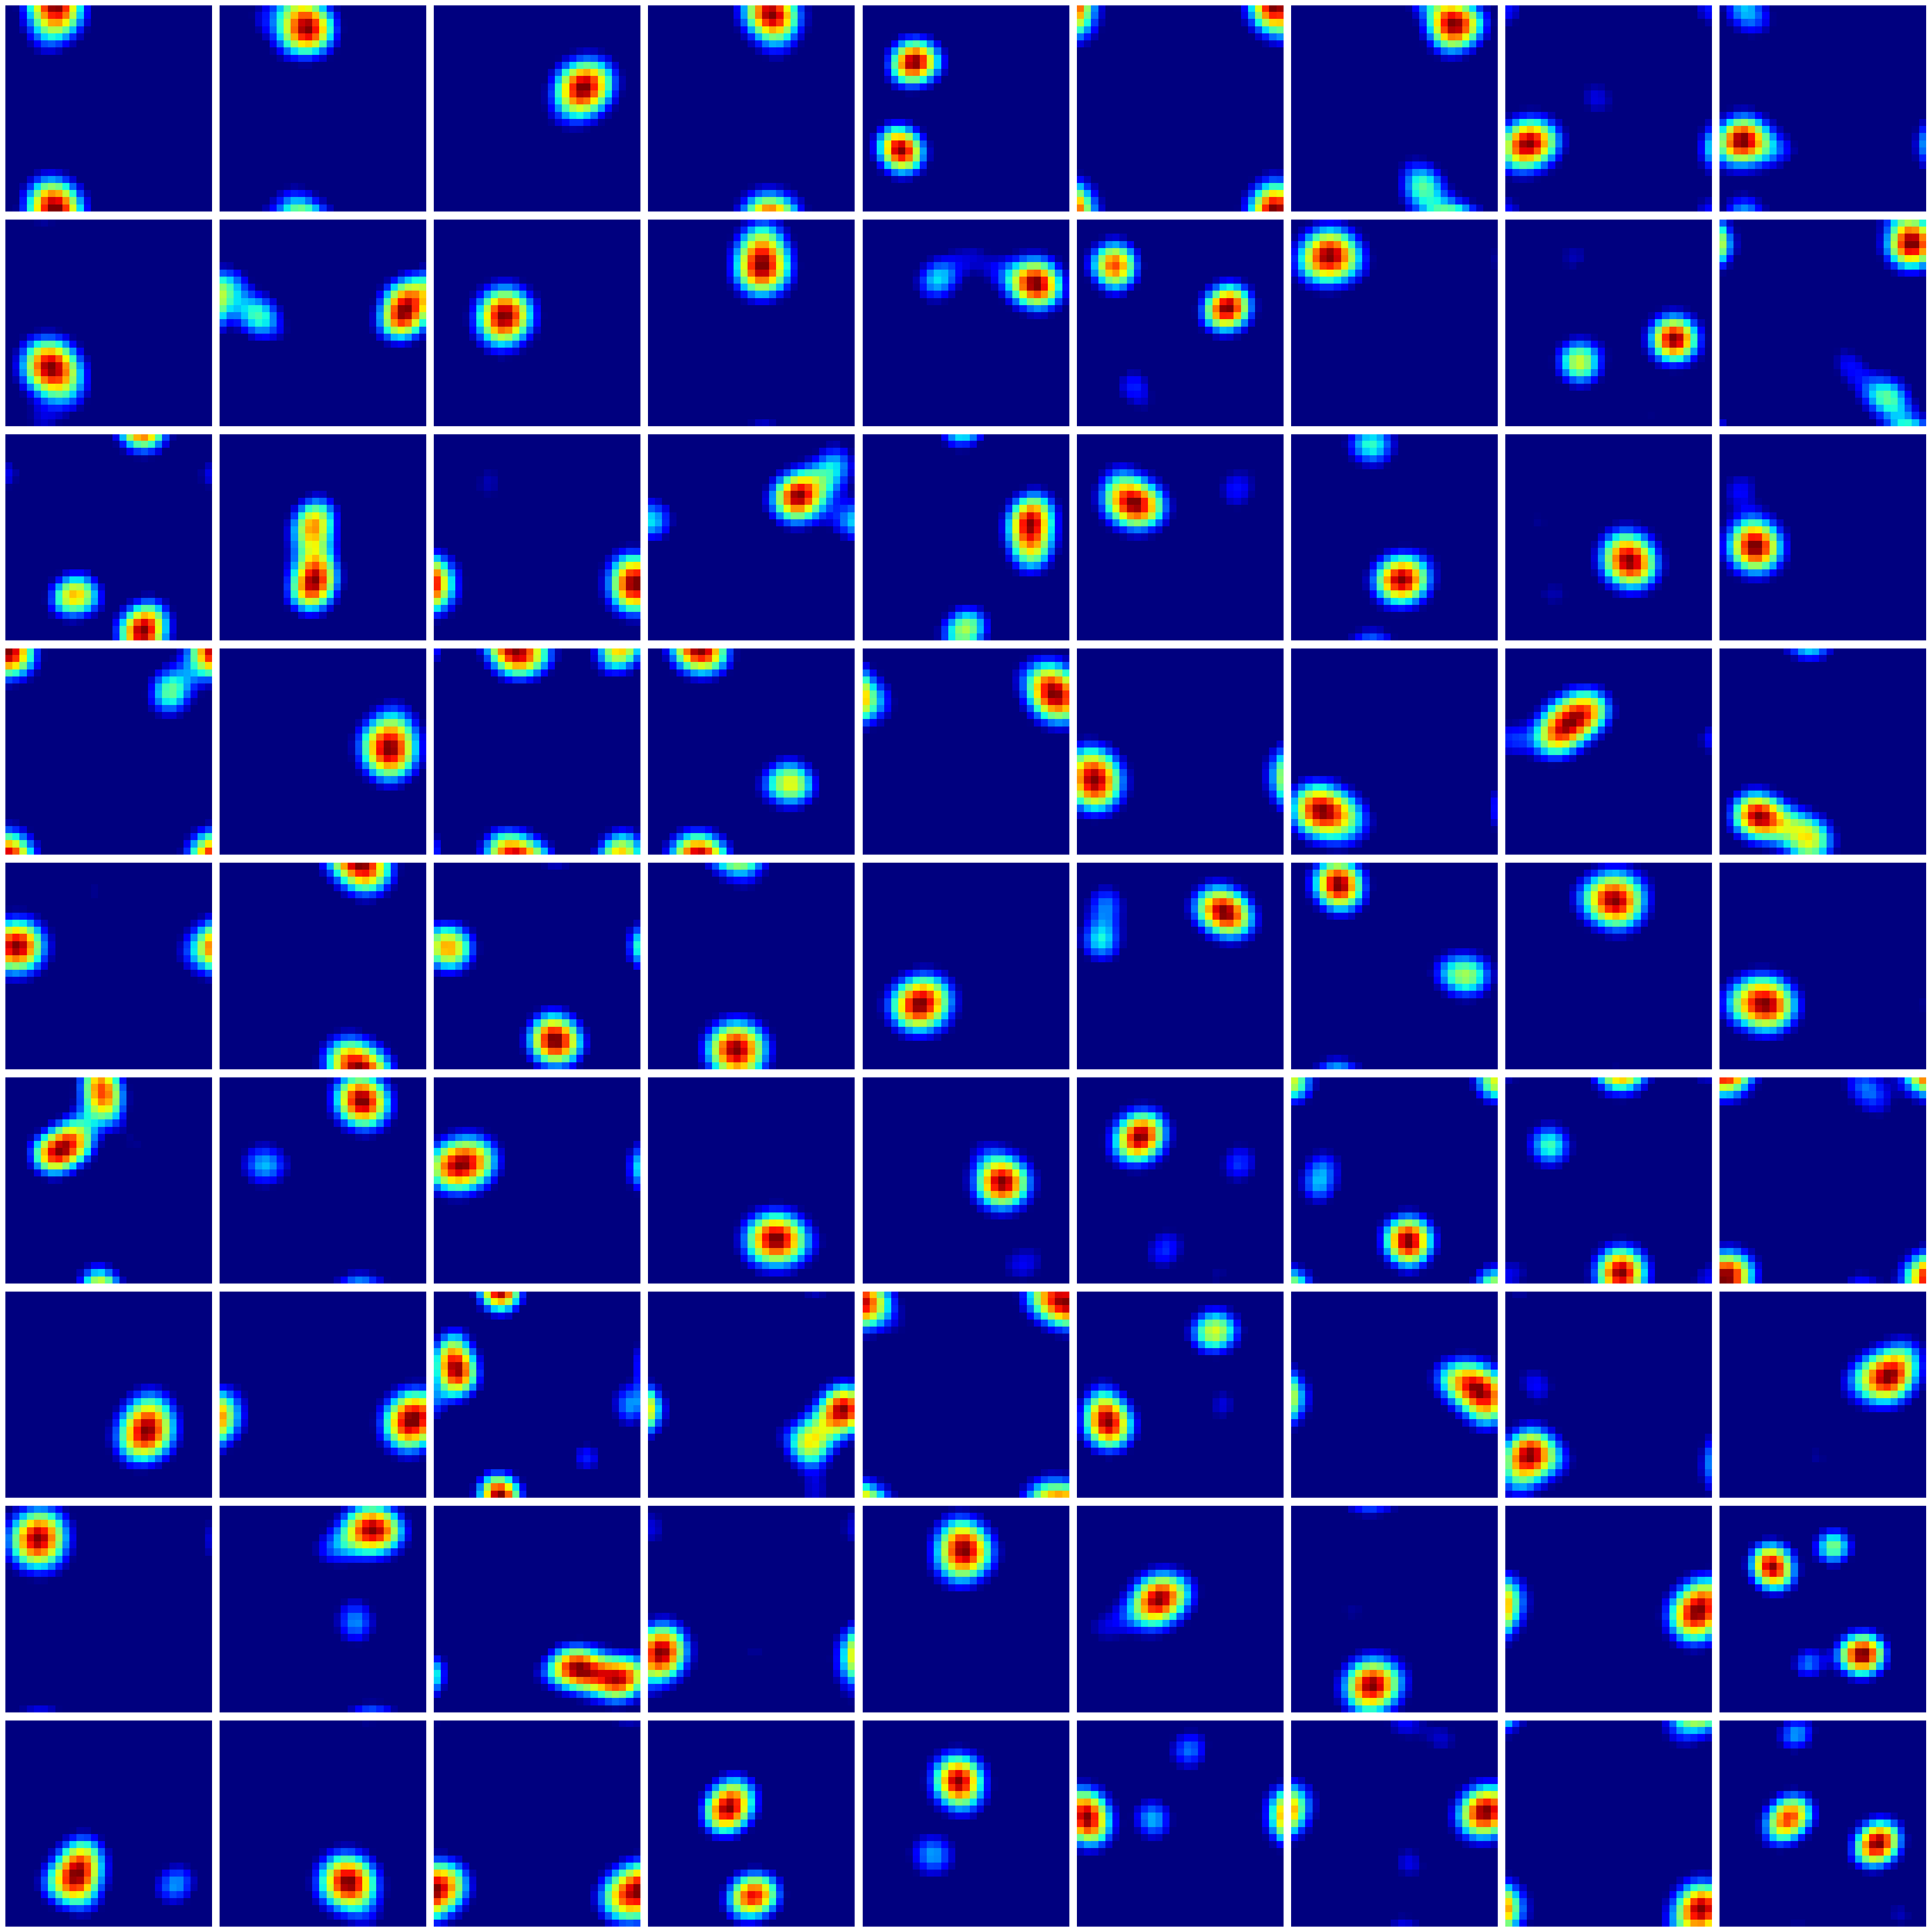

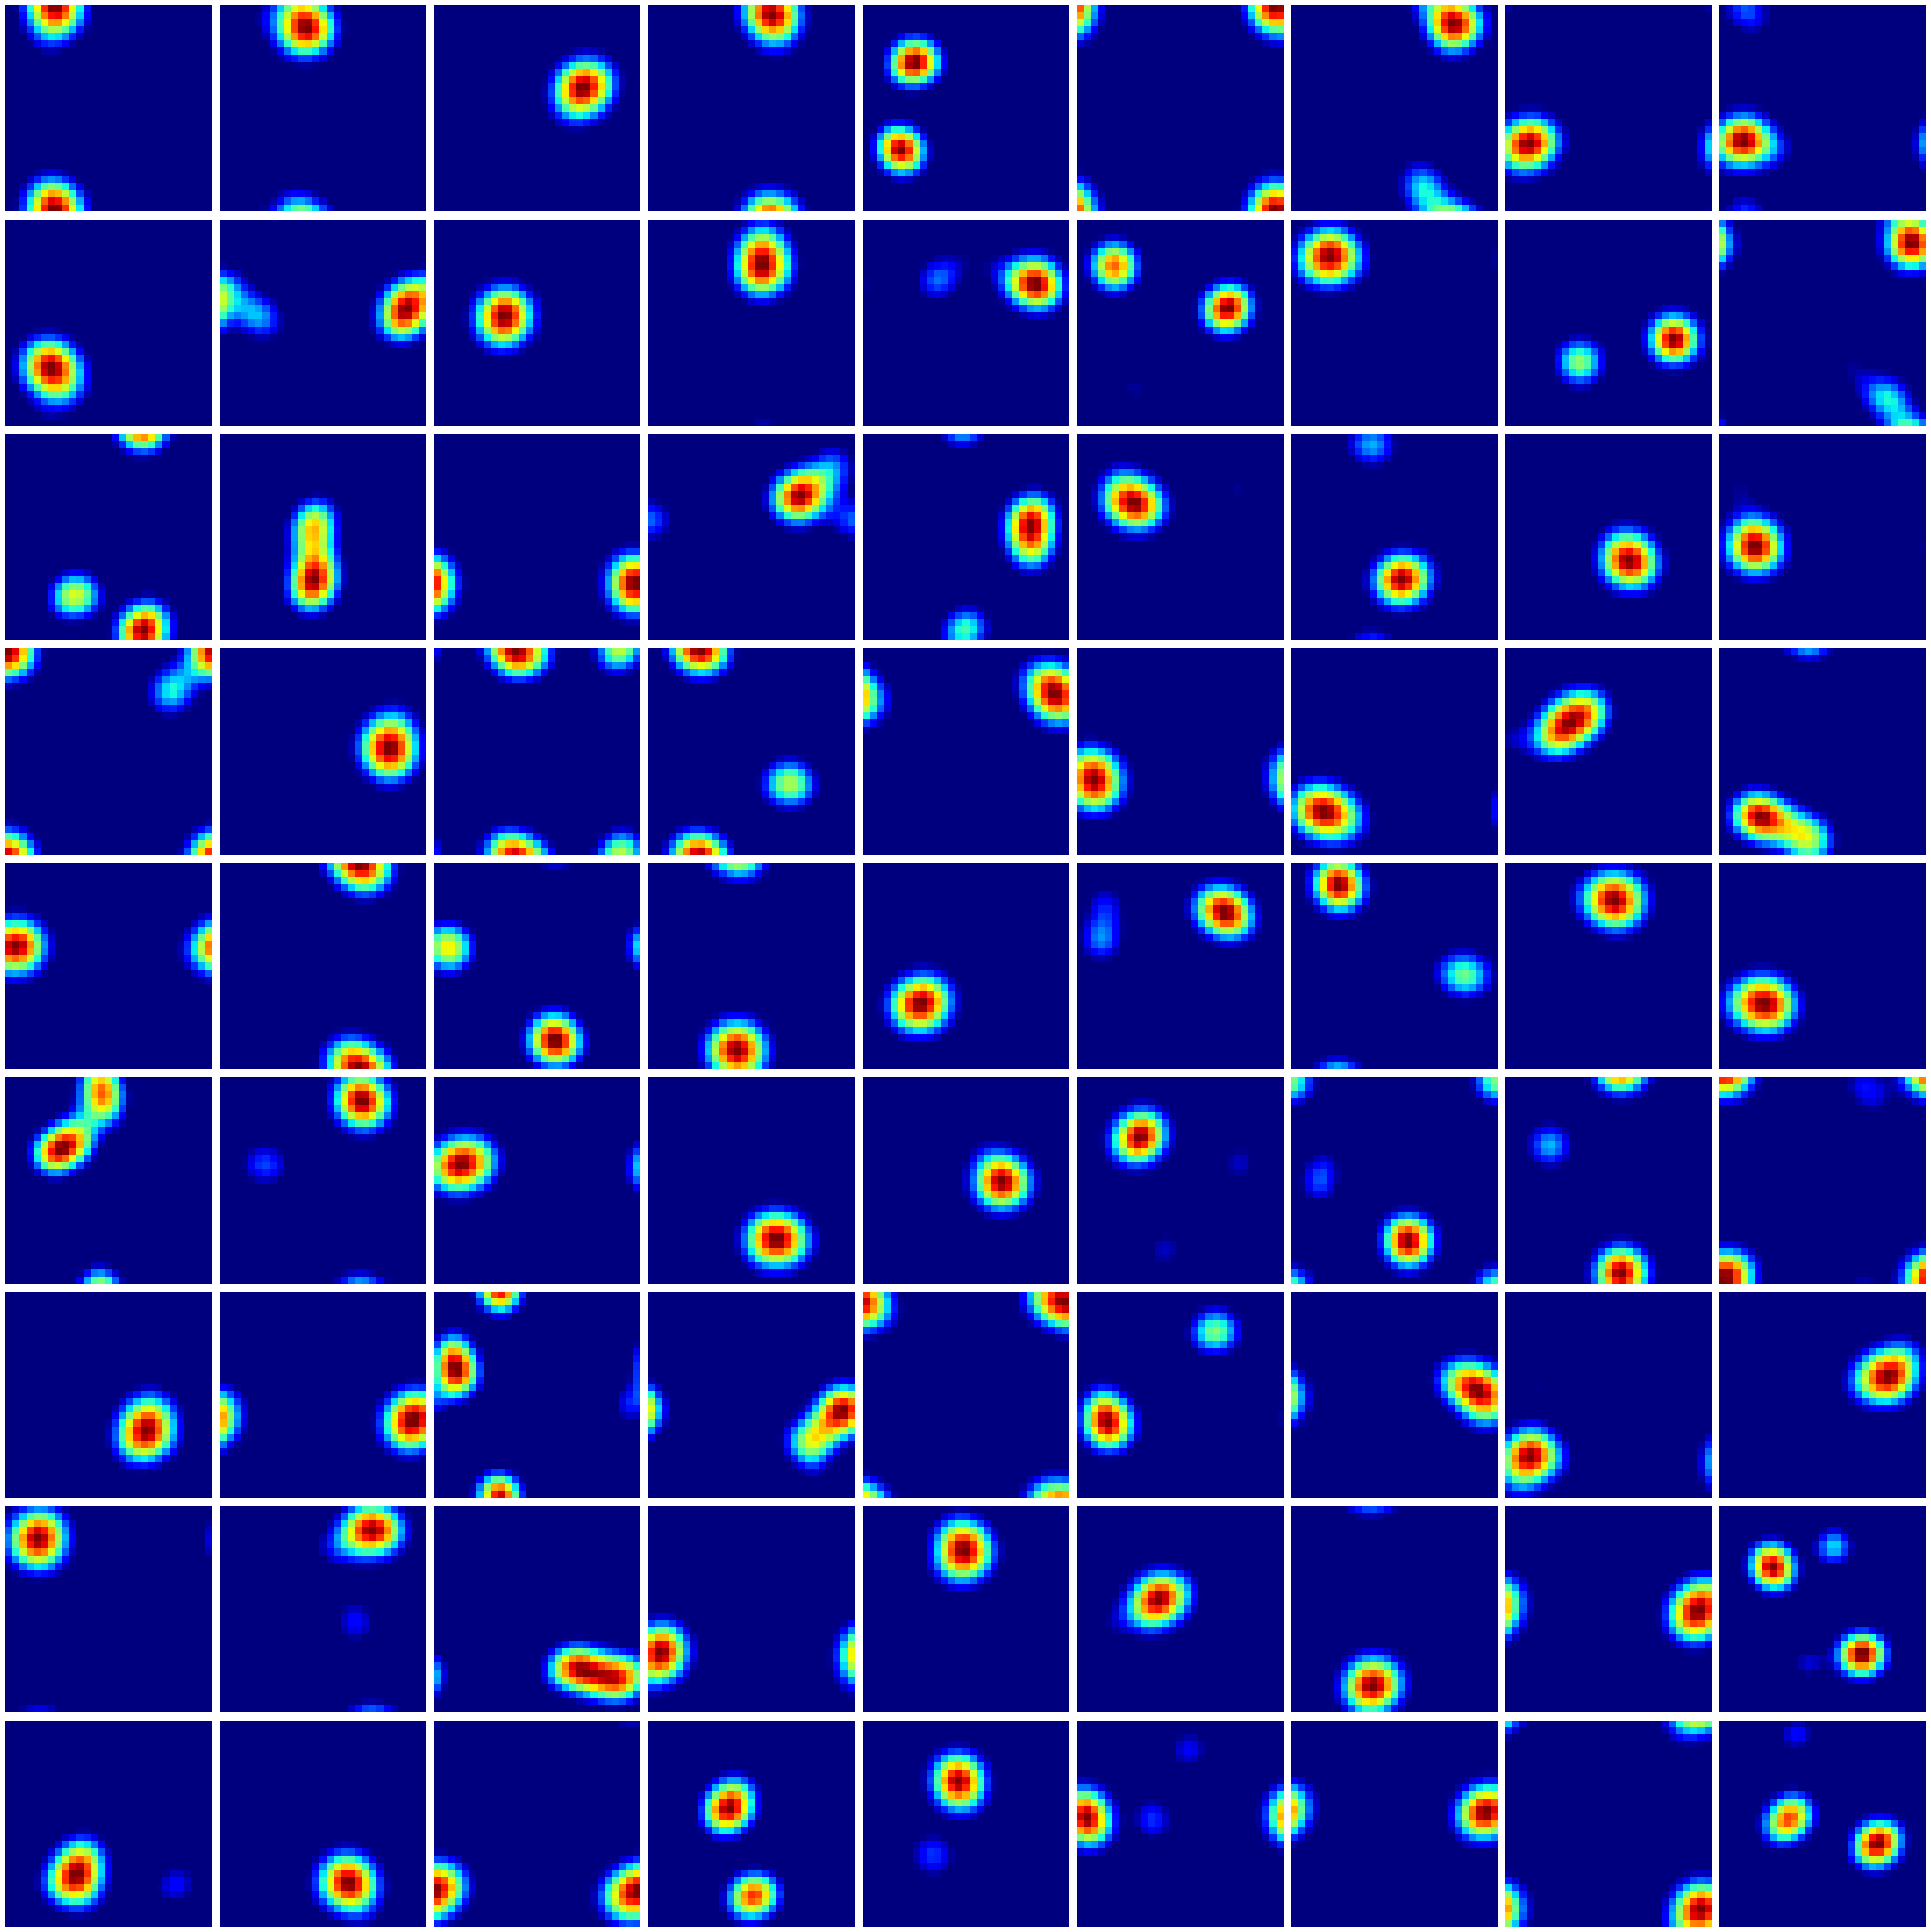

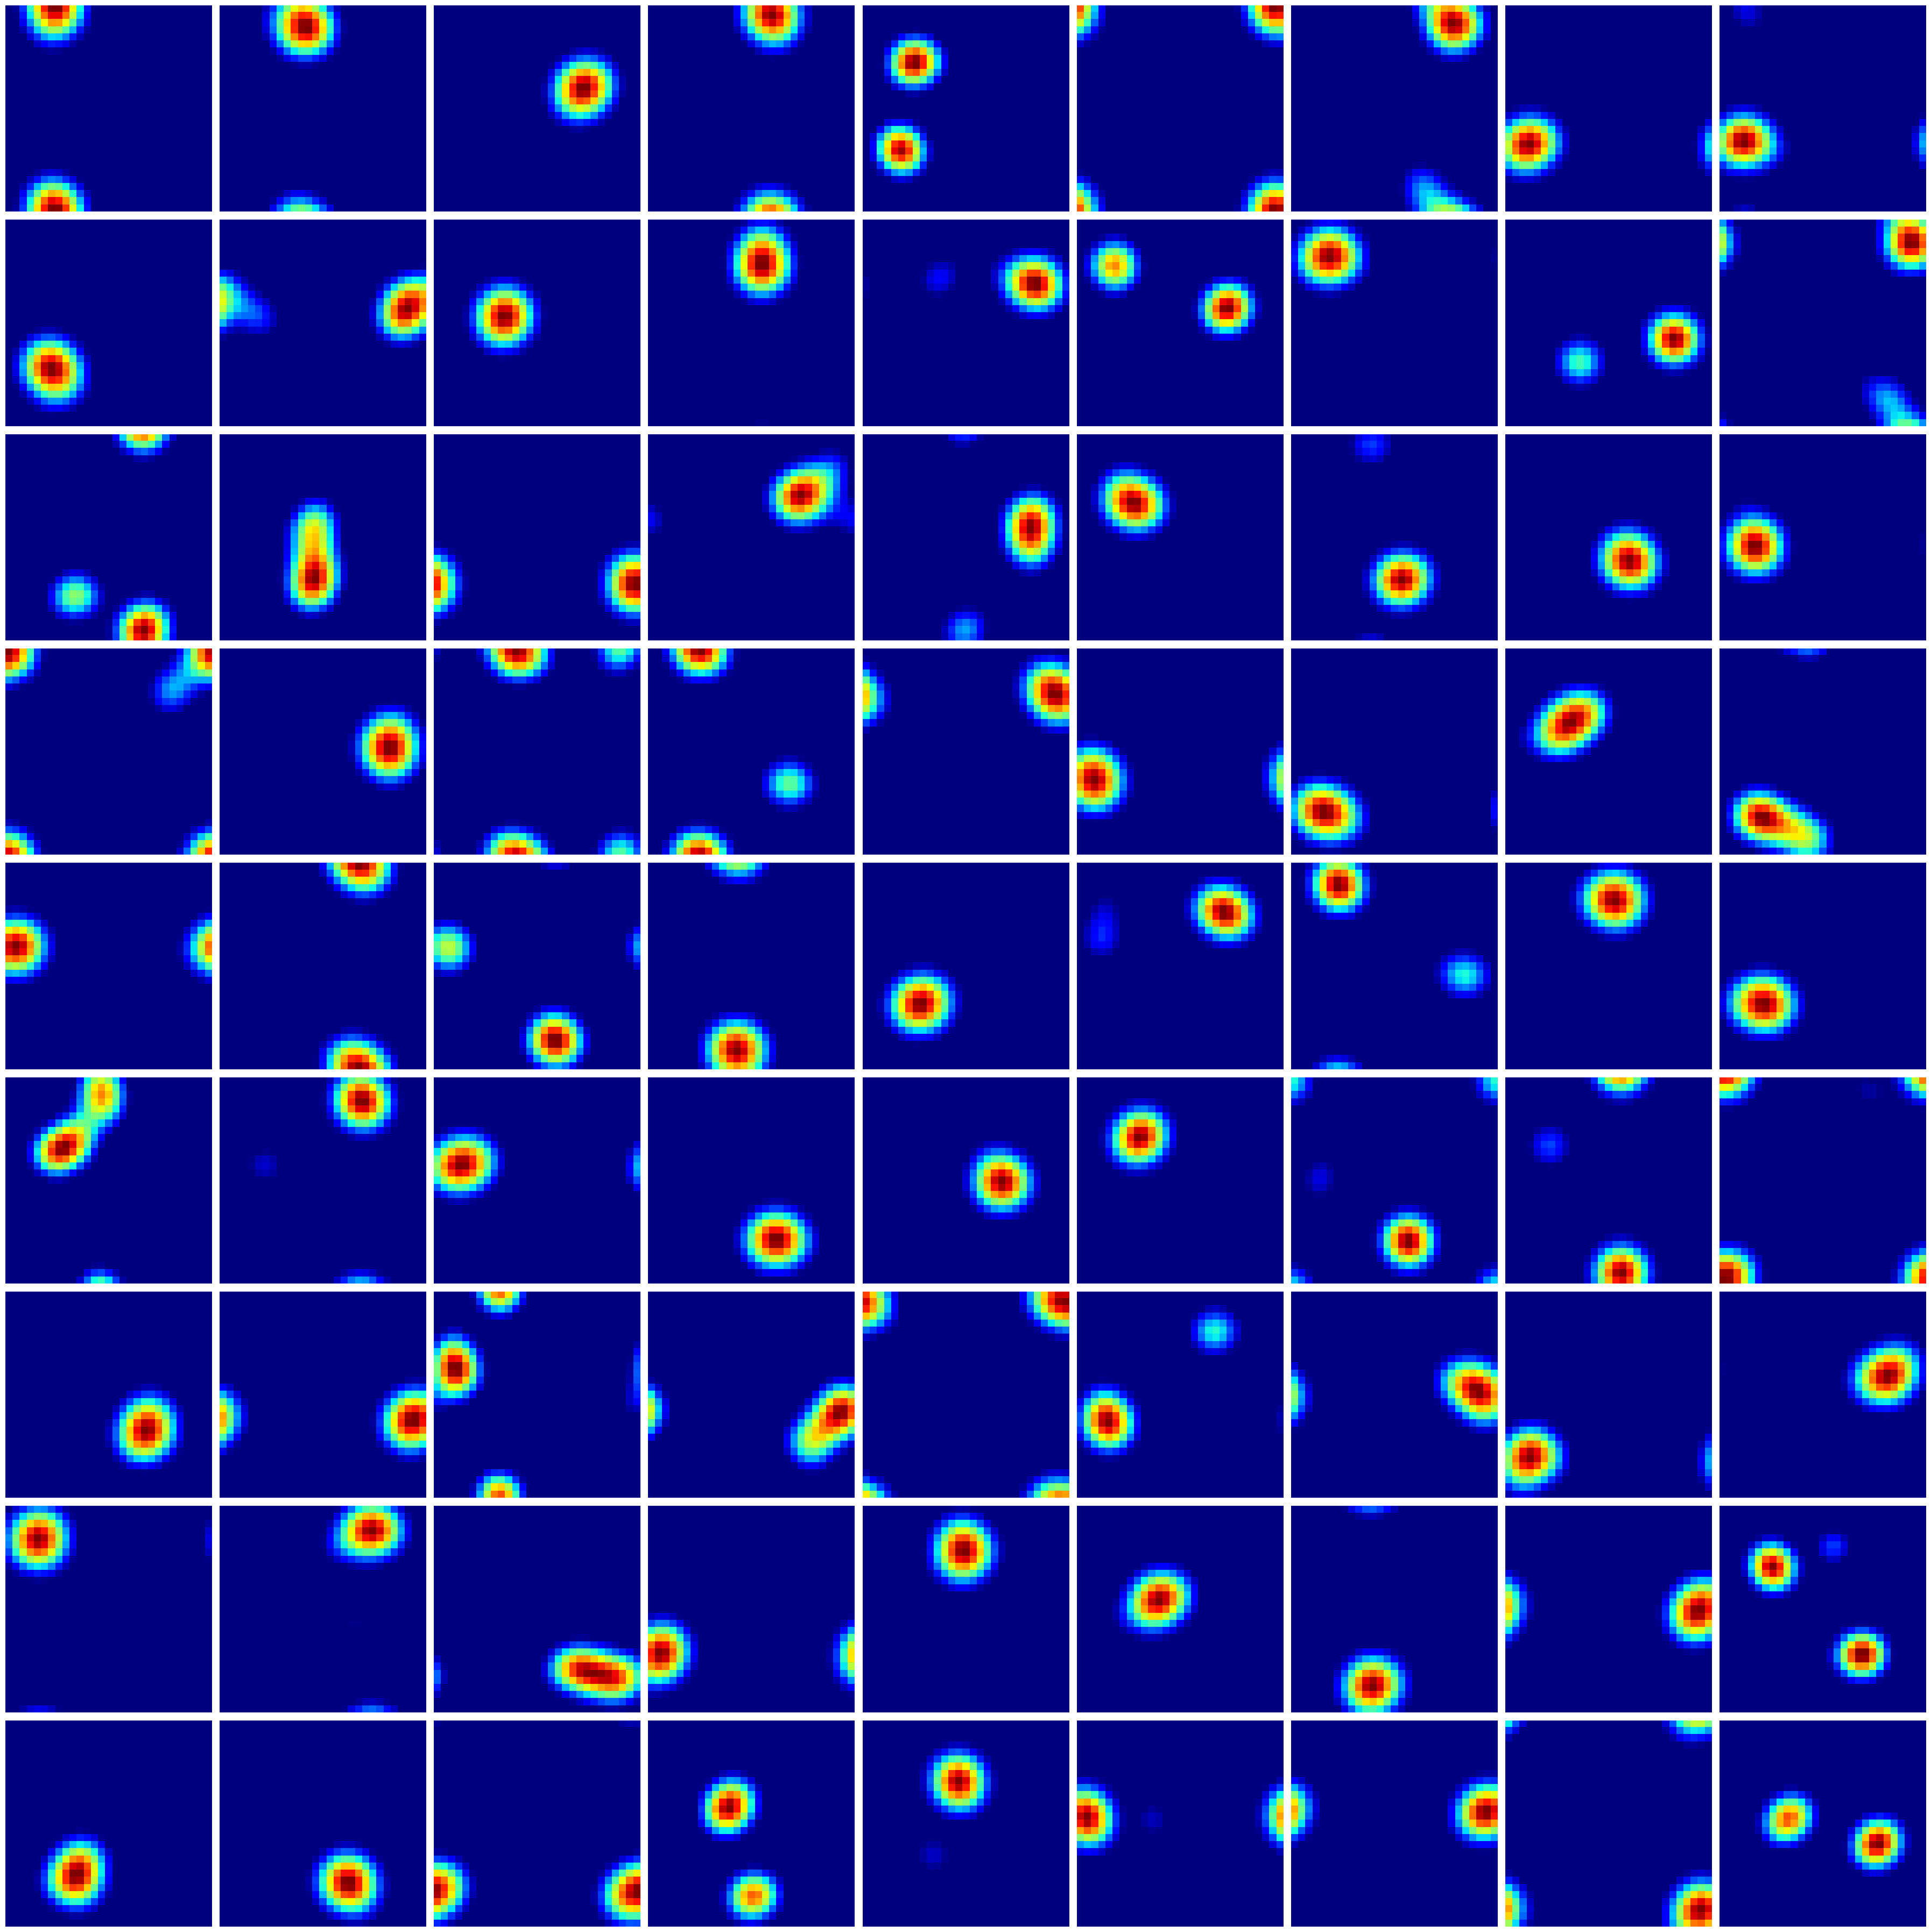

In [44]:
## single cell optimisation ## 
# Symmetry-breaking nonlinearity (relu)

def convolve_with_C(g, Ctilde):
    '''
    Convolves the input g with the kernel C
    '''
    gtilde = np.fft.fft2(g, [res, res])
    gconv = np.real(np.fft.ifft2(gtilde*Ctilde))
    gconv = np.roll(np.roll(gconv, res//2+1, axis=1), res//2+1, axis=2)
    
    return gconv

def relu(x):
    return np.maximum(x,0)

Ng = 9**2
n_plot_rows = int(np.sqrt(Ng))
T = 1000
lr = 5e-3

#NOTE THAT THE VARIABILITY IN ORIENTATION / PHASE DEPENDS ON INITIAL RANDOM SEED
G = np.random.randn(Ng,res,res) * 1e-8
#repeated_init = np.random.randn(res,res)*1e-8
#G = np.stack([ repeated_init for _ in range(Ng)])

for i in range(T):
    G +=lr*(-G + convolve_with_C(G, Ctilde))
    G = relu(G)
    if i%100==99:
        fig, ax = plt.subplots(n_plot_rows,Ng//n_plot_rows, 
                               figsize = (4*Ng//n_plot_rows,4*n_plot_rows))
        for i, axis in enumerate(ax.flatten()):
            axis.imshow(G[i], cmap = 'jet')
            axis.axis('off')
        fig.tight_layout()
        plt.show()
        
    if np.all(np.isnan(G[0])):
        print(f'all NaN at iteration {i}')
        break
            

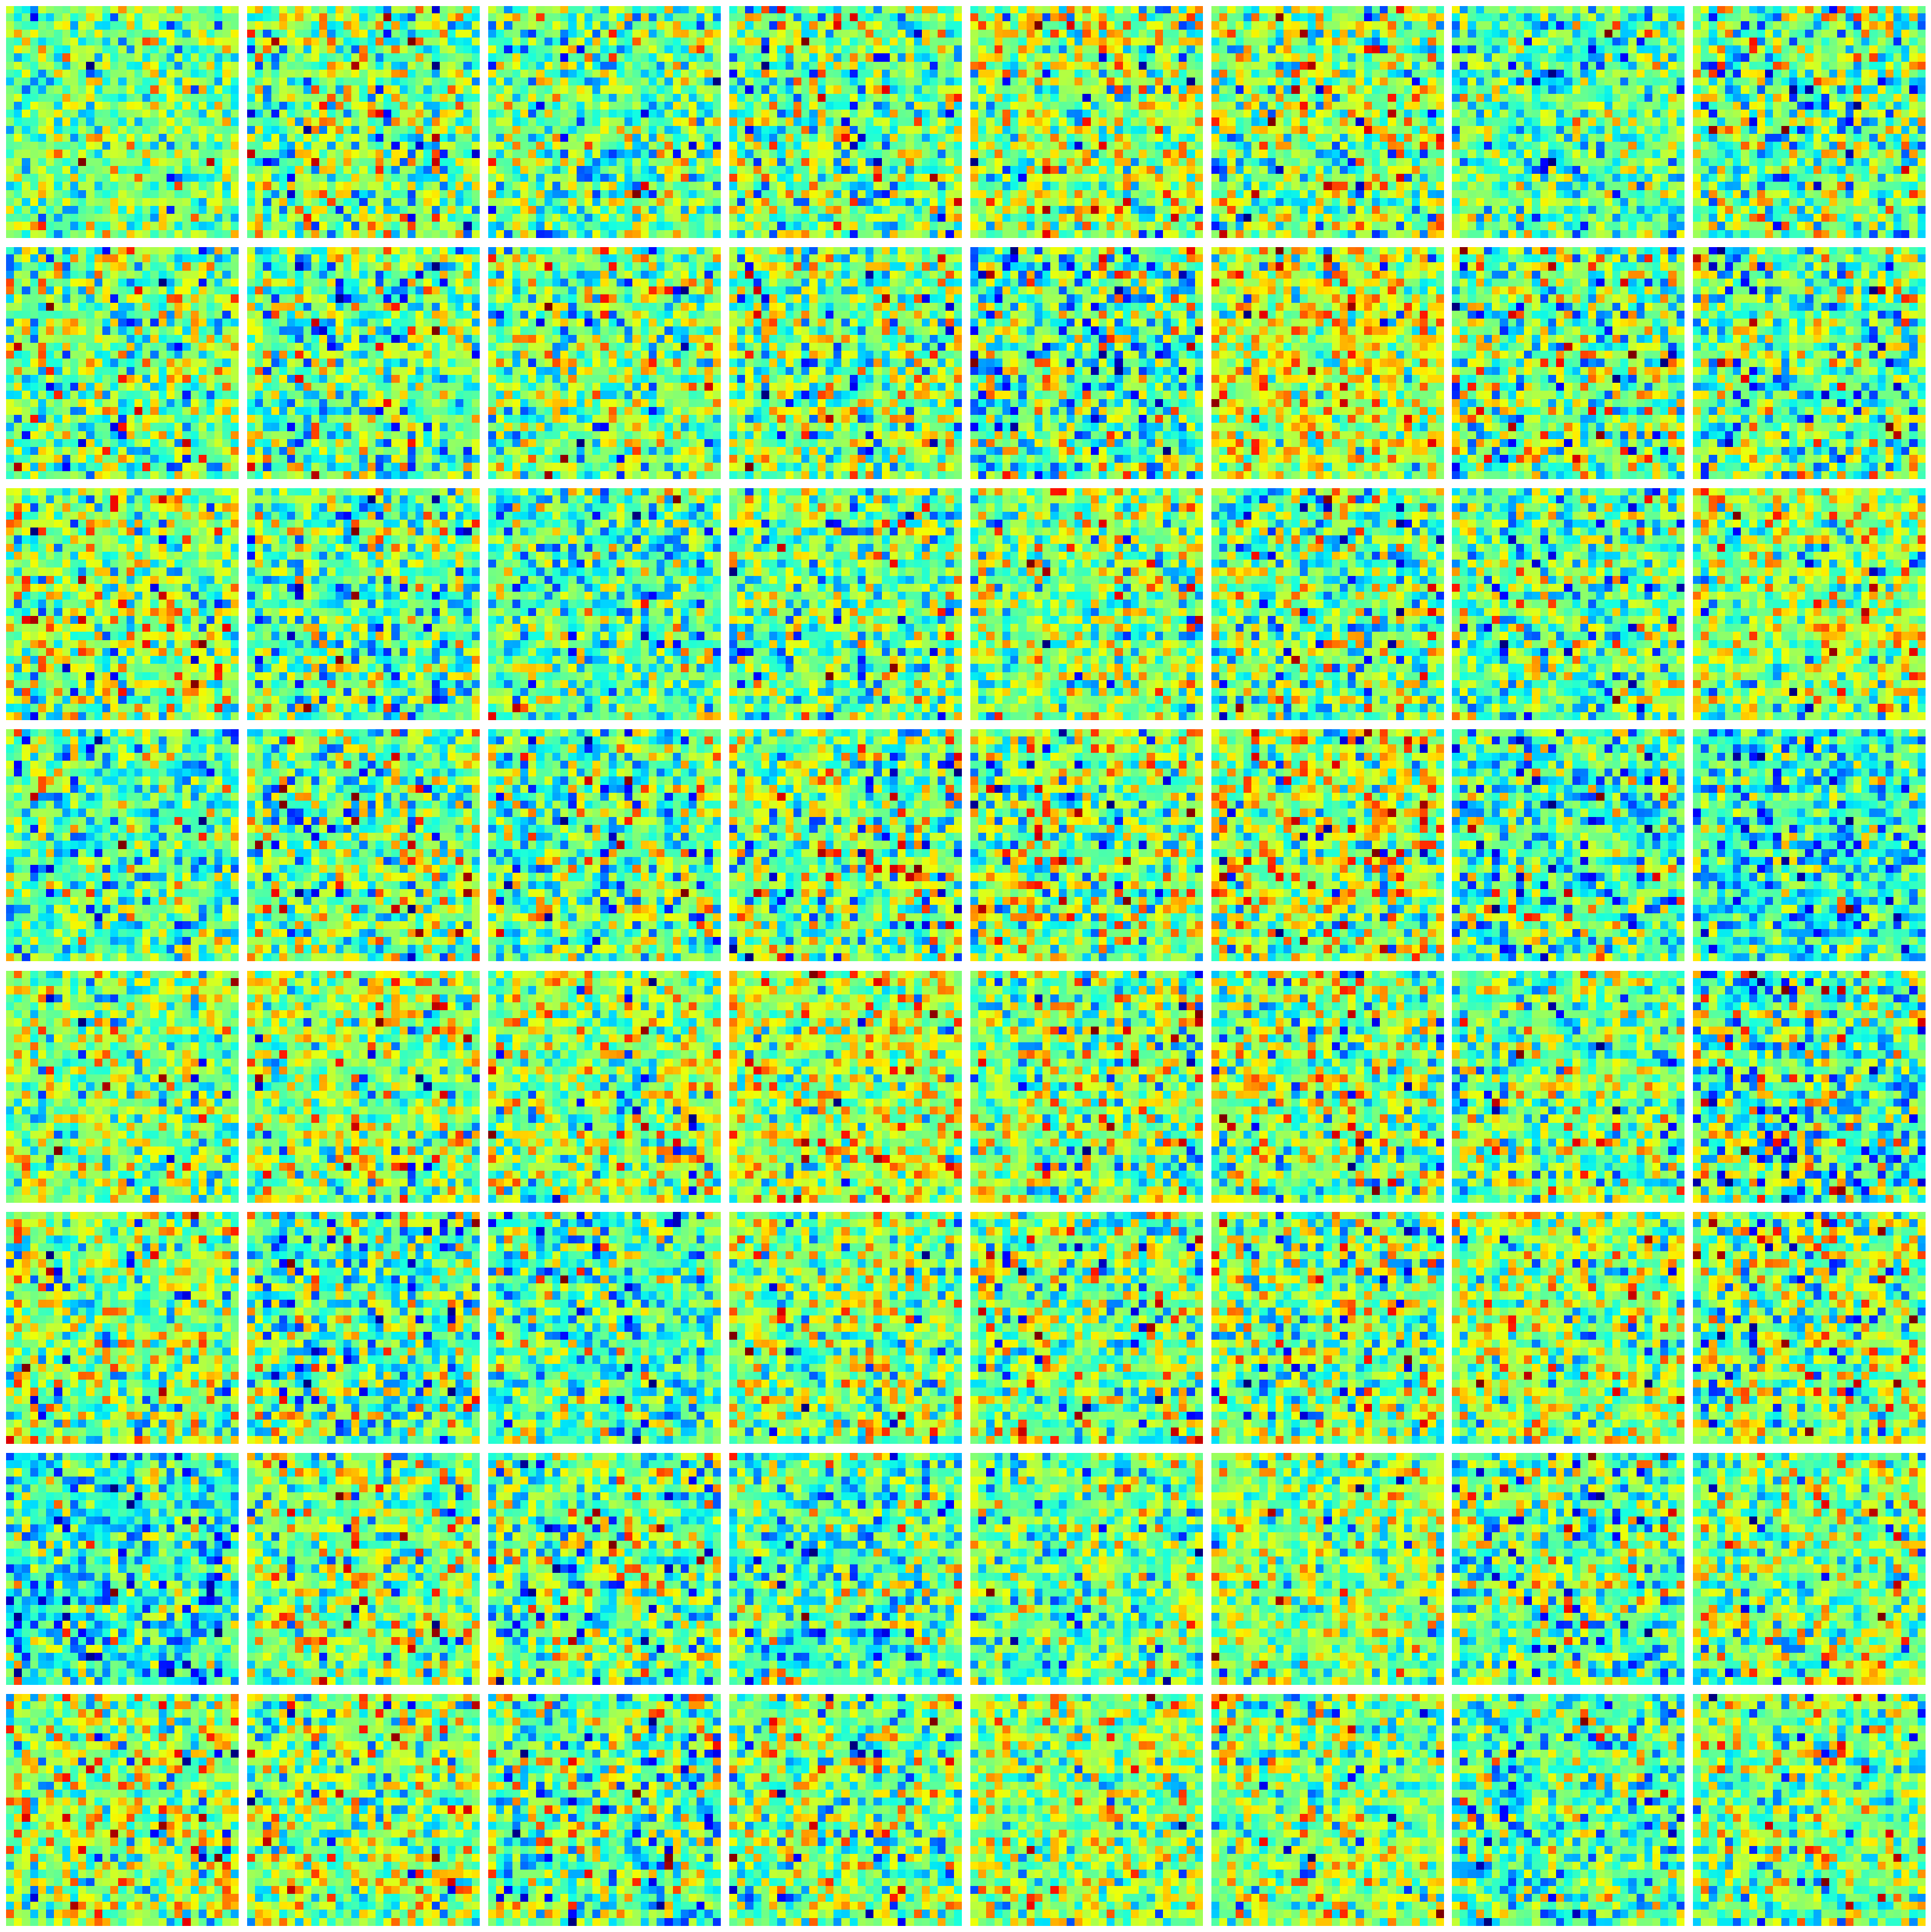

In [10]:
## population optimisation ## 

def phi(x,r):
    return np.maximum(r*x,0)

Ng = 8**2
n_plot_rows = int(np.sqrt(Ng))
r = 30
T = 5000
lr = 1.3e-6
G = np.random.randn(Ng,res,res) * 1e-8
#repeated_init = np.random.randn(res,res)*1e-8
#G = np.stack([ repeated_init for _ in range(Ng)])

for i in range(T):
    H = convolve_with_C(G, Ctilde)
    #H = phi(H,r) #this is not in the original code, but could be helpful to integrate non-negativity in the orthogonalisation penalty?
    Hr = H.reshape([Ng, -1])
    Gr = G.reshape([Ng, -1])
    oja = Gr.T.dot(np.tril(Gr.dot(Hr.T))).T.reshape([Ng,res,res])
    G_relu = phi(G,r)
    #we should balance constraints
    balance_scalar = np.abs(H-oja).max()/np.abs(G_relu).max() # 1 #np.min([H.max(),oja.max()])/G_relu.max() #(np.abs(H-oja).max()/np.abs(G_relu).max())
    G += lr * (H - oja + balance_scalar*G_relu) 
    
    if i%200==199:
        fig, ax = plt.subplots(n_plot_rows,Ng//n_plot_rows, 
                               figsize = (4*Ng//n_plot_rows,4*n_plot_rows))
        for i, axis in enumerate(ax.flatten()):
            axis.imshow(np.flip(G)[i], cmap = 'jet')
            axis.axis('off')
        fig.tight_layout()
        plt.show()
        break
    if np.all(np.isnan(G[0])):
        print(f'all NaN at iteration {i}')
        break

### Successor features (thanks RatInABox)

In [57]:
# we want to make a dataframe with successor features 
# following successor features demo:
import ratinabox as riab
from ratinabox.Neurons import PlaceCells
from ratinabox.contribs.SuccessorFeatures import SuccessorFeatures
from tqdm.auto import tqdm # progress bar
from GridModels.code.models.sorscher_rnn import options

%load_ext autoreload
%autoreload 2

SuccessorFeatures.get_all_default_params()

# set up rat and box
np.random.seed(42) #reproducible place cell locations
box = riab.Environment(params = {'scale':options.environment_scale})
rat = riab.Agent(box, params={"dt":options.framerate})
place_cells = PlaceCells(rat, params = {"n":options.Np,
                                        "description":options.pc_type,
                                        "widths":options.place_cell_rf})
SFs = SuccessorFeatures(rat, params={"features": place_cells,
                                    "input_layers": [place_cells],
                                    'tau':10, #predictive time horizon
                                    'eta':0.01,
                                    })
np.random.seed() #completely random trajectories
true_trajectory = navigation_activity_df # use the same trajectory as previous simulation
for i in tqdm(range(options.n_steps)):
        rat.update()
        if true_trajectory is not None:
            # if we have a real trajectory, we use it to set the rat's position
            rat.history['pos'][-1] = true_trajectory['centroid_position'].values[i]
            rat.history['vel'][-1] = true_trajectory['velocity'].values[i]
            rat.history['head_direction'][-1] = [true_trajectory['head_direction'].x.values[i], true_trajectory['head_direction'].y.values[i]]
        place_cells.update()
        SFs.update()
        SFs.update_weights()    

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


  0%|          | 0/150000 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
# reformat as activity df

import pandas as pd

# now save in a format easy to read and store, consistent with our real data.
nav_rates_dict = {}
nav_rates_dict['time'] = rat.history['t']
nav_rates_dict['centroid_position.x'] = [p[0] for p in rat.history['pos']]
nav_rates_dict['centroid_position.y'] = [p[1] for p in rat.history['pos']]
nav_rates_dict['velocity.x'] = [v[0] for v in rat.history['vel']]
nav_rates_dict['velocity.y'] = [v[1] for v in rat.history['vel']]
nav_rates_dict['head_direction.x'] = [v[0] for v in rat.history['head_direction']]
nav_rates_dict['head_direction.y'] = [v[1] for v in rat.history['head_direction']]
nav_rates_dict['head_direction.degrees'] = np.rad2deg([np.arctan2(v[1],v[0]) for v in rat.history['head_direction']])
for place_cell in range(options.Np):
    nav_rates_dict[f'firingrate.place_cell_{place_cell}'] = [x[place_cell] for x in place_cells.history['firingrate']]
navigation_rates_df = pd.DataFrame(nav_rates_dict)
#make it multicolumn index !
navigation_rates_df.columns = pd.MultiIndex.from_tuples([
    tuple(col.split('.')) if '.' in col else (col, '') 
    for col in navigation_rates_df.columns])

## Maze trajectories


In [11]:
sessions[0].__dict__.keys()

dict_keys(['has_data', 'processed_data_path', 'analysis_data_path', 'session_info', 'name', 'date', 'subject_ID', 'type', 'day_on_maze', 'maze_name', 'experimental_day', 'notes', 'datetime', 'maze_structure', 'goal_set', 'goals', 'reward_size', 'trajectories_df'])

In [ ]:
def flatten_multiindex_columns(df):
    """
    Flattens a pandas DataFrame with MultiIndex columns by joining levels with periods.
    """
    if isinstance(df.columns, pd.MultiIndex):
        df = df.copy()
        df.columns = ['.'.join([str(l) for l in col if l != '']) for col in df.columns.values]
    return df

# Example usage:
# flat_df = flatten_multiindex_columns(navigation_rates_df)
# flat_df.to_csv('output.csv', index=False)

In [18]:
each_session.trajectories_df

time head_direction              centroid_position            \
                             value interpolated                 x         y   
0        -26.739138     109.911324            0          0.111750  1.240421   
1        -26.722470     109.309665            0          0.112366  1.239961   
2        -26.705802     102.099639            0          0.117193  1.235227   
3        -26.689134      97.222293            0          0.117926  1.234059   
4        -26.672466      80.677369            0          0.122834  1.228874   
...             ...            ...          ...               ...       ...   
146684  2418.155217     269.645590            0          1.048922  0.870359   
146685  2418.171885     270.146376            0          1.048354  0.865686   
146686  2418.188553     270.934177            0          1.048120  0.860952   
146687  2418.205221     271.113895            0          1.047968  0.856107   
146688  2418.221889     270.913557            0          1.047932  0.851256   

                    maze_position           
       interpolated        simple skeleton  
0                 0            A7    A7_NW  
1                 0            A7    A7_NW  
2                 0            A7     A7_C  
3                 0            A7     A7_C  
4                 0            A7     A7_C  
...             ...           ...      ...  
146684            0            F5     F5_C  
146685            0            F5     F5_C  
146686            0            F5     F5_C  
146687            0            F5     F5_C  
146688            0            F5     F5_C  

[146689 rows x 8 columns]

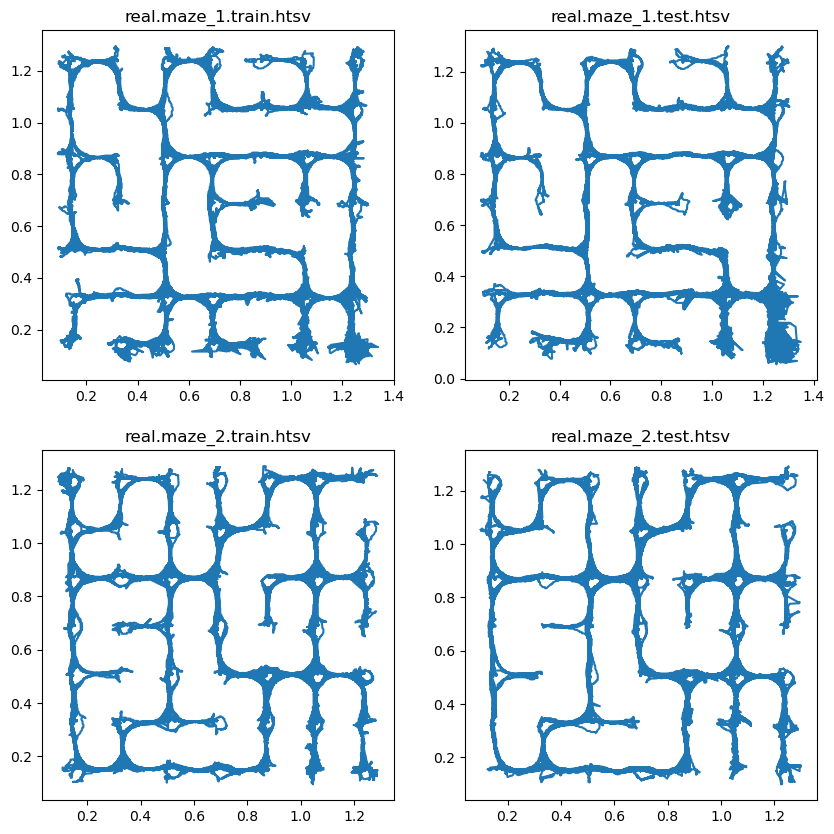

In [ ]:
# code to save out trajectories

from GridMaze.analysis.core import get_sessions as gs
from matplotlib import pyplot as plt
sessions = gs.get_maze_sessions(subject_IDs = ['mEC_2'],maze_names =['maze_1','maze_2'],
                     days_on_maze = [7,8,9,10], goal_subsets = ['all'],
                     with_data = ['navigation_df'])
from pathlib import Path

datapath = Path('./GridModels/data/trajectories')
datapath.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(2,2, figsize=(10,10))
flat_ax = ax.flatten()
for i, each_session in enumerate(sessions):
    pos = each_session.navigation_df.centroid_position.values
    flat_ax[i].plot(pos[:,0], pos[:,1], label=each_session.maze_name)
    
    test_or_train = 'train' if i%2 == 0 else 'test'
    filepath = datapath/ f'real.{each_session.maze_name}.{test_or_train}.htsv'
    flat_ax[i].set_title(f'{filepath.name}')
    
    df = each_session.navigation_df.copy()
    df[('head_direction','x')] = np.cos(np.deg2rad(df[('head_direction','value')]))
    df[('head_direction','y')] = np.sin(np.deg2rad(df[('head_direction','value')]))
    df = df[['time','centroid_position','velocity','head_direction','maze_position']]

    df.columns = ['.'.join([str(l) for l in col if l != '']) for col in df.columns.values]
    df = df[df['time']>0]
    df.to_csv(filepath, sep='\t', index=False)
    

In [52]:
df

,time,centroid_position.x,centroid_position.y,velocity.x,velocity.y,head_direction.value,head_direction.x,head_direction.y,maze_position.simple,maze_position.skeleton
1605,0.013000,1.264110,0.123753,0.003984,-0.050882,263.080992,-0.120466,-0.992717,G1,G1_SE
1606,0.029725,1.264116,0.123745,0.002934,-0.033458,262.790059,-0.125505,-0.992093,G1,G1_SE
1607,0.046449,1.264174,0.123626,0.001245,-0.018553,262.744621,-0.126292,-0.991993,G1,G1_SE
1608,0.063174,1.264209,0.123549,-0.000198,-0.010432,262.652060,-0.127894,-0.991788,G1,G1_SE
1609,0.079899,1.264174,0.123472,-0.000793,-0.007011,262.751079,-0.126180,-0.992007,G1,G1_SE
...,...,...,...,...,...,...,...,...,...,...
146684,2418.155217,1.048922,0.870359,-0.099778,-0.268772,260.862547,-0.158803,-0.987310,F5,F5_C
146685,2418.171885,1.048354,0.865686,-0.059038,-0.253326,261.412492,-0.149320,-0.988789,F5,F5_C
146686,2418.188553,1.048120,0.860952,-0.028408,-0.205985,262.317531,-0.133683,-0.991024,F5,F5_C
146687,2418.205221,1.047968,0.856107,-0.010482,-0.118168,262.369595,-0.132782,-0.991145,F5,F5_C


In [ ]:
from GridModels.code.models import sorscher_rnn as srnn
reload(srnn)
srnn.get_trajectory()

Using device: cuda
Trajectory not yet saved. Generating from scratch


  0%|          | 0/150000 [00:00<?, ?it/s]

 42%|████▏     | 62489/150000 [01:04<01:30, 968.59it/s]

In [ ]:
import numpy as np
import pandas as pd

multi_df = df.copy()
multi_df.columns = pd.MultiIndex.from_tuples(
    [col.split('.') if '.' in col else (col,'') for col in df.columns]
)
multi_df[['time','centroid_position','velocity','head_direction','maze_position']]
multi_df

time           subject_name maze_name day_on_maze  \
                                                                   
0        -26.739138  mEC_2.2024-03-31.maze    maze_2          10   
1        -26.722470  mEC_2.2024-03-31.maze    maze_2          10   
2        -26.705802  mEC_2.2024-03-31.maze    maze_2          10   
3        -26.689134  mEC_2.2024-03-31.maze    maze_2          10   
4        -26.672466  mEC_2.2024-03-31.maze    maze_2          10   
...             ...                    ...       ...         ...   
146684  2418.155217  mEC_2.2024-03-31.maze    maze_2          10   
146685  2418.171885  mEC_2.2024-03-31.maze    maze_2          10   
146686  2418.188553  mEC_2.2024-03-31.maze    maze_2          10   
146687  2418.205221  mEC_2.2024-03-31.maze    maze_2          10   
146688  2418.221889  mEC_2.2024-03-31.maze    maze_2          10   

       trial_unique_ID trial trial_phase goal head_direction  \
                                                       value   
0                  NaN   NaN         NaN  NaN     109.911324   
1                  NaN   NaN         NaN  NaN     109.309665   
2                  NaN   NaN         NaN  NaN     102.099639   
3                  NaN   NaN         NaN  NaN      97.222293   
4                  NaN   NaN         NaN  NaN      80.677369   
...                ...   ...         ...  ...            ...   
146684             NaN   NaN         NaN  NaN     260.862547   
146685             NaN   NaN         NaN  NaN     261.412492   
146686             NaN   NaN         NaN  NaN     262.317531   
146687             NaN   NaN         NaN  NaN     262.369595   
146688             NaN   NaN         NaN  NaN     263.443796   

       centroid_position  ... distance_to_goal           progress_to_goal  \
                       x  ...           future manhattan      path_length   
0               0.111750  ...              NaN       NaN              NaN   
1               0.112366  ...              NaN       NaN              NaN   
2               0.117193  ...              NaN       NaN              NaN   
3               0.117926  ...              NaN       NaN              NaN   
4               0.122834  ...              NaN       NaN              NaN   
...                  ...  ...              ...       ...              ...   
146684          1.048922  ...              NaN       NaN              NaN   
146685          1.048354  ...              NaN       NaN              NaN   
146686          1.048120  ...              NaN       NaN              NaN   
146687          1.047968  ...              NaN       NaN              NaN   
146688          1.047932  ...              NaN       NaN              NaN   

            angle_to_goal            (head_direction, test) head_direction  \
       time   allocentric egocentric                                     x   
0       NaN           NaN        NaN                    0.0      -0.340565   
1       NaN           NaN        NaN                    0.0      -0.330674   
2       NaN           NaN        NaN                    0.0      -0.209612   
3       NaN           NaN        NaN                    0.0      -0.125719   
4       NaN           NaN        NaN                    0.0       0.161994   
...     ...           ...        ...                    ...            ...   
146684  NaN           NaN        NaN                    0.0      -0.158803   
146685  NaN           NaN        NaN                    0.0      -0.149320   
146686  NaN           NaN        NaN                    0.0      -0.133683   
146687  NaN           NaN        NaN                    0.0      -0.132782   
146688  NaN           NaN        NaN                    0.0      -0.114178   

                       
               y test  
0       0.940221  0.0  
1       0.943745  0.0  
2       0.977785  0.0  
3       0.992066  0.0  
4       0.986792  0.0  
...          ...  ...  
146684 -0.987310  0.0  
146685 -0.988789  0.0  
146686 -0.991024  0.0  
146687 -0.991145

In [34]:
df.columns

Index(['time', 'subject_name', 'maze_name', 'day_on_maze', 'trial_unique_ID',
       'trial', 'trial_phase', 'goal', 'head_direction.value',
       'centroid_position.x', 'centroid_position.y', 'maze_position.simple',
       'maze_position.skeleton', 'velocity.x', 'velocity.y', 'speed', 'moving',
       'action.basic', 'action.choice_degree', 'cardinal_movement_direction',
       'distance_to_goal.geodesic', 'distance_to_goal.euclidean',
       'distance_to_goal.future', 'distance_to_goal.manhattan',
       'progress_to_goal.path_length', 'progress_to_goal.time',
       'angle_to_goal.allocentric', 'angle_to_goal.egocentric',
       'head_direction.x', 'head_direction.y'],
      dtype='object')